# Project Overview

## Introduction (background of the study)

The Department of Tourism (DOT) tracks foreign visitor arrivals to the Philippines across regional groupings such as ASEAN, East/Northeast Asia, and South Asia (Philippine Statistics Authority [PSA], 2025). Asian markets are the country's largest source of foreign visitors, making up 67.9% of foreign arrivals in 2019 and 53.6% in 2024 (PSA, 2025).

However, DOT's published tables only show **how many** visitors arrive. They do not show **who** today's traveler is: their age, why they travel, how interested they are before visiting, and what they experience once they arrive. This makes it hard for tourism offices to plan marketing, services, and infrastructure around the markets that actually exist today.

**LakbAI** uses Big Data tools (Apache Spark and PySpark) to combine official statistics, Google search data, and visitor reviews into one up-to-date profile of Asian tourist markets in the Philippines. The study supports UN Sustainable Development Goal 8 (Target 8.9, sustainable tourism) and Goal 12 (Target 12.b, tools to monitor sustainable tourism) (United Nations, 2015).

## Problem Statement

While DOT publishes national and country-level arrival statistics, there is no consolidated, data-driven profile connecting who travels from each Asian market — their demographics and travel purpose — with how they behave: their pre-visit digital interest, their experiences at major Philippine destinations, how tourism demand is distributed and concentrated across markets, and whether that demand is approaching accommodation capacity. This limits the ability of tourism stakeholders to design evidence-based, market-specific strategies and to monitor emerging risks in the country's tourism demand base.

## Research Questions

**RQ0 (Overarching):** What do regression, classification, clustering, and association patterns collectively reveal about Asian tourist markets in the Philippines today, and how can these findings inform sustainable, market-specific tourism planning aligned with SDG 8 and SDG 12?

**RQ1 (Regression):** To what extent can a market's average relative search-interest level for Philippine travel, self-normalized to that market's own 2024 search activity, be predicted using its age-group and purpose-of-travel composition?
- **RQ1a:** Within this self-normalized framing, which composition factor, age or purpose, shows a stronger association with elevated relative search interest?

**RQ2 (Classification):** Can Asian source markets' dominant purpose-of-travel segment (e.g., Holiday-dominant, Business-dominant, VFR-dominant) be predicted from their age-group composition alone?
- **RQ2a:** Which age groups most distinguish markets in each purpose-defined segment?

**RQ3 (Clustering):** What natural visitor-persona groupings emerge when Asian source markets are clustered by their age-group and purpose-of-travel distributions?
- **RQ3a:** Do these data-driven clusters align with the existing ASEAN / East Asia / South Asia groupings, or reveal different and potentially more useful groupings for tourism planning?

**RQ4 (Association Rule Mining):** What frequent associations exist among age-group levels, purpose-of-travel levels, regional grouping, and relative search-interest level across Asian source markets?
- **RQ4a:** Are specific age–purpose combinations strongly concentrated within particular regional groupings or search-interest levels?

## Scope and Delimitation

- The study covers **21 Asian source markets**: ASEAN (9), Northeast Asia (6), and South Asia (6), following DOT's regional groupings (PSA, 2025). Middle Eastern and non-Asian markets are not included. This scope was chosen to keep the study focused and doable within one term, and it was confirmed with the course instructor.
- The main analysis (RQ1–RQ4) uses **2024 data at the country level**.
- The supplementary analyses use national yearly data (2003–2024), yearly Metro Manila hotel occupancy (2000–2023), and past visitor reviews (2006–2014) for five major destinations. These are reported descriptively.
- Findings apply to Asian markets only and should not be generalized to all foreign visitors.

## Datasets

- **Philippine Statistical Yearbook (PSY) 2025, DOT Tables 8.1–8.6** (PSA, 2025): arrivals by country, mode of travel, age group, purpose of travel, spending and length of stay, and Metro Manila hotel occupancy.
- **Google Trends** (Google, n.d.): average 2024 search interest in Philippine travel for each country.
- **UCSD Google Local Reviews** (He et al., 2017; Pasricha & McAuley, 2018): Google Maps reviews for Manila, Cebu, Boracay, Palawan, and Bohol.
- **PSA Household Survey on Domestic Visitors, 2022** (PSA, 2023): domestic travel patterns for comparison.
- **Philippine entry requirements** (Department of Foreign Affairs [DFA], n.d.): 2024 visa status per country.
- **PSA Philippine Tourism Satellite Account** (PSA, 2025): national background context.

All raw files are in the `Datasets` folder in Google Drive. The cleaned, analysis-ready files are saved in the `Preprocessed` folder.

## Methodology

Data work is done in **Apache Spark using PySpark** (Zaharia et al., 2016), with models from Spark's MLlib (Meng et al., 2016) unless stated otherwise.

1. **Setup:** install PySpark, connect Google Drive, and start Spark.
2. **Data Preprocessing:** clean every raw file, create new features, build one master country table, prepare one dataset per research question and supplementary analysis, check the results against reference files, and save them.
3. **General EDA:** check data quality and look at overall patterns.
4. **Each research question follows six steps:** EDA → Model Setup → Train and Tune → Evaluation → Interpretation → Insights.
   - **RQ1 Regression:** Ridge Regression (main), Elastic Net, PLS Regression, and Random Forest, tested with leave-one-country-out cross-validation, a permutation test, and RMSE, MAE, R², and Spearman ρ. Spark prepares the data. Most model fitting uses scikit-learn (Pedregosa et al., 2011), because the tests need thousands of tiny fits on 21 rows, which Spark's per-job overhead makes very slow. The main Ridge model is also refit in Spark MLlib with `CrossValidator` as a cross-check.
   - **RQ2 Classification:** Logistic Regression, Decision Tree, Random Forest, and Multilayer Perceptron in Spark MLlib, plus hard and soft voting ensembles, tested with leave-one-country-out cross-validation, `CrossValidator` tuning, and a permutation test, and scored with accuracy, macro F1, and balanced accuracy.
   - **RQ3 Clustering:** K-Means and Bisecting K-Means, judged with WSSSE (elbow method) and the silhouette score (Rousseeuw, 1987).
   - **RQ4 Association Rule Mining:** FP-Growth (Han et al., 2000), judged with support, confidence, and lift.
5. **Supplementary Analyses** follow three steps: EDA → Analysis → Insights. They use simple Spark aggregations only: market concentration (Herfindahl-Hirschman Index), hotel capacity, stay and spending trends, domestic vs. international travelers, keyword-based review satisfaction (Hu & Liu, 2004), popular activities, and entry policy (Neumayer, 2010).
6. **Synthesis:** combine all results to answer RQ0.

# Setup

This section gets the workspace ready: it installs PySpark, connects Google Drive, starts Spark, and sets up the folder paths and helper tools used in the rest of the notebook.

### Installing PySpark
This installs PySpark. If Colab already has it, the step finishes almost right away.

In [3]:
# Install PySpark (skipped quickly if Colab already has it)
!pip install -q pyspark

### Connecting Google Drive
The datasets are stored in a shared Google Drive folder. Connecting (mounting) the drive lets the notebook read those files.

On your own computer this step is skipped, and the notebook reads the `data/` folder of this repository instead.

In [4]:
# Connect Google Drive (only in Google Colab; on your own computer the data is read from ../data)
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


Mounted at /content/drive


### Starting Spark and Setting Folder Paths
This step loads the libraries, starts Spark, and saves the location of each Drive folder in a variable.

**Why:** every folder path is built from one variable, `BASE`. If the folder ever moves, only one line needs to change. The step also checks that every folder can be found.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = SparkSession.builder.appName("LakbAI-Preprocessing").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

# ---- Paths: update BASE only if the Datasets folder is stored elsewhere in Drive ----
BASE = ("/content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets"
        if IN_COLAB else "../data")
DOT  = f"{BASE}/Dept of Tourism Tables"
REG  = f"{BASE}/Regression"
CLC  = f"{BASE}/Clustering and Classification"
ARM  = f"{BASE}/Association Rule Mining"
SUP  = f"{BASE}/Supplementary"
OUT  = f"{BASE}/Preprocessed"

for folder in [DOT, REG, CLC, ARM, SUP, OUT]:
    print(("OK      " if os.path.isdir(folder) else "MISSING ") + folder)

OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Dept of Tourism Tables
OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Regression
OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Clustering and Classification
OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Association Rule Mining
OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Supplementary
OK      /content/drive/MyDrive/3rd Year Documents/3rd year Final Project Deliverables/DS 011 - Big Data/Datasets/Preprocessed


If any folder shows **MISSING**, the `BASE` path does not match where the `Datasets` folder is in Google Drive, and it must be fixed before going on.

### Project Settings and Helper Tools
This step sets up the information and small tools used throughout the notebook:
- the 21 countries in the study and their DOT region
- `NAME_FIX`, which turns the three country names spelled differently across DOT tables (China, Hong Kong, Macau) into one plain name
- the names of the age-group and purpose-of-travel columns
- helper tools that turn text numbers into real numbers, clean up country names, remove hidden characters from column names, read CSV files, and save results

**Why:** writing these once and reusing them keeps every step consistent and avoids repeating the same code.

In [6]:
# ---- Project constants ----
REGIONS = {
    "ASEAN": ["Brunei Darussalam", "Cambodia", "Indonesia", "Lao PDR", "Malaysia",
              "Myanmar", "Singapore", "Thailand", "Vietnam"],
    "Northeast_Asia": ["China", "Hong Kong", "Japan", "South Korea", "Macau", "Taiwan"],
    "South_Asia": ["Bangladesh", "India", "Iran", "Nepal", "Pakistan", "Sri Lanka"],
}
COUNTRIES_21 = [c for group in REGIONS.values() for c in group]

# Spellings in the raw DOT tables that differ from the plain names used in this study
NAME_FIX = {"China (PROC)": "China", "Hong Kong - SAR": "Hong Kong",
            "Hong Kong - Sar": "Hong Kong", "Macau - SAR": "Macau"}

AGE_COLS = ["under15", "15_19", "20_24", "25_34", "35_44", "45_54", "55_64", "65plus"]
PURPOSE_COLS = ["holiday", "business", "official_mission", "convention", "vfr",
                "incentive", "health_medical", "education", "others"]

# ---- Helper functions ----
def clean_number(col_name):
    """Text like '  1,569,071 ' -> 1569071.0 ; '-' or blank -> 0.0"""
    s = F.regexp_replace(F.trim(F.col(col_name)), ",", "")
    return F.when((s == "-") | (s == "") | s.isNull(), F.lit(0.0)).otherwise(s.cast("double"))

def fix_country(col):
    """Trim spaces and apply NAME_FIX."""
    name = F.trim(col)
    fix_map = F.create_map(*[F.lit(x) for kv in NAME_FIX.items() for x in kv])
    return F.coalesce(fix_map[name], name)

def clean_headers(df):
    """Remove hidden characters (e.g., a byte-order mark) and spaces from column names."""
    return df.toDF(*[c.replace("\ufeff", "").strip() for c in df.columns])

def read_clean_csv(path, **opts):
    return clean_headers(spark.read.csv(path, header=True, inferSchema=True, **opts))

def save_csv(df, name):
    """Save a small Spark DataFrame as ONE clean CSV in the Preprocessed folder."""
    path = f"{OUT}/{name}"
    df.toPandas().to_csv(path, index=False)
    print(f"Saved {name}: {df.count()} rows x {len(df.columns)} columns")

region_df = spark.createDataFrame([(c, r) for r, cs in REGIONS.items() for c in cs], ["country", "region"])
print(len(COUNTRIES_21), "countries")

21 countries


# Data Preprocessing

This section turns the raw files into clean, ready-to-use datasets in seven steps:
1. Load and look at the raw data
2. Clean each source and create new features
3. Build one master table with all countries
4. Prepare one dataset for each research question
5. Prepare the datasets for the supplementary analyses
6. Check the results against the reference files
7. Save everything to the `Preprocessed` folder

### Loading and Looking at the Raw Data

The DOT tables come in two styles:
- **Clean tables (8.1, 8.2, 8.6):** one header row, plus a `row_type` column (`country`, `subtotal`, or `grand_total`) where needed.
- **Raw yearbook tables (8.3, 8.4, 8.5):** title rows, headers split across several lines, numbers saved as text with commas, and region names mixed in with country names. These need special handling.

This step lists every raw file and confirms each one can be found.

In [7]:
raw_files = {
    "8.1 arrivals":       f"{DOT}/dot_8.1_arrivals_by_country_2019-2024.csv",
    "8.2 mode":           f"{DOT}/dot_8.2_mode_by_country_2022-2024.csv",
    "8.3 age (raw)":      f"{DOT}/dot_8.3_age_by_country_and_national_2024.csv",
    "8.4 purpose (raw)":  f"{DOT}/dot_8.4_purpose_by_country_and_national_2024.csv",
    "8.5 spend/stay (raw)": f"{DOT}/dot_8.5_expenditure_stay_national_monthly2024.csv",
    "8.6 hotel occupancy": f"{DOT}/dot_8.6_hotel_occupancy_ncr_2000-2023.csv",
    "search interest":    f"{REG}/search_interest_by_country.csv",
    "entry policy":       f"{SUP}/entry_policy_index.csv",
    "HSDV":               f"{SUP}/hsdv_2022_domestic_visitors_clean.csv",
    "seasonal demand":    f"{SUP}/seasonal_demand_G_joined_2024.csv",
    "visitor reviews":    f"{SUP}/visitor_experience_sentiment.csv",
}
for name, path in raw_files.items():
    exists = os.path.exists(path)
    rows = spark.read.text(path).count() if exists else 0
    print(f"{'OK  ' if exists else 'MISSING'} {name:22s} {rows:5d} text lines")

OK   8.1 arrivals              27 text lines
OK   8.2 mode                  27 text lines
OK   8.3 age (raw)           1005 text lines
OK   8.4 purpose (raw)       1010 text lines
OK   8.5 spend/stay (raw)    1002 text lines
OK   8.6 hotel occupancy       25 text lines
OK   search interest           22 text lines
OK   entry policy              22 text lines
OK   HSDV                     191 text lines
OK   seasonal demand           13 text lines
OK   visitor reviews          790 text lines


Below is a preview of raw Table 8.3, read without a header row.

**Why look at it first:** it shows exactly what needs fixing. The title and yearly totals sit above the country rows, numbers are stored as text with commas, and country names are in the third column (`_c2`). The cleaning code is built around these facts.

In [8]:
# Peek at the raw yearbook layout of Table 8.3: header=False, so every column is _c0, _c1, ...
spark.read.csv(raw_files["8.3 age (raw)"], header=False).select("_c0", "_c1", "_c2", "_c3", "_c4").show(12, truncate=False)

+-----------------------------------------------------------------------------------+----+-----+---------+--------------+
|_c0                                                                                |_c1 |_c2  |_c3      |_c4           |
+-----------------------------------------------------------------------------------+----+-----+---------+--------------+
|TABLE 8.3  Air Visitor Arrivals by Country of Residence and Age Group: 2005 to 2024|NULL|NULL |NULL     |NULL          |
|NULL                                                                               |NULL|NULL |NULL     |NULL          |
|Year/ Country of Residence                                                         |NULL|NULL |NULL     |   Age   Group|
|NULL                                                                               |NULL|NULL |Total    |Under 15      |
|NULL                                                                               |NULL|NULL |NULL     |NULL          |
|NULL                   

### Cleaning Each Source

#### Table 8.1 — Arrivals by Country (2019–2024)
Only the 21 country rows are kept. Two versions are made: a **wide** table (one row per country) and a **long** table (one row per country per year).

**Why:**
- **Keep only `row_type == "country"`:** the table also has totals like "Asia" and "ASEAN." Keeping them would count the same visitors twice.
- **Wide and long versions:** the wide table is easy to join with other country data. The long table makes year-by-year calculations simple, because each year is its own row.

**New features:**
- `recovery_ratio` = 2024 arrivals ÷ 2019 arrivals. **Why:** it shows how close each market is to its pre-pandemic level on one simple scale (1.0 = fully back).
- `share_pct` = each market's share of all 21 markets' arrivals that year. **Why:** needed to measure how much the Philippines depends on a few markets.
- `yoy_change_pct` = percent change from the year before.
- `log_growth` = the natural log of (this year's arrivals ÷ last year's). **Why:** the pandemic caused drops of around 90% and jumps of over 1,000%. Logs shrink these extreme swings so they can be compared fairly.

In [9]:
YEARS = [str(y) for y in range(2019, 2025)]

arrivals_wide = (read_clean_csv(raw_files["8.1 arrivals"])
    .withColumnRenamed("Country of Residence", "country")
    .withColumn("country", fix_country(F.col("country")))
    .filter(F.col("row_type") == "country")
    .select("country", *[F.col(y).cast("double").alias(f"arrivals_{y}") for y in YEARS])
    .withColumn("recovery_ratio", F.round(F.col("arrivals_2024") / F.col("arrivals_2019"), 4)))

stack_expr = "stack(6, " + ", ".join(f"{y}, arrivals_{y}" for y in YEARS) + ") as (year, arrivals)"
by_year = Window.partitionBy("year")
by_country = Window.partitionBy("country").orderBy("year")

arrivals_long = (arrivals_wide.select("country", F.expr(stack_expr))
    .withColumn("year", F.col("year").cast("int"))
    .join(region_df, "country")
    .withColumn("share_pct", F.col("arrivals") / F.sum("arrivals").over(by_year) * 100)
    .withColumn("prev", F.lag("arrivals").over(by_country))
    .withColumn("yoy_change_pct", (F.col("arrivals") / F.col("prev") - 1) * 100)
    .withColumn("log_growth", F.log(F.col("arrivals") / F.col("prev")))
    .drop("prev"))

print(arrivals_wide.count(), "countries |", arrivals_long.count(), "country-years")
arrivals_wide.orderBy("recovery_ratio").show(5)

21 countries | 126 country-years
+---------+-------------+-------------+-------------+-------------+-------------+-------------+--------------+
|  country|arrivals_2019|arrivals_2020|arrivals_2021|arrivals_2022|arrivals_2023|arrivals_2024|recovery_ratio|
+---------+-------------+-------------+-------------+-------------+-------------+-------------+--------------+
|    China|    1743309.0|     170432.0|       9674.0|      26649.0|     263836.0|     312222.0|        0.1791|
|Sri Lanka|       6412.0|       1117.0|        301.0|       1045.0|       2779.0|       2955.0|        0.4609|
|     Iran|       2290.0|        411.0|        172.0|        460.0|       1172.0|       1072.0|        0.4681|
|    Macau|       8429.0|        789.0|         27.0|        430.0|       4593.0|       4470.0|        0.5303|
|    Japan|     682788.0|     136664.0|      15024.0|      79324.0|     305580.0|     388316.0|        0.5687|
+---------+-------------+-------------+-------------+-------------+------------

The five lowest recovery ratios are shown as a quick check. China is back to only 18% of its 2019 arrivals.

#### Table 8.2 — Mode of Travel (2024)
Only the 2024 columns are used, and air and sea are turned into percentages.

**Why:** these shares are kept only for background. They are not used in any model, because almost every visitor arrives by air, so this column cannot tell markets apart.

In [10]:
mode_2024 = (read_clean_csv(raw_files["8.2 mode"])
    .withColumnRenamed("Country of Residence", "country")
    .withColumn("country", fix_country(F.col("country")))
    .filter(F.col("row_type") == "country")
    .select("country",
            F.col("2024_Total").cast("double").alias("total_arrivals_2024"),
            F.coalesce(F.col("2024_Air").cast("double"), F.lit(0.0)).alias("air_2024"),
            F.coalesce(F.col("2024_Sea").cast("double"), F.lit(0.0)).alias("sea_2024"))
    .withColumn("pct_air", F.col("air_2024") / F.col("total_arrivals_2024") * 100)
    .withColumn("pct_sea", F.col("sea_2024") / F.col("total_arrivals_2024") * 100))

mode_2024.agg(F.min("pct_air").alias("lowest_air_share"), F.max("pct_sea").alias("highest_sea_share")).show()

+-----------------+-----------------+
| lowest_air_share|highest_sea_share|
+-----------------+-----------------+
|96.20565822895682|3.794341771043181|
+-----------------+-----------------+



The lowest air share is 96.2%, and the highest sea share is only 3.8%. This confirms that mode of travel barely changes from market to market.

#### Tables 8.3 and 8.4 — Age Group and Purpose of Travel (2024, by country)
Both tables use the raw yearbook layout. The loading tool reads the file without a header, takes the country name from the third column, and keeps only the 21 study countries. Text numbers are turned into real numbers, and dashes ("-") become zero.

**Why:**
- **Keeping only the 21 names** removes the yearly totals, region labels, and non-Asian countries all at once, with no extra steps.
- **Dashes become zero** because in these tables a dash means "no visitors."

In [11]:
def load_dot_table(path, value_cols):
    raw = spark.read.csv(path, header=False)
    keep = ["_c2"] + [f"_c{i}" for i in range(3, 3 + len(value_cols))]
    df = (raw.select(*keep).toDF("country_raw", *value_cols)
             .withColumn("country", fix_country(F.col("country_raw")))
             .filter(F.col("country").isin(COUNTRIES_21)))
    return df.select("country", *[clean_number(c).alias(c) for c in value_cols])

age_counts = load_dot_table(raw_files["8.3 age (raw)"],
                            ["air_total_age"] + AGE_COLS + ["not_stated"])
purpose_counts = load_dot_table(raw_files["8.4 purpose (raw)"],
                                ["air_total_purpose"] + PURPOSE_COLS[:8] + ["shop", "others", "not_reported"])

print("Age rows:", age_counts.count(), "| Purpose rows:", purpose_counts.count())
print("Shop column total:", purpose_counts.agg(F.sum("shop")).first()[0],
      "| Not Reported total:", purpose_counts.agg(F.sum("not_reported")).first()[0])

Age rows: 21 | Purpose rows: 21
Shop column total: 0.0 | Not Reported total: 0.0


Both tables return exactly 21 rows. The `Shop` and `Not Reported` columns are zero for every country.

**Why they are dropped:** a column that is zero everywhere carries no information.

Next, the counts are turned into features.

**New features and why:**
- **Percentage shares** (each group ÷ the country's own total × 100). **Why:** South Korea sends over a million visitors and Iran about a thousand. Shares let big and small markets be compared fairly.
- **Grouped age shares:** youth (15–34), mid-age (35–54), and senior (55+). **Grouped purpose shares:** business & MICE (business, official mission, convention, incentive) and specialized (health/medical, education). **Why:** with only 21 countries, 17 separate columns is a lot for a model to learn from. Fewer, combined columns are a simpler, steadier option.
- `dominant_age_group`: the age group with the biggest share in each country. **Why:** a quick, easy-to-read summary of each market. It is for description only.

In [12]:
age_pct = age_counts.select(
    "country",
    *[(F.col(c) / F.col("air_total_age") * 100).alias(f"pct_{c}") for c in AGE_COLS],
    (F.col("not_stated") / F.col("air_total_age") * 100).alias("pct_not_stated_age"))

age_pct = (age_pct
    .withColumn("pct_youth_15_34", F.col("pct_15_19") + F.col("pct_20_24") + F.col("pct_25_34"))
    .withColumn("pct_midage_35_54", F.col("pct_35_44") + F.col("pct_45_54"))
    .withColumn("pct_senior_55plus", F.col("pct_55_64") + F.col("pct_65plus")))

# Dominant age group: the column with the largest share
age_struct = F.greatest(*[F.struct(F.col(f"pct_{c}").alias("v"), F.lit(c).alias("k")) for c in AGE_COLS])
age_pct = age_pct.withColumn("dominant_age_group", age_struct["k"])

purpose_pct = purpose_counts.select(
    "country",
    *[(F.col(c) / F.col("air_total_purpose") * 100).alias(f"pct_{c}") for c in PURPOSE_COLS])

purpose_pct = (purpose_pct
    .withColumn("pct_business_mice", F.col("pct_business") + F.col("pct_official_mission")
                                     + F.col("pct_convention") + F.col("pct_incentive"))
    .withColumn("pct_specialized", F.col("pct_health_medical") + F.col("pct_education")))

age_pct.select("country", "pct_youth_15_34", "pct_senior_55plus", "dominant_age_group").show(5)

+-----------------+------------------+------------------+------------------+
|          country|   pct_youth_15_34| pct_senior_55plus|dominant_age_group|
+-----------------+------------------+------------------+------------------+
|Brunei Darussalam|27.815671269339543|25.536516386624523|             35_44|
|         Cambodia|39.900249376558605| 9.102244389027431|             35_44|
|        Indonesia|  46.2678461942717|10.507138477708681|             25_34|
|          Lao PDR| 40.16172506738545|11.500449236298293|             35_44|
|         Malaysia|31.447138842163547|17.722775380564812|             35_44|
+-----------------+------------------+------------------+------------------+
only showing top 5 rows


#### Search Interest (Google Trends, 2024)

**New features and why:**
- `signal_level`: `none` (0 weeks with any signal), `sparse` (1–9 weeks), or `full` (10+ weeks). **Why:** a low score can mean "low interest" or simply "too few searches for Google to report." This flag tells the two apart, so RQ1 can be re-run on full-signal countries only.
- `is_china_proxy`: marks China. **Why:** Google is blocked in mainland China, so China's value is only a rough stand-in and is tested separately.
- `search_bin`: Zero, Low (under 20), Medium (under 50), or High (50+). **Why:** FP-Growth in RQ4 needs categories, not numbers.

In [13]:
search_df = (read_clean_csv(raw_files["search interest"])
    .withColumn("country", fix_country(F.col("country")))
    .select("country", "geo_code",
            F.col("search_interest_index_mean").cast("double"),
            F.col("nonzero_week_count").cast("int"))
    .withColumn("signal_level",
        F.when(F.col("nonzero_week_count") == 0, "none")
         .when(F.col("nonzero_week_count") < 10, "sparse")
         .otherwise("full"))
    .withColumn("is_china_proxy", F.col("country") == "China")
    .withColumn("search_bin",
        F.when(F.col("search_interest_index_mean") == 0, "Zero")
         .when(F.col("search_interest_index_mean") < 20, "Low")
         .when(F.col("search_interest_index_mean") < 50, "Medium")
         .otherwise("High")))

search_df.groupBy("signal_level").count().show()

+------------+-----+
|signal_level|count|
+------------+-----+
|        none|    3|
|        full|   10|
|      sparse|    8|
+------------+-----+



Ten countries have full-year signal, eight have sparse signal, and three have none.

#### Entry Policy (2024 visa status)
For countries that need a visa, `max_stay_days` is stored as 0. It is changed to a blank (missing) value.

**Why:** here 0 means "does not apply," not "zero days allowed." Leaving it as 0 would make these countries look like they have the strictest stay limit.

In [14]:
entry_df = (read_clean_csv(raw_files["entry policy"])
    .withColumn("country", fix_country(F.col("country")))
    .withColumn("is_visa_free", F.col("is_visa_free").cast("boolean"))
    .withColumn("max_stay_days",
        F.when(F.col("max_stay_days").cast("int") == 0, None).otherwise(F.col("max_stay_days").cast("int")))
    .select("country", "entry_status", "is_visa_free", "max_stay_days", "notes"))

entry_df.groupBy("entry_status").count().show()

+-------------+-----+
| entry_status|count|
+-------------+-----+
|Visa Required|    6|
|    Visa-Free|   15|
+-------------+-----+



Fifteen countries were visa-free in 2024, and six needed a visa.

### Master Country Table

This step joins every country-level source into one table with one row per country: region, arrivals and recovery, mode shares, age and purpose shares, search interest, and visa status. `log_arrivals_2024` is added as a measure of market size.

**Why:**
- **One shared table** means every research question starts from the same cleaned numbers, so results stay consistent across teammates.
- **Inner joins** keep only countries found in every source. Ending with exactly 21 rows proves that no country was lost or misspelled along the way.
- **Log of arrivals:** market sizes range from about 1,000 to 1.5 million. The log puts them on a scale that a model can use without the largest market taking over.

In [15]:
master_df = (region_df
    .join(arrivals_wide.select("country", "arrivals_2019", "arrivals_2024", "recovery_ratio"), "country")
    .join(mode_2024.select("country", "pct_air", "pct_sea"), "country")
    .join(age_pct, "country")
    .join(purpose_pct, "country")
    .join(search_df, "country")
    .join(entry_df.select("country", "entry_status", "is_visa_free", "max_stay_days"), "country")
    .withColumn("log_arrivals_2024", F.log(F.col("arrivals_2024"))))

print("Rows:", master_df.count(), "| Columns:", len(master_df.columns))
nulls = master_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in master_df.columns]).first().asDict()
print("Columns with nulls:", {k: v for k, v in nulls.items() if v > 0})

Rows: 21 | Columns: 41
Columns with nulls: {'max_stay_days': 6}


The master table has 21 rows and 41 columns. The only blank values are `max_stay_days` for the six visa-required countries, as expected.

### Datasets for Each Research Question

**Important: features are not scaled here.** For RQ1 and RQ2, scaling must happen inside cross-validation, using only the training part of the data each time.

**Why:** if the scaler sees the whole dataset first, it learns a little about the test data. The model's score then looks better than it really is. This is called data leakage. For RQ3, scaling is done at the start of the clustering section.

#### RQ1 — Regression
- **Target (what is predicted):** `search_interest_index_mean`
- **Feature set A (detailed):** 8 age shares and 9 purpose shares
- **Feature set B (grouped):** under 15, youth, mid-age, senior, holiday, VFR, business & MICE, specialized, and others
- **Flags for extra test runs:** `exclude_from_rq1a` (China) and `signal_level`

**Why two feature sets:** the detailed set keeps the most information. The grouped set uses fewer columns, which suits a small 21-country dataset. Comparing both shows which works better.

In [16]:
RQ1_DETAILED = [f"pct_{c}" for c in AGE_COLS] + [f"pct_{c}" for c in PURPOSE_COLS]
RQ1_GROUPED = ["pct_under15", "pct_youth_15_34", "pct_midage_35_54", "pct_senior_55plus",
               "pct_holiday", "pct_vfr", "pct_business_mice", "pct_specialized", "pct_others"]

rq1_df = master_df.select(
    "country", "region", "search_interest_index_mean", "nonzero_week_count", "signal_level",
    F.col("is_china_proxy").alias("exclude_from_rq1a"),
    *RQ1_DETAILED, *[c for c in RQ1_GROUPED if c not in RQ1_DETAILED])

print(rq1_df.count(), "rows")

21 rows


The RQ1 dataset keeps both feature sets so the regression section can compare them.

#### RQ2 — Classification
**How the label is made (z-score method):**
1. For each purpose, find the average share and the spread (population standard deviation) across the 21 countries.
2. For each country, compute a z-score for every purpose: how far above or below average that country is, measured in standard deviations.
3. Give each country the purpose with its highest z-score (the argmax).
4. Merge the purposes that only one or two countries have (official mission, convention, incentive, health/medical, education) into one class: `Specialized_Institutional`.

**Why each choice:**
- **Z-scores instead of the biggest share:** holiday is the biggest share in 20 of 21 countries. Using the biggest share would give almost everyone the same label, and the model would learn nothing. The z-score asks a better question: "What does this country stand out in, compared with the others?"
- **Population standard deviation:** the 21 countries are the whole group being studied, not a sample from a bigger group. It also matches the method used to build the reference file.
- **Merging small classes:** a class with only one country cannot be learned or tested properly.

**Features:** age shares only. **Why:** the label comes from the purpose shares. Feeding purpose shares into the model would hand it the answer. This is called label leakage.

In [17]:
stats = purpose_pct.agg(*[F.avg(f"pct_{c}").alias(f"mean_{c}") for c in PURPOSE_COLS],
                        *[F.stddev_pop(f"pct_{c}").alias(f"sd_{c}") for c in PURPOSE_COLS]).first()

z_df = purpose_pct.select("country", *[((F.col(f"pct_{c}") - stats[f"mean_{c}"]) / stats[f"sd_{c}"]).alias(f"z_{c}")
                                       for c in PURPOSE_COLS])

z_struct = F.greatest(*[F.struct(F.col(f"z_{c}").alias("v"), F.lit(c).alias("k")) for c in PURPOSE_COLS])
SEGMENT = {"holiday": "Holiday-dominant", "business": "Business-dominant", "vfr": "VFR-dominant",
           "others": "Others-dominant"}
seg_map = F.create_map(*[F.lit(x) for kv in SEGMENT.items() for x in kv])

z_df = (z_df.withColumn("rq2_zscore_raw_category", z_struct["k"])
            .withColumn("rq2_zscore_value", F.round(z_struct["v"], 3))
            .withColumn("rq2_segment_label",
                        F.coalesce(seg_map[F.col("rq2_zscore_raw_category")], F.lit("Specialized_Institutional"))))

LABELS = ["Business-dominant", "Holiday-dominant", "Others-dominant", "Specialized_Institutional", "VFR-dominant"]
label_map = F.create_map(*[x for i, l in enumerate(LABELS) for x in (F.lit(l), F.lit(float(i)))])

RQ2_FEATURES = [f"pct_{c}" for c in AGE_COLS]
RQ2_FEATURES_GROUPED = ["pct_under15", "pct_youth_15_34", "pct_midage_35_54", "pct_senior_55plus"]

rq2_df = (master_df.select("country", "region", *RQ2_FEATURES, *RQ2_FEATURES_GROUPED[1:])
    .join(z_df, "country")
    .withColumn("label_index", label_map[F.col("rq2_segment_label")]))

rq2_df.groupBy("rq2_segment_label").count().orderBy(F.desc("count")).show(truncate=False)

+-------------------------+-----+
|rq2_segment_label        |count|
+-------------------------+-----+
|Specialized_Institutional|6    |
|Holiday-dominant         |6    |
|Others-dominant          |5    |
|Business-dominant        |2    |
|VFR-dominant             |2    |
+-------------------------+-----+



The classes are uneven: 6, 6, 5, 2, and 2 countries.

`label_index` turns each class into a fixed number (0 = Business-dominant up to 4 = VFR-dominant, in alphabetical order). **Why:** PySpark models need number labels, and a fixed order means everyone's models read the classes the same way.

#### RQ3 — Clustering
**Features:** 8 age shares and 9 purpose shares, not yet scaled. `region` is kept for comparing clusters with DOT's regions (RQ3a), `rq2_segment_label` for comparing with RQ2, and `log_arrivals_2024` for an optional market-size test.

**Why total arrivals is not a main feature:** it ranges from about 1,000 to 1.5 million, so it would overpower the percentage columns, and K-Means would simply group countries by size.

In [18]:
RQ3_FEATURES = [f"pct_{c}" for c in AGE_COLS] + [f"pct_{c}" for c in PURPOSE_COLS]

rq3_df = (master_df.select("country", "region", *RQ3_FEATURES, "log_arrivals_2024")
    .join(z_df.select("country", "rq2_segment_label"), "country"))
print(rq3_df.count(), "rows,", len(RQ3_FEATURES), "clustering features")

21 rows, 17 clustering features


#### RQ4 — Association Rule Mining
Each country becomes one "basket" of **19 items**:
- 1 region item (for example, `Region_ASEAN`)
- 8 age items and 9 purpose items, each labeled Low, Medium, or High
- 1 search-interest item (for example, `SearchInterest_High`)

**How Low / Medium / High is decided (terciles):** for each column, the 21 countries are split into three equal-sized groups. The lowest third is Low, the middle third is Medium, and the top third is High.

**Why:**
- **FP-Growth needs categories, not numbers,** so each share is turned into a level.
- **Terciles instead of "the biggest category":** labeling each country by its single biggest purpose fails, because holiday is the biggest for 20 of 21 countries. Terciles give FP-Growth enough variety to find real patterns.
- **Exact cut points:** the cut points are calculated on the exact shares, not rounded ones. Rounding first creates ties for tiny categories and makes the groups unequal.
- **Mode of travel is left out:** every country would get the same "Air" item, which creates hundreds of meaningless rules.

In [19]:
ITEM_NAMES = {"under15": "Under15", "15_19": "Age15_19", "20_24": "Age20_24", "25_34": "Age25_34",
              "35_44": "Age35_44", "45_54": "Age45_54", "55_64": "Age55_64", "65plus": "Age65plus",
              "holiday": "Holiday", "business": "Business", "official_mission": "OfficialMission",
              "convention": "Convention", "vfr": "VFR", "incentive": "Incentive",
              "health_medical": "HealthMedical", "education": "Education", "others": "Others"}

bin_cols = AGE_COLS + PURPOSE_COLS
# Exact tercile cut points (same interpolation as pandas' quantile)
cuts = master_df.select(*[F.expr(f"percentile(pct_{c}, array(1/3, 2/3))").alias(c) for c in bin_cols]).first()

def tercile_item(c):
    q1, q2 = cuts[c]
    level = (F.when(F.col(f"pct_{c}") <= q1, "Low")
              .when(F.col(f"pct_{c}") <= q2, "Medium")
              .otherwise("High"))
    return F.concat(F.lit(ITEM_NAMES[c] + "_"), level)

region_item = F.concat(F.lit("Region_"), F.col("region"))
search_item = F.concat(F.lit("SearchInterest_"), F.col("search_bin"))

rq4_df = (master_df
    .withColumn("items", F.array(region_item, *[tercile_item(c) for c in bin_cols], search_item))
    .withColumn("n_items", F.size("items"))
    .withColumn("items_str", F.concat_ws("|", "items"))
    .select("country", "items", "items_str", "n_items"))

rq4_df.groupBy("n_items").count().show()

+-------+-----+
|n_items|count|
+-------+-----+
|     19|   21|
+-------+-----+



All 21 baskets contain exactly 19 items.

### Datasets for the Supplementary Analyses

#### Table 8.5 — Spending and Length of Stay
The raw file has yearly rows (2003–2024) followed by monthly rows for 2024, so it is split into two tables.

**Why split it:** yearly and monthly numbers answer different questions (long-term trend vs. seasons within a year). They should never be mixed in one chart.

**New features and why:**
- `period`: Earlier (2003–2018), Pre-pandemic (2019), Pandemic (2020–2021), or Recovery (2022–2024). **Why:** makes before/during/after comparisons easy.
- `fv_spend_per_trip_usd` = daily spending × nights stayed. **Why:** shows the total a typical foreign visitor spends per trip, which matters more to the economy than daily spending alone.
- `is_revised`: marks years labeled "r" (revised) in the source. **Why:** revised numbers should be noted when reported.
- `of_suspect`: flags months where the Overseas Filipino numbers exactly copy the foreign visitor numbers. **Why:** an exact copy is very unlikely to be real, so these values should not be used.
- `stay_repeat_flag`: flags years whose length of stay is exactly the same as the year before in **both** the foreign visitor and Overseas Filipino columns. **Why:** one repeated value can happen by chance, but two at once suggests the numbers were carried over from the previous year instead of being newly measured.

In [20]:
DOT85_COLS = ["label", "fv_arrivals", "fv_avg_daily_exp_usd", "fv_avg_stay_nights", "fv_receipts_musd",
              "of_arrivals", "of_avg_daily_exp_usd", "of_avg_stay_nights", "of_receipts_musd",
              "revision_flag", "total_receipts_musd"]
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

dot85_raw = (spark.read.csv(raw_files["8.5 spend/stay (raw)"], header=False, multiLine=True)
    .select(*[f"_c{i}" for i in range(11)]).toDF(*DOT85_COLS)
    .withColumn("label", F.trim(F.col("label"))))

num_cols = [c for c in DOT85_COLS if c not in ("label", "revision_flag")]

def clean_dot85(df):
    return df.select("label", *[clean_number(c).alias(c) for c in num_cols],
                     F.coalesce(F.trim(F.col("revision_flag")) == "r", F.lit(False)).alias("is_revised"))

dot85_yearly = (clean_dot85(dot85_raw.filter(F.col("label").rlike("^[0-9]{4}$")))
    .withColumn("year", F.col("label").cast("int")).drop("label")
    .withColumn("period",
        F.when(F.col("year") <= 2018, "Earlier")
         .when(F.col("year") == 2019, "Pre-pandemic")
         .when(F.col("year") <= 2021, "Pandemic")
         .otherwise("Recovery"))
    .withColumn("fv_spend_per_trip_usd", F.col("fv_avg_daily_exp_usd") * F.col("fv_avg_stay_nights")))

# Flag years whose stay values exactly repeat the previous year in BOTH visitor columns
year_order = Window.orderBy("year")
dot85_yearly = (dot85_yearly
    .withColumn("stay_repeat_flag", F.coalesce(
        (F.col("fv_avg_stay_nights") == F.lag("fv_avg_stay_nights").over(year_order))
        & (F.col("of_avg_stay_nights") == F.lag("of_avg_stay_nights").over(year_order)), F.lit(False)))
    .orderBy("year"))

month_num = F.create_map(*[x for i, m in enumerate(MONTHS) for x in (F.lit(m), F.lit(i + 1))])
dot85_monthly = (clean_dot85(dot85_raw.filter(F.col("label").isin(MONTHS)))
    .withColumnRenamed("label", "month")
    .withColumn("month_num", month_num[F.col("month")])
    .withColumn("fv_spend_per_trip_usd", F.col("fv_avg_daily_exp_usd") * F.col("fv_avg_stay_nights"))
    .withColumn("of_suspect", (F.col("of_avg_daily_exp_usd") == F.col("fv_avg_daily_exp_usd"))
                              & (F.col("of_avg_stay_nights") == F.col("fv_avg_stay_nights")))
    .drop("is_revised")
    .orderBy("month_num"))

print("Yearly rows:", dot85_yearly.count(), "| Monthly rows:", dot85_monthly.count())
dot85_monthly.filter("of_suspect").select("month", "fv_avg_daily_exp_usd", "of_avg_daily_exp_usd").show()
dot85_yearly.filter("stay_repeat_flag").select("year", "fv_avg_stay_nights", "of_avg_stay_nights").show()

Yearly rows: 22 | Monthly rows: 12
+-------+--------------------+--------------------+
|  month|fv_avg_daily_exp_usd|of_avg_daily_exp_usd|
+-------+--------------------+--------------------+
|January|              147.17|              147.17|
+-------+--------------------+--------------------+

+----+------------------+------------------+
|year|fv_avg_stay_nights|of_avg_stay_nights|
+----+------------------+------------------+
|2021|              8.47|             10.58|
+----+------------------+------------------+



Two problems are flagged:
- **January 2024:** its Overseas Filipino spending and stay are exactly the same as the foreign visitor numbers, which points to a copying error in the source table.
- **2021:** its length of stay repeats 2020 exactly, both for foreign visitors (8.47 nights) and for Overseas Filipinos (10.58 nights). The 2021 values were most likely carried over from 2020, so the pandemic-year stay figures should be treated with caution until checked against the DOT source.

#### Table 8.6 — NCR Hotel Occupancy (2000–2023)
**New features and why:**
- `period`: the same labels as Table 8.5. **Why:** so both tables can be compared over the same time periods.
- `gap_to_peak_pts`: how many percentage points occupancy is below its highest level from 2000–2023. **Why:** shows directly how much spare hotel capacity is left.

In [21]:
occupancy_df = read_clean_csv(raw_files["8.6 hotel occupancy"])
peak = occupancy_df.agg(F.max("occupancy_total_pct")).first()[0]

occupancy_df = (occupancy_df
    .withColumn("period",
        F.when(F.col("year") <= 2018, "Earlier")
         .when(F.col("year") == 2019, "Pre-pandemic")
         .when(F.col("year") <= 2021, "Pandemic")
         .otherwise("Recovery"))
    .withColumn("gap_to_peak_pts", F.round(F.lit(peak) - F.col("occupancy_total_pct"), 1))
    .orderBy("year"))

print("Peak occupancy:", peak)
occupancy_df.filter("year >= 2019").select("year", "occupancy_total_pct", "gap_to_peak_pts", "period").show()

Peak occupancy: 73.1
+----+-------------------+---------------+------------+
|year|occupancy_total_pct|gap_to_peak_pts|      period|
+----+-------------------+---------------+------------+
|2019|               64.4|            8.7|Pre-pandemic|
|2020|               50.0|           23.1|    Pandemic|
|2021|               61.0|           12.1|    Pandemic|
|2022|               61.0|           12.1|    Recovery|
|2023|               62.6|           10.5|    Recovery|
+----+-------------------+---------------+------------+



Occupancy in 2023 (62.6%) was still 10.5 points below the 2000–2023 peak of 73.1%. The file's existing `data_quality_flag` column also marks 2021 and 2022, which both read exactly 61.0%: the same repeated-value pattern found in Table 8.5.

#### Seasonal Demand (2024 months with festivals)
**New features:** `month_num`, `has_major_event`, and `event_count` (how many events are listed for the month).

**Why:** month numbers keep the months in calendar order, and the event columns turn the festival text into something that can be counted and charted. A check also confirms that this file's arrivals match Table 8.5. **Why:** both files came from the same source, so any mismatch would mean a copying mistake.

In [22]:
seasonal_df = (read_clean_csv(raw_files["seasonal demand"], multiLine=True, escape='"')
    .withColumn("month", F.trim(F.col("month")))
    .withColumn("month_num", month_num[F.col("month")])
    .withColumn("has_major_event", ~F.lower(F.col("major_events")).startswith("no major"))
    .withColumn("event_count",
        F.when(F.col("has_major_event"), F.size(F.split(F.col("major_events"), ";"))).otherwise(0))
    .orderBy("month_num"))

check = (seasonal_df.select("month", "foreign_arrivals")
    .join(dot85_monthly.select("month", "fv_arrivals"), "month")
    .filter(F.col("foreign_arrivals") != F.col("fv_arrivals")).count())
print("Months where seasonal file and Table 8.5 disagree:", check)

Months where seasonal file and Table 8.5 disagree: 0


The arrivals in the seasonal file match Table 8.5 for all 12 months.

#### Visitor Reviews
**Cleaning and why:**
- **Remove a hidden character from the header** (a byte-order mark). **Why:** without this, the first column name would not be read correctly.
- **Turn review dates into real dates.** **Why:** needed to count reviews per year.
- **Drop `reviewer_location`.** **Why:** it says "Unknown" for every review, so it carries no information.
- **Rename `sentiment` to `rating_band`.** **Why:** it is just the star rating relabeled, not a real sentiment score from the text. The new name prevents it from being mistaken for text analysis.

**New features and why:**
- `review_year`: for counting reviews per year.
- `is_english`: **why:** the topic modeling works on English text, so the 607 English reviews need to be marked.
- `word_count`: **why:** short reviews give text analysis less to work with, so review length should be known.
- `text_clean` (lowercase, letters only, single spaces). **Why:** "Beach," "beach!", and "BEACH" should count as the same word in text analysis.
- `is_short`: marks reviews with fewer than 4 words. **Why:** reviews like "great place" give topic modeling almost nothing to learn from and can blur the topics.
- `use_for_lda`: marks English reviews that are not short. **Why:** this is the exact set of reviews the keyword analysis uses, so every teammate filters the same way. (The name is kept from an earlier plan to use LDA.)

Fifty-nine reviews have no date in the source file, so their date stays blank. This only affects the reviews-per-year chart.

154 of the 773 reviews are short (under 4 words), including 37 English ones. This leaves **570 English reviews for the keyword analysis** (`use_for_lda = True`). The short reviews are still kept in the file, because their star ratings are still valid for the overall satisfaction scores.

In [23]:
reviews_raw = read_clean_csv(raw_files["visitor reviews"], multiLine=True, escape='"')
print("Unique reviewer_location values:", [r[0] for r in reviews_raw.select("reviewer_location").distinct().collect()])

reviews_df = (reviews_raw
    .withColumn("rating", F.col("rating").cast("int"))
    .withColumn("review_date", F.to_date(F.col("review_date"), "MMM d, yyyy"))
    .withColumn("review_year", F.year("review_date"))
    .withColumn("is_english", F.col("language") == "en")
    .withColumn("text_clean", F.trim(F.regexp_replace(F.lower(F.col("review_text")), "[^a-z\\s]", " ")))
    .withColumn("text_clean", F.regexp_replace(F.col("text_clean"), "\\s+", " "))
    .withColumn("word_count", F.size(F.split(F.col("text_clean"), " ")))
    .withColumn("is_short", F.col("word_count") < 4)
    .withColumn("use_for_lda", F.col("is_english") & ~F.col("is_short"))
    .withColumnRenamed("sentiment", "rating_band")
    .drop("reviewer_location"))

print("Reviews:", reviews_df.count(), "| English:", reviews_df.filter("is_english").count(),
      "| Blank dates in the source:", reviews_df.filter(F.col("review_date").isNull()).count())
print("Short reviews (under 4 words):", reviews_df.filter("is_short").count(),
      "| English reviews for keyword analysis:", reviews_df.filter("use_for_lda").count())

Unique reviewer_location values: ['Unknown']
Reviews: 773 | English: 607 | Blank dates in the source: 59
Short reviews (under 4 words): 154 | English reviews for keyword analysis: 570


#### Entry Policy Comparison Table
This table joins each country's 2024 visa status with its arrivals, recovery ratio, and search interest.

**Why:** the entry policy analysis compares these together. Group medians use Spark's exact `percentile` function. **Why exact:** with only six visa-required countries, an approximate median could be noticeably off.

In [24]:
entry_joined = master_df.select(
    "country", "region", "entry_status", "is_visa_free", "max_stay_days",
    "arrivals_2019", "arrivals_2024", "recovery_ratio",
    "search_interest_index_mean", "search_bin", "signal_level")

entry_joined.groupBy("entry_status").agg(
    F.count("*").alias("countries"),
    F.round(F.expr("percentile(arrivals_2024, 0.5)")).alias("median_arrivals_2024"),
    F.round(F.expr("percentile(recovery_ratio, 0.5)"), 2).alias("median_recovery_ratio")).show()

+-------------+---------+--------------------+---------------------+
| entry_status|countries|median_arrivals_2024|median_recovery_ratio|
+-------------+---------+--------------------+---------------------+
|Visa Required|        6|              4508.0|                 0.53|
|    Visa-Free|       15|             57085.0|                 0.74|
+-------------+---------+--------------------+---------------------+



Visa-required countries have a lower median recovery ratio (0.53) than visa-free countries (0.74), and far fewer median arrivals (4,508 vs. 57,085).

#### Domestic vs. International Comparison Tables (HSDV)
The domestic visitor survey (HSDV) has no country of origin, so it cannot be joined to the country tables. Instead, the 21 countries' numbers are added together and placed **side by side** with the HSDV 2022 figures (both sexes combined).

**Why each step:**
- **Purpose matching:** the two sources use different category names, so each HSDV category is paired with the closest Table 8.4 column. Religion/pilgrimage goes with "others," and MICE is matched to convention plus incentive.
- **Age matching:** the HSDV only covers people aged 15 and older. To compare fairly, ages 15–19 and 20–24 are combined into 15–24, under-15 and "not stated" are removed, and the shares are recalculated to add up to 100%.

In [25]:
hsdv_df = read_clean_csv(raw_files["HSDV"])
hsdv_2022 = hsdv_df.filter((F.col("year") == 2022) & (F.col("sex") == "All"))

PURPOSE_MATCH = [  # (comparison label, HSDV items, Table 8.4 columns)
    ("Holiday / Pleasure",   ["Pleasure / Vacation"], ["holiday"]),
    ("Visit Friends/Relatives", ["Visit Friends or Relatives"], ["vfr"]),
    ("Health / Medical",     ["Medical / Health reason"], ["health_medical"]),
    ("Business",             ["Business / Professional Work"], ["business"]),
    ("MICE",                 ["M.I.C.E (Meetings, Incentives, Conferences and Exhibits)"], ["convention", "incentive"]),
    ("Education / Study",    ["Study / Training / Exchange program"], ["education"]),
    ("Official Mission",     ["Official Government Mission"], ["official_mission"]),
    ("Others (incl. religion)", ["Religion / Pilgrimage", "Others"], ["others"]),
]

pooled_purpose = purpose_counts.agg(*[F.sum(c).alias(c) for c in PURPOSE_COLS + ["air_total_purpose"]]).first()
hsdv_purpose = {r["item"]: r["value"] for r in hsdv_2022.filter(F.col("group") == "Purpose of trip").collect()}

hsdv_purpose_cmp = spark.createDataFrame([
    (label,
     round(sum(hsdv_purpose[i] for i in items), 2),
     round(sum(pooled_purpose[c] for c in cols) / pooled_purpose["air_total_purpose"] * 100, 2))
    for label, items, cols in PURPOSE_MATCH],
    ["purpose", "domestic_pct_2022", "international_asian_pct_2024"])

AGE_MATCH = [("15-24", "15 to 24 years old", ["15_19", "20_24"]), ("25-34", "25 to 34 years old", ["25_34"]),
             ("35-44", "35 to 44 years old", ["35_44"]), ("45-54", "45 to 54 years old", ["45_54"]),
             ("55-64", "55 to 64 years old", ["55_64"]), ("65+", "65 and over", ["65plus"])]

pooled_age = age_counts.agg(*[F.sum(c).alias(c) for c in AGE_COLS]).first()
base_15plus = sum(pooled_age[c] for c in AGE_COLS if c != "under15")
hsdv_age = {r["item"]: r["value"] for r in hsdv_2022.filter(F.col("group") == "Demographic: Age group").collect()}

hsdv_age_cmp = spark.createDataFrame([
    (label, round(hsdv_age[item], 2), round(sum(pooled_age[c] for c in cols) / base_15plus * 100, 2))
    for label, item, cols in AGE_MATCH],
    ["age_group", "domestic_pct_2022", "international_asian_pct_2024"])

hsdv_purpose_cmp.show(truncate=False)
hsdv_age_cmp.show()

+-----------------------+-----------------+----------------------------+
|purpose                |domestic_pct_2022|international_asian_pct_2024|
+-----------------------+-----------------+----------------------------+
|Holiday / Pleasure     |39.71            |74.15                       |
|Visit Friends/Relatives|32.88            |2.57                        |
|Health / Medical       |11.6             |0.07                        |
|Business               |3.07             |10.45                       |
|MICE                   |0.95             |1.46                        |
|Education / Study      |0.65             |3.08                        |
|Official Mission       |0.07             |0.2                         |
|Others (incl. religion)|11.08            |8.02                        |
+-----------------------+-----------------+----------------------------+

+---------+-----------------+----------------------------+
|age_group|domestic_pct_2022|international_asian_pct_2024|
+----

Holiday makes up 74.2% of Asian international arrivals but only 39.7% of domestic trips. Visiting friends and relatives is the opposite: 32.9% of domestic trips but only 2.6% of international arrivals.

### Checking the Results Against the Reference Files

These checks compare the cleaned data with the "(for reference only)" files.

**Why:** the reference files were made separately, so matching them confirms the cleaning was done correctly. Differences under 0.01 are expected, because the reference files round shares to two decimal places.

In [26]:
ref_feat = read_clean_csv(f"{CLC}/(for reference only) RQ2_RQ3_RQ4_features_dataset.csv")
ref_rq1  = read_clean_csv(f"{REG}/(for reference only) RQ1_regression_dataset_flagged.csv")
ref_rq4  = read_clean_csv(f"{ARM}/(for reference only) RQ4_transaction_dataset.csv")

def max_diff(mine, ref, cols, ref_cols=None):
    ref_cols = ref_cols or cols
    j = mine.select("country", *cols).join(ref.select("country", *[F.col(r).alias("ref_" + c) for c, r in zip(cols, ref_cols)]), "country")
    return j.count(), max(j.agg(F.max(F.abs(F.col(c) - F.col("ref_" + c)))).first()[0] for c in cols)

share_cols = [f"pct_{c}" for c in AGE_COLS] + [f"pct_{c}" for c in PURPOSE_COLS]
print("1. Shares vs features file (rows matched, largest difference):", max_diff(master_df, ref_feat, share_cols))
print("2. Search interest vs RQ1 file:", max_diff(master_df, ref_rq1, ["search_interest_index_mean"]))

lab = rq2_df.join(ref_feat.select("country", F.col("rq2_segment_label").alias("ref_label")), "country")
print("3. RQ2 labels matching:", lab.filter(F.col("rq2_segment_label") == F.col("ref_label")).count(), "of 21")

baskets = (rq4_df.join(ref_rq4.select("country", F.split("items", "\\|").alias("ref_items")), "country")
    .withColumn("differs", F.array_except("items", "ref_items")))
same = baskets.filter(F.size("differs") == 0).count()
diff_groups = sorted({i.rsplit("_", 1)[0] for r in baskets.select("differs").collect() for i in r[0]})
print("4. RQ4 baskets matching:", same, "of 21 | Items that differ come only from:", diff_groups)

print("5. Row counts: master", master_df.count(), "| rq1", rq1_df.count(), "| rq2", rq2_df.count(),
      "| rq3", rq3_df.count(), "| rq4", rq4_df.count())

1. Shares vs features file (rows matched, largest difference): (21, 0.004999453133542886)
2. Search interest vs RQ1 file: (21, 0.0)
3. RQ2 labels matching: 21 of 21
4. RQ4 baskets matching: 15 of 21 | Items that differ come only from: ['HealthMedical', 'Incentive']
5. Row counts: master 21 | rq1 21 | rq2 21 | rq3 21 | rq4 21


**Expected results**
1. Shares: 21 rows matched, differences under 0.01.
2. Search interest: 21 rows matched, no difference.
3. RQ2 labels: 21 of 21 match.
4. **RQ4 baskets: 15 of 21 match, and every difference is in the `Incentive` or `HealthMedical` items.** This is on purpose. The reference file rounded shares to two decimals *before* making the Low/Medium/High groups. For these two tiny categories (under 0.25% of arrivals), rounding made several countries tie; for example, six countries all became 0.02%. That pushed 11 countries into `Incentive_Low` instead of 7. Using the exact shares gives equal groups of 7, 7, and 7 for every category. **The new `rq4_transactions.csv` in the Preprocessed folder replaces the old reference file.**
5. Row counts: 21 rows in every research-question table.

### Saving to the Preprocessed Folder
Every prepared dataset is saved as one CSV file.

**Why pandas is used for saving:** when Spark saves a file, it creates a folder of several part-files. Converting these small tables to pandas first produces one clean CSV per dataset, which is easier to open and share. **Why save at all:** each teammate can load the files they need in their own notebook without re-running this one.

In [27]:
save_csv(master_df, "master_country_table.csv")

save_csv(rq1_df, "rq1_regression_dataset.csv")
save_csv(rq2_df, "rq2_classification_dataset.csv")
save_csv(rq3_df, "rq3_clustering_dataset.csv")
save_csv(rq4_df.select("country", "items_str", "n_items").withColumnRenamed("items_str", "items"),
         "rq4_transactions.csv")

save_csv(arrivals_long, "supp_arrivals_long.csv")
save_csv(occupancy_df, "supp_hotel_occupancy.csv")
save_csv(dot85_yearly, "supp_spending_stay_yearly.csv")
save_csv(dot85_monthly, "supp_spending_stay_monthly.csv")
save_csv(seasonal_df, "supp_seasonal_demand.csv")
save_csv(reviews_df, "supp_reviews_clean.csv")
save_csv(entry_joined, "supp_entry_policy.csv")
save_csv(hsdv_purpose_cmp, "supp_hsdv_purpose_comparison.csv")
save_csv(hsdv_age_cmp, "supp_hsdv_age_comparison.csv")

Saved master_country_table.csv: 21 rows x 41 columns
Saved rq1_regression_dataset.csv: 21 rows x 28 columns
Saved rq2_classification_dataset.csv: 21 rows x 26 columns
Saved rq3_clustering_dataset.csv: 21 rows x 21 columns
Saved rq4_transactions.csv: 21 rows x 3 columns
Saved supp_arrivals_long.csv: 126 rows x 7 columns
Saved supp_hotel_occupancy.csv: 24 rows x 14 columns
Saved supp_spending_stay_yearly.csv: 22 rows x 14 columns
Saved supp_spending_stay_monthly.csv: 12 rows x 13 columns
Saved supp_seasonal_demand.csv: 12 rows x 9 columns
Saved supp_reviews_clean.csv: 773 rows x 15 columns
Saved supp_entry_policy.csv: 21 rows x 11 columns
Saved supp_hsdv_purpose_comparison.csv: 8 rows x 3 columns
Saved supp_hsdv_age_comparison.csv: 6 rows x 3 columns


**Saved files and where they are used**

| File | Used in |
|---|---|
| `master_country_table.csv` | Shared starting point for all research questions |
| `rq1_regression_dataset.csv` | RQ1 — Regression |
| `rq2_classification_dataset.csv` | RQ2 — Classification |
| `rq3_clustering_dataset.csv` | RQ3 — Clustering |
| `rq4_transactions.csv` | RQ4 — Association Rule Mining |
| `supp_arrivals_long.csv` | Risk Monitoring: Market Concentration Risk |
| `supp_hotel_occupancy.csv`, `supp_seasonal_demand.csv` | Risk Monitoring: Capacity Indicator |
| `supp_spending_stay_yearly.csv`, `supp_spending_stay_monthly.csv` | Visitor Behavior Trends: Stay and Spending (monthly file also used for the Capacity Indicator) |
| `supp_hsdv_purpose_comparison.csv`, `supp_hsdv_age_comparison.csv` | Visitor Behavior Trends: Domestic vs. International |
| `supp_reviews_clean.csv` | Visitor Experience: Satisfaction Scores and Popular Activities |
| `supp_entry_policy.csv` | Policy Context: Entry Policy Comparison |

**Loading the RQ4 file in another notebook:** the `items` column is saved as text joined by `|`. It must be split back into a list before FP-Growth can use it:

```python
rq4_df = (spark.read.csv(f"{OUT}/rq4_transactions.csv", header=True)
               .withColumn("items", F.split("items", "\\|")))
```

# General Exploratory Data Analysis

This section looks at the cleaned data before any model is built. Spark does the calculations, and each result is turned into a small pandas table only to draw the chart.

### Chart Settings
This sets one chart style for the whole notebook, makes a pandas copy of the master table for plotting, and gives each region and signal level its own color.

In [28]:
sns.set_theme(style="whitegrid")
pdf_master = master_df.toPandas().set_index("country")
REGION_COLORS = {"ASEAN": "#2E86AB", "Northeast_Asia": "#E07A5F", "South_Asia": "#81B29A"}
SIGNAL_COLORS = {"full": "#2E86AB", "sparse": "#F2A541", "none": "#C0392B"}

def label_points(ax, xs, ys, names, fontsize=8, dx=4, log_y=False):
    """Write a name next to each point, nudging labels down when points sit close together."""
    ys_check = [np.log10(v) for v in ys] if log_y else list(ys)
    x_range = (max(xs) - min(xs)) or 1
    y_range = (max(ys_check) - min(ys_check)) or 1
    placed = []
    for x, y, y_check, name in sorted(zip(xs, ys, ys_check, names), key=lambda t: (-t[2], t[0])):
        k = sum(1 for px, py in placed if abs(px - x) < 0.08 * x_range and abs(py - y_check) < 0.05 * y_range)
        ax.annotate(name, (x, y), xytext=(dx, 3 - 9 * k), textcoords="offset points", fontsize=fontsize)
        placed.append((x, y_check))

### Data Quality Summary
This table counts the rows, columns, and blank (missing) cells in every prepared dataset.

In [29]:
quality = [
    ("Master country table", master_df),
    ("RQ1 regression", rq1_df), ("RQ2 classification", rq2_df),
    ("RQ3 clustering", rq3_df), ("RQ4 transactions", rq4_df.drop("items")),
    ("Arrivals (long)", arrivals_long), ("Spending/stay yearly", dot85_yearly),
    ("Spending/stay monthly", dot85_monthly), ("Hotel occupancy", occupancy_df),
    ("Seasonal demand", seasonal_df), ("Visitor reviews", reviews_df), ("Entry policy", entry_joined),
]
rows = []
for name, df in quality:
    nulls = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first()
    rows.append((name, df.count(), len(df.columns), sum(v for v in nulls if v)))
pd.DataFrame(rows, columns=["dataset", "rows", "columns", "missing cells"])

,dataset,rows,columns,missing cells
0,Master country table,21,41,6
1,RQ1 regression,21,28,0
2,RQ2 classification,21,26,0
3,RQ3 clustering,21,21,0
4,RQ4 transactions,21,3,0
5,Arrivals (long),126,7,42
6,Spending/stay yearly,22,14,0
7,Spending/stay monthly,12,13,0
8,Hotel occupancy,24,14,64
9,Seasonal demand,12,9,0


All four research-question datasets are complete, with no blank cells. The remaining blanks are all expected:
- **Master table and entry policy (6 each):** stay limits for the six visa-required countries.
- **Arrivals, long format (42):** 2019 has no year before it, so its growth values are blank (21 countries × 2 columns).
- **Hotel occupancy (64):** room counts and hotel-type rates were not published after 2018.
- **Visitor reviews (118):** 59 reviews have no date (59 × 2 date columns).

### Arrivals: Before the Pandemic vs. 2024
The left chart compares each country's 2019 and 2024 arrivals. It uses a log scale so both small and large markets can be seen. The right chart shows each country's recovery ratio, colored by region.

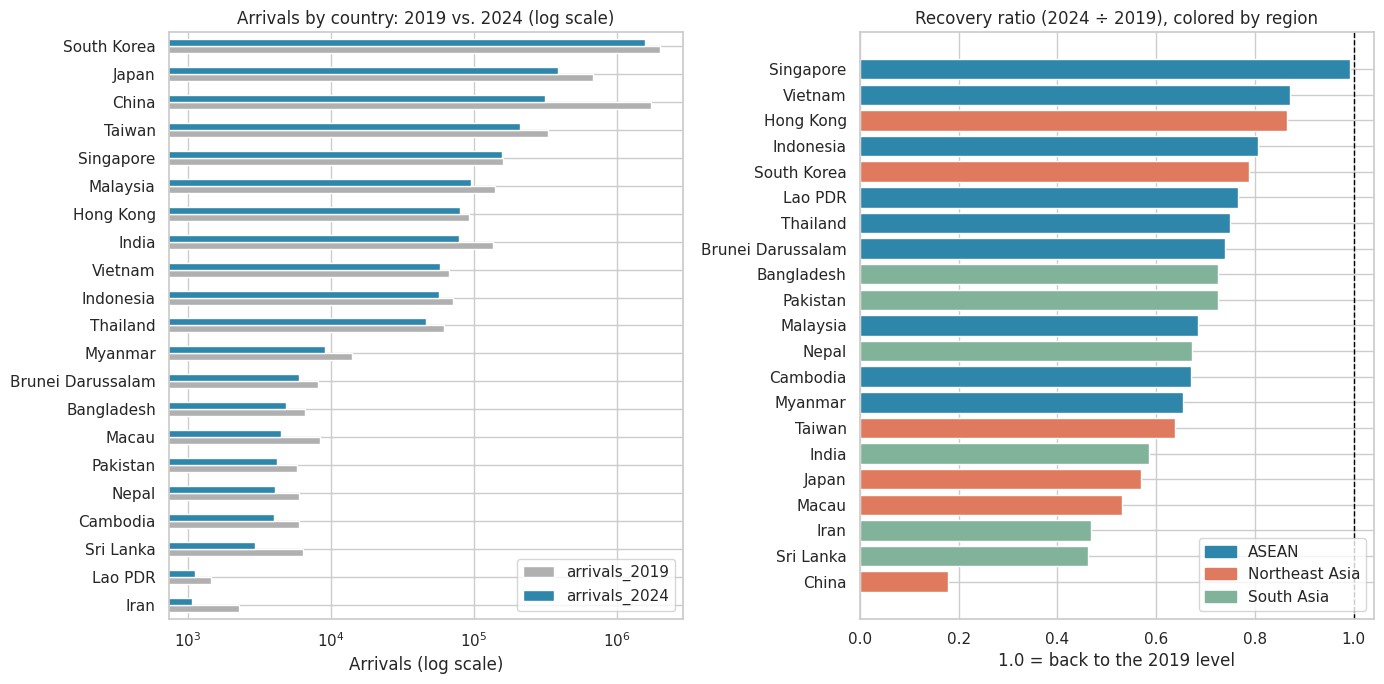

In [30]:
d = pdf_master.sort_values("arrivals_2024", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
d[["arrivals_2019", "arrivals_2024"]].plot.barh(ax=axes[0], color=["#B0B0B0", "#2E86AB"])
axes[0].set_xscale("log")
axes[0].set_title("Arrivals by country: 2019 vs. 2024 (log scale)")
axes[0].set_xlabel("Arrivals (log scale)"); axes[0].set_ylabel("")

r = pdf_master.sort_values("recovery_ratio")
axes[1].barh(r.index, r["recovery_ratio"], color=[REGION_COLORS[x] for x in r["region"]])
axes[1].axvline(1.0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Recovery ratio (2024 ÷ 2019), colored by region")
axes[1].set_xlabel("1.0 = back to the 2019 level")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c, label=k.replace("_", " ")) for k, c in REGION_COLORS.items()], loc="lower right")
plt.tight_layout(); plt.show()

**What it shows:**
- South Korea is by far the biggest market (1.57 million arrivals in 2024), followed by Japan (388,316) and China (312,222).
- No country is fully back to its 2019 level. Recovery ranges from 0.18 (China) to 0.99 (Singapore); the median is 0.68.
- China lost the most visitors: about 1.43 million fewer than in 2019.
- ASEAN recovered the most (median 0.75), then South Asia (0.63) and Northeast Asia (0.60).

### Mode of Travel
This chart shows the share of each country's 2024 arrivals that came by air. The axis starts at 95% so the small differences can be seen.

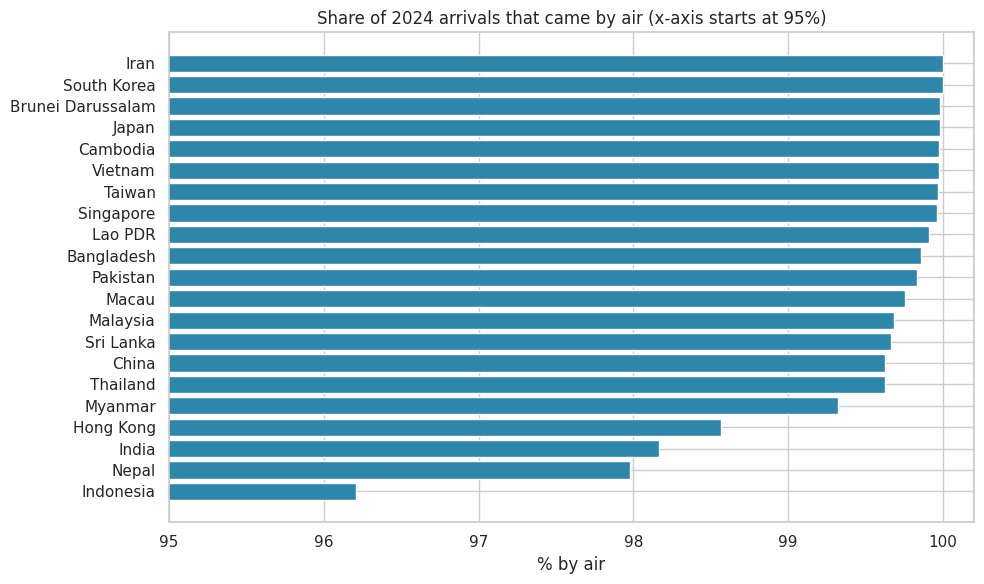

Lowest air share: 96.21% (Indonesia)


In [31]:
d = pdf_master.sort_values("pct_air")
plt.figure(figsize=(10, 6))
plt.barh(d.index, d["pct_air"], color="#2E86AB")
plt.xlim(95, 100.2)
plt.title("Share of 2024 arrivals that came by air (x-axis starts at 95%)")
plt.xlabel("% by air"); plt.tight_layout(); plt.show()
print(f"Lowest air share: {d['pct_air'].min():.2f}% ({d['pct_air'].idxmin()})")

**What it shows:**
- At least 96.2% of every country's visitors came by air (median 99.8%).
- The gap between countries is under 4 points, so mode of travel cannot help any model tell countries apart. It is left out of the models and reported as a simple finding: Asian visitors arrive almost entirely by air.

# RQ1: Regression

## Exploratory Data Analysis

#### The Target: Search Interest
The left chart ranks countries by their average 2024 search interest. The color shows how many weeks had enough searches for Google to report. The right chart shows how the values are spread out.

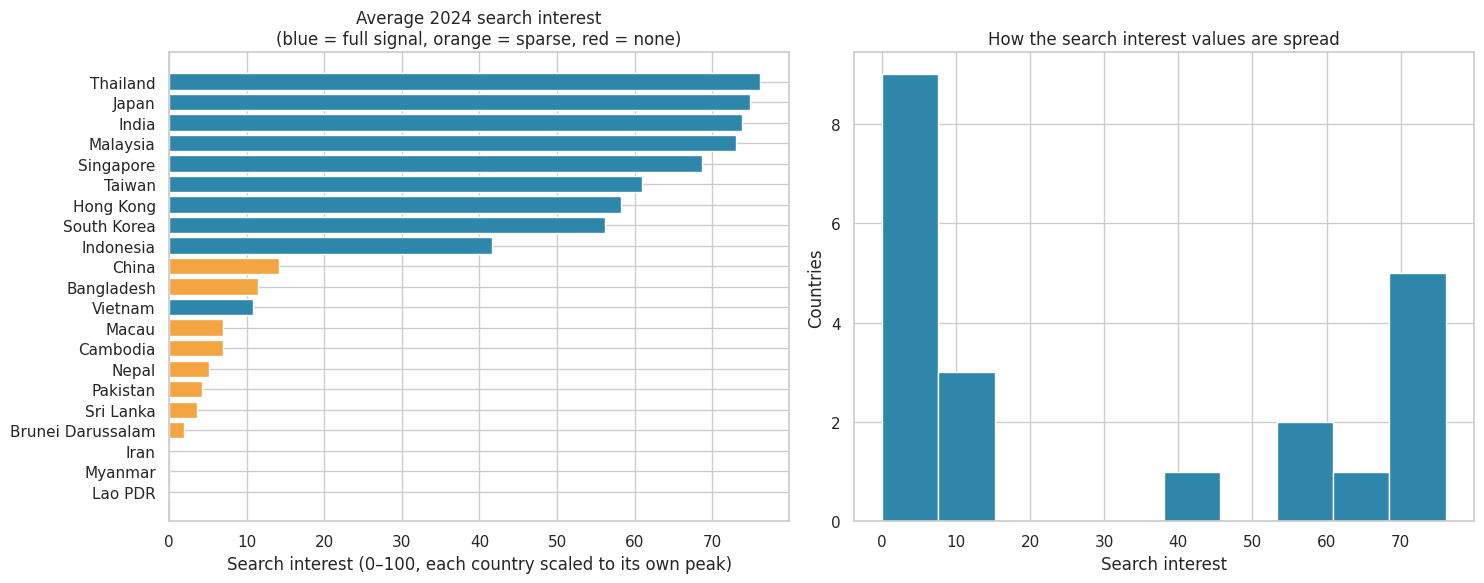

signal_level
full      10
sparse     8
none       3
Name: count, dtype: int64


In [32]:
d = pdf_master.sort_values("search_interest_index_mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(d.index, d["search_interest_index_mean"], color=[SIGNAL_COLORS[s] for s in d["signal_level"]])
axes[0].set_title("Average 2024 search interest\n(blue = full signal, orange = sparse, red = none)")
axes[0].set_xlabel("Search interest (0–100, each country scaled to its own peak)")
axes[1].hist(pdf_master["search_interest_index_mean"], bins=10, color="#2E86AB", edgecolor="white")
axes[1].set_title("How the search interest values are spread"); axes[1].set_xlabel("Search interest"); axes[1].set_ylabel("Countries")
plt.tight_layout(); plt.show()
print(pdf_master["signal_level"].value_counts())

**What it shows:**
- Search interest forms **two groups**: 8 countries score above 55 and 12 score 15 or below. Only Indonesia (41.6) is in between.
- Most low scores come from countries with sparse or no signal. Google shows low-volume searches as 0 (Google, n.d.), so Iran, Myanmar, and Lao PDR score 0.
- Each country is scaled to its own peak, so the values compare steadiness of interest, not search volume between countries.
- RQ1 is therefore also rerun on the 10 full-signal countries.

#### Which Features Move with Search Interest?
These charts show the correlation between each feature and search interest. Correlation runs from −1 to +1: blue bars (positive) mean the feature tends to be higher where search interest is higher; red bars (negative) mean the opposite.

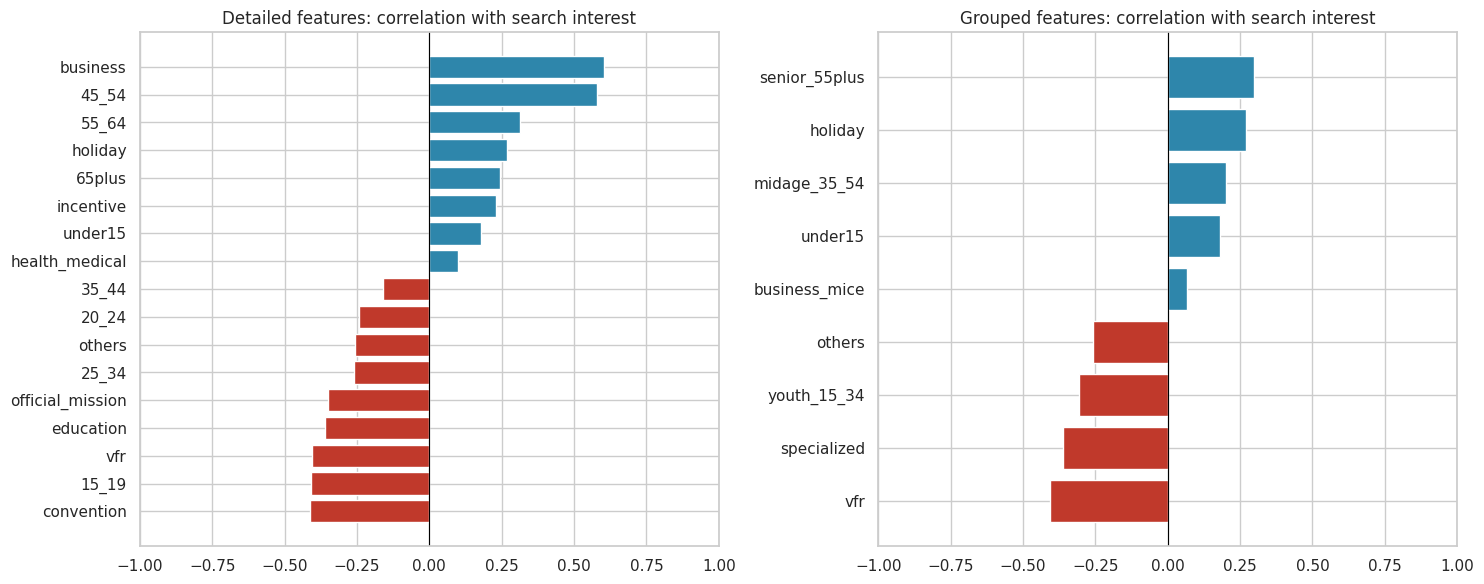

In [33]:
target = "search_interest_index_mean"
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cols, title in [(axes[0], RQ1_DETAILED, "Detailed features"), (axes[1], RQ1_GROUPED, "Grouped features")]:
    c = pdf_master[cols].corrwith(pdf_master[target]).sort_values()
    ax.barh(c.index.str.replace("pct_", ""), c.values,
            color=["#C0392B" if v < 0 else "#2E86AB" for v in c.values])
    ax.axvline(0, color="black", linewidth=0.8); ax.set_xlim(-1, 1)
    ax.set_title(f"{title}: correlation with search interest")
plt.tight_layout(); plt.show()

**What it shows:**
- **Strongest positive links:** business share (+0.60) and the 45–54 share (+0.58).
- **Strongest negative links:** 15–19, convention, and VFR shares (about −0.41 each).
- **Grouped features are weaker.** Business & MICE shows almost no link (+0.07), because business and conventions move in opposite directions.

These are simple correlations across 21 countries, not causes. RQ1 tests them with cross-validation.

#### A Closer Look at the Two Strongest Features
Each dot is one country, colored by its signal level.

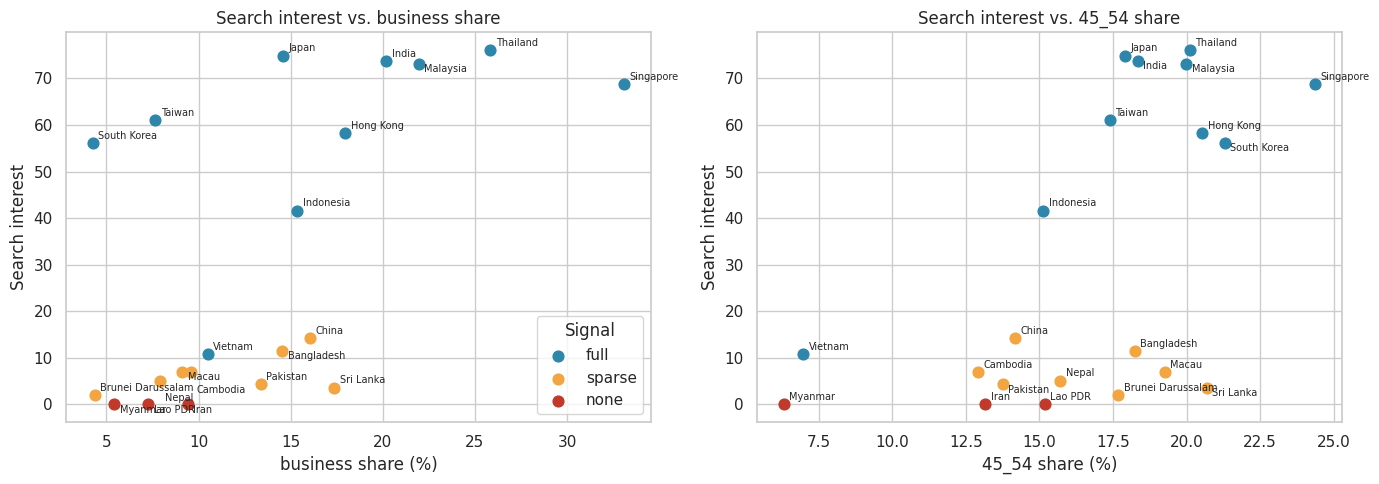

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["pct_business", "pct_45_54"]):
    for level, color in SIGNAL_COLORS.items():
        sub = pdf_master[pdf_master["signal_level"] == level]
        ax.scatter(sub[col], sub["search_interest_index_mean"], color=color, s=60, label=level)
    label_points(ax, pdf_master[col].tolist(), pdf_master["search_interest_index_mean"].tolist(),
                 pdf_master.index.tolist(), fontsize=7)
    ax.set_xlabel(col.replace("pct_", "") + " share (%)"); ax.set_ylabel("Search interest")
    ax.set_title(f"Search interest vs. {col.replace('pct_', '')} share")
axes[0].legend(title="Signal")
plt.tight_layout(); plt.show()

**What it shows:** higher business and 45–54 shares go with higher search interest, but the pattern mostly comes from the gap between full-signal countries and sparse or no-signal countries.

#### How the Features Move Together
This heatmap shows the correlation between every pair of RQ1 features.

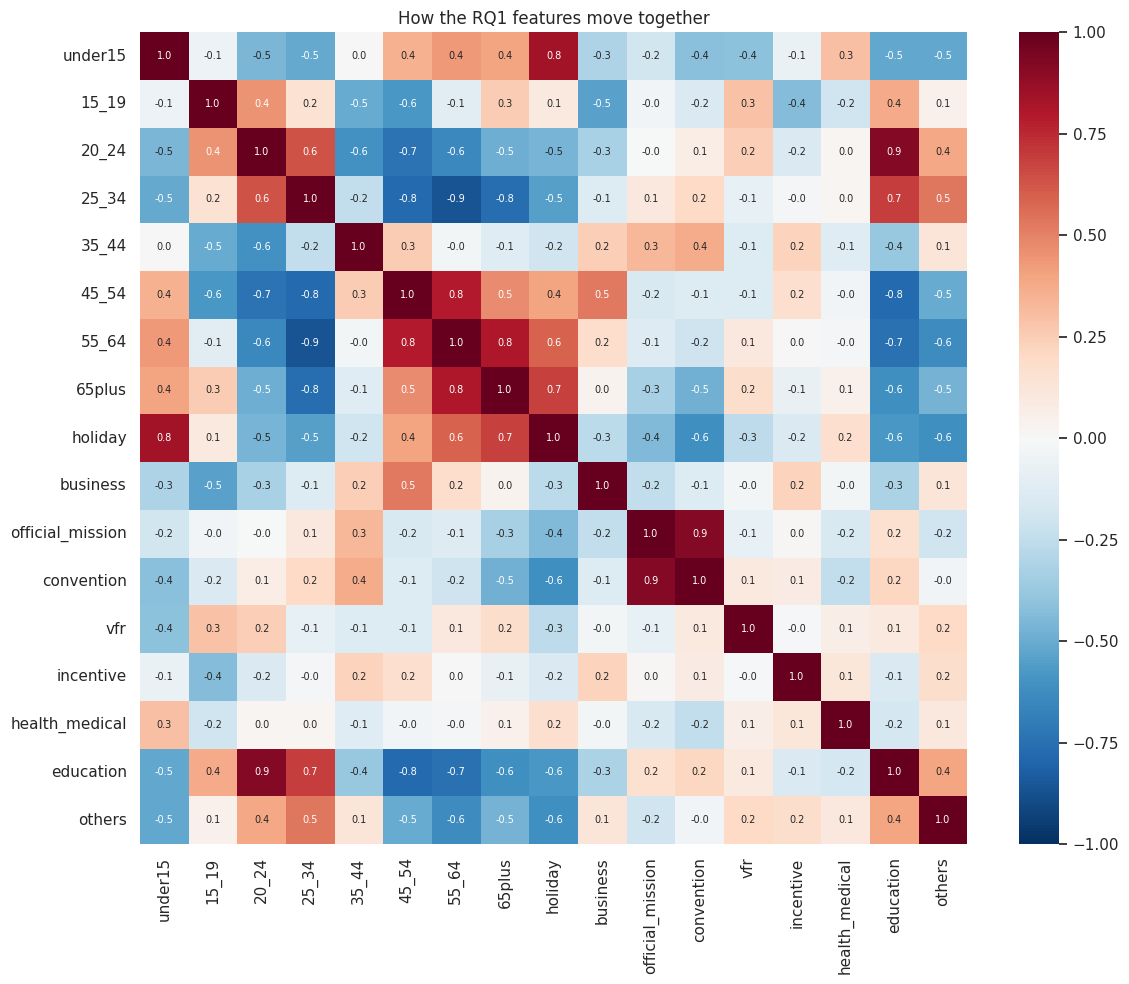

Strongest feature pairs:
pct_20_24       pct_education           0.92
pct_convention  pct_official_mission    0.92
pct_25_34       pct_55_64              -0.86
pct_holiday     pct_under15             0.84
pct_55_64       pct_65plus              0.81
dtype: float64


In [35]:
corr = pdf_master[RQ1_DETAILED].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr.rename(index=lambda c: c.replace("pct_", ""), columns=lambda c: c.replace("pct_", "")),
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("How the RQ1 features move together"); plt.tight_layout(); plt.show()

pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print("Strongest feature pairs:")
print(pairs[pairs.index.map(lambda p: p[0] < p[1])].sort_values(key=abs, ascending=False).head(5).round(2))

**What it shows:**
- Several features move together strongly, for example 20–24 with education (+0.92), convention with official mission (+0.92), and under 15 with holiday (+0.84).
- Shares within a group add up to 100%, so when one rises, others must fall (Aitchison, 1982).

**Why it matters:** linked features confuse plain linear regression. Ridge Regression is built for this (Hoerl & Kennard, 1970), so it is RQ1's main model.

## Model Setup
With only 21 countries, how we test the models matters as much as which model we use.

- **Leave-one-country-out cross-validation (LOOCV):** each country is predicted by a model that never saw it. Scores are computed once on all 21 predictions.
- **Nested tuning:** model settings are chosen only inside the training countries. Tuning and scoring on the same data makes results look better than they are (Varma & Simon, 2006).
- **Models built for linked features:** age shares and purpose shares each add up to 100%, so they move together (Aitchison, 1982). Ridge Regression handles this (Hoerl & Kennard, 1970), so it is the main model.
- **Predictions are kept between 0 and 100**, the range of the Google Trends index (Google, n.d.).

**Feature sets:** age only (8), purpose only (9), age + purpose (17), and the grouped set (8). They are set by meaning, not by which features scored best in the EDA, to avoid a hidden head start.

**Tools:** Spark prepares the data. Most model fitting uses scikit-learn (Pedregosa et al., 2011), because LOOCV with nested tuning and a 500-run permutation test needs thousands of tiny fits, which Spark's per-job overhead makes too slow for 21 rows. The main Ridge model is also refit in Spark MLlib as a cross-check (Evaluation).

In [36]:
import warnings
from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler as SkStandardScaler
from sklearn.linear_model import RidgeCV, ElasticNetCV, LogisticRegressionCV, Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, KFold, StratifiedKFold, GridSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             roc_auc_score, balanced_accuracy_score)
for cat in (UserWarning, RuntimeWarning, FutureWarning):
    warnings.filterwarnings("ignore", category=cat)

# ---------- RQ1 settings ----------
ID_COL, TARGET = "country", "search_interest_index_mean"
Y_MIN, Y_MAX = 0.0, 100.0                       # the index cannot leave this range
RQ1_AGE = [f"pct_{c}" for c in AGE_COLS]        # 8 age shares
RQ1_PURPOSE = [f"pct_{c}" for c in PURPOSE_COLS]  # 9 purpose shares
AGE_GROUPED_COLS = ["pct_youth_15_34", "pct_midage_35_54", "pct_senior_55plus"]
PURPOSE_GROUPED_COLS = ["pct_holiday", "pct_business_mice", "pct_vfr", "pct_specialized", "pct_others"]
SIGNAL_COL, FULL_LABEL = "signal_level", "full"
EXCLUDE_COL = "exclude_from_rq1a"               # True only for China

SEED = 42
INNER_FOLDS = 5                                 # folds inside each training set for tuning
RIDGE_ALPHAS = np.logspace(-1, 3, 30)           # Ridge penalty grid (0.1 to 1000)
N_PERMUTATIONS, N_REPEATS, N_BOOT = 500, 20, 1000
HIGH_CUT = 30.0                                 # high/low split for the classification view

needed = list(dict.fromkeys([ID_COL, TARGET, SIGNAL_COL, "nonzero_week_count", EXCLUDE_COL]
                            + RQ1_AGE + RQ1_PURPOSE + AGE_GROUPED_COLS + PURPOSE_GROUPED_COLS))
rq1_model_df = (rq1_df.select(*needed)
                .withColumn(EXCLUDE_COL, F.lower(F.col(EXCLUDE_COL).cast("string")) == "true")
                .dropna().cache())
pdf = rq1_model_df.toPandas()
print("rows:", len(pdf), "| age features:", len(RQ1_AGE), "| purpose features:", len(RQ1_PURPOSE))

rows: 21 | age features: 8 | purpose features: 9


In [37]:
RQ1_FEATURE_SETS = {
    "age_only":            RQ1_AGE,                                   # 8
    "purpose_only":        RQ1_PURPOSE,                               # 9
    "age_purpose":         RQ1_AGE + RQ1_PURPOSE,                     # 17
    "age_purpose_grouped": AGE_GROUPED_COLS + PURPOSE_GROUPED_COLS,   # 8
}
MODELS = ["ridge", "elastic_net", "pls", "random_forest"]
for k, v in RQ1_FEATURE_SETS.items():
    print(f"{k:22s} {len(v):2d} features")


def inner_cv(n_rows):
    return KFold(n_splits=min(INNER_FOLDS, n_rows), shuffle=True, random_state=SEED)


def make_model(name, n_train):
    # Every model is a full pipeline, so scaling and tuning are redone inside each training set
    if name == "ridge":
        return Pipeline([("scaler", SkStandardScaler()), ("model", RidgeCV(alphas=RIDGE_ALPHAS))])
    if name == "elastic_net":
        return Pipeline([("scaler", SkStandardScaler()),
                         ("model", ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=inner_cv(n_train),
                                                max_iter=100_000, random_state=SEED))])
    if name == "pls":
        return GridSearchCV(Pipeline([("scaler", SkStandardScaler()), ("model", PLSRegression(scale=False))]),
                            {"model__n_components": [1, 2, 3]}, cv=inner_cv(n_train),
                            scoring="neg_mean_squared_error")
    if name == "random_forest":
        return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                                     random_state=SEED, n_jobs=-1)
    raise ValueError(name)


def oof_predict(name, X, y, splitter=None):
    # Out-of-fold predictions: each row is predicted by a model trained without it, clipped to [0, 100]
    splitter = splitter or LeaveOneOut()
    pred = np.empty(len(y))
    for tr, va in splitter.split(X):
        m = make_model(name, len(tr)).fit(X[tr], y[tr])
        pred[va] = np.ravel(m.predict(X[va]))
    return np.clip(pred, Y_MIN, Y_MAX)


def baseline_oof(y, splitter=None):
    # Baseline: predict the training-set mean for each held-out row
    splitter = splitter or LeaveOneOut()
    pred = np.empty(len(y))
    for tr, va in splitter.split(y.reshape(-1, 1)):
        pred[va] = y[tr].mean()
    return pred


def score(y, pred):
    return {"rmse": float(np.sqrt(mean_squared_error(y, pred))),
            "mae":  float(mean_absolute_error(y, pred)),
            "r2":   float(r2_score(y, pred)),
            "spearman": float(spearmanr(y, pred).statistic)}


def run_all(sdf, label, models=MODELS):
    # Every feature set x every model under LOOCV
    p = sdf.toPandas() if hasattr(sdf, "toPandas") else sdf
    y = p[TARGET].to_numpy(dtype=float)
    base = score(y, baseline_oof(y))
    rows, oof = [], {"_y": y, "_baseline": baseline_oof(y), "_country": p[ID_COL].tolist()}
    for fs_name, feats in RQ1_FEATURE_SETS.items():
        X = p[feats].to_numpy(dtype=float)
        for m in models:
            pred = oof_predict(m, X, y)
            oof[(fs_name, m)] = pred
            s = score(y, pred)
            rows.append({"run": label, "n_rows": len(y), "feature_set": fs_name, "n_features": len(feats),
                         "model": m, "cv_rmse": s["rmse"], "cv_mae": s["mae"], "cv_r2": s["r2"],
                         "cv_spearman": s["spearman"], "baseline_rmse": base["rmse"], "baseline_mae": base["mae"]})
    return pd.DataFrame(rows), oof

age_only                8 features
purpose_only            9 features
age_purpose            17 features
age_purpose_grouped     8 features


## Train and Tune
Four models are trained, each tuned inside every training set:
- **Ridge Regression** (main model): shrinks the effect of linked features (Hoerl & Kennard, 1970).
- **Elastic Net:** like Ridge, but can also drop features (Zou & Hastie, 2005).
- **PLS Regression:** squeezes the linked shares into 1–3 summary factors (Wold et al., 2001).
- **Random Forest:** checks for non-straight-line patterns (Breiman, 2001).

Each model is fitted 21 times, once per held-out country.

In [38]:
results_main, oof_main = run_all(rq1_model_df, label="all_countries")
y_all = oof_main["_y"]
base_main = score(y_all, oof_main["_baseline"])
print(f"Baseline (predict the training mean), LOOCV:  RMSE = {base_main['rmse']:.2f}   MAE = {base_main['mae']:.2f}")
results_main.round(3)

Baseline (predict the training mean), LOOCV:  RMSE = 31.96   MAE = 30.55


,run,n_rows,feature_set,n_features,model,cv_rmse,cv_mae,cv_r2,cv_spearman,baseline_rmse,baseline_mae
0,all_countries,21,age_only,8,ridge,22.688,17.726,0.445,0.658,31.964,30.546
1,all_countries,21,age_only,8,elastic_net,25.779,20.131,0.283,0.457,31.964,30.546
2,all_countries,21,age_only,8,pls,27.589,22.886,0.179,0.353,31.964,30.546
3,all_countries,21,age_only,8,random_forest,31.477,27.155,-0.069,0.155,31.964,30.546
4,all_countries,21,purpose_only,9,ridge,23.162,19.767,0.421,0.806,31.964,30.546
5,all_countries,21,purpose_only,9,elastic_net,22.931,19.507,0.433,0.838,31.964,30.546
6,all_countries,21,purpose_only,9,pls,23.617,19.338,0.398,0.692,31.964,30.546
7,all_countries,21,purpose_only,9,random_forest,26.675,24.966,0.232,0.596,31.964,30.546
8,all_countries,21,age_purpose,17,ridge,22.652,19.121,0.446,0.736,31.964,30.546
9,all_countries,21,age_purpose,17,elastic_net,23.081,19.661,0.425,0.713,31.964,30.546


## Evaluation
- **RMSE and MAE:** the average prediction error in index points. Lower is better.
- **R²:** the share of the differences between countries that the model explains.
- **Spearman ρ:** how well the model ranks countries (−1 to 1).
- **Baseline:** always predict the average. A useful model must beat its RMSE (about 32).

In [39]:
view = results_main.copy()
view["beats_baseline"] = view["cv_rmse"] < view["baseline_rmse"]
view["rmse_gain_vs_baseline_%"] = 100 * (view["baseline_rmse"] - view["cv_rmse"]) / view["baseline_rmse"]
view.sort_values("cv_rmse")[["feature_set", "model", "cv_rmse", "cv_mae", "cv_r2", "cv_spearman",
                             "beats_baseline", "rmse_gain_vs_baseline_%"]].round(3)

,feature_set,model,cv_rmse,cv_mae,cv_r2,cv_spearman,beats_baseline,rmse_gain_vs_baseline_%
8,age_purpose,ridge,22.652,19.121,0.446,0.736,True,29.133
0,age_only,ridge,22.688,17.726,0.445,0.658,True,29.021
10,age_purpose,pls,22.845,18.735,0.437,0.740,True,28.530
5,purpose_only,elastic_net,22.931,19.507,0.433,0.838,True,28.259
9,age_purpose,elastic_net,23.081,19.661,0.425,0.713,True,27.791
4,purpose_only,ridge,23.162,19.767,0.421,0.806,True,27.535
6,purpose_only,pls,23.617,19.338,0.398,0.692,True,26.113
1,age_only,elastic_net,25.779,20.131,0.283,0.457,True,19.350
7,purpose_only,random_forest,26.675,24.966,0.232,0.596,True,16.547
2,age_only,pls,27.589,22.886,0.179,0.353,True,13.686


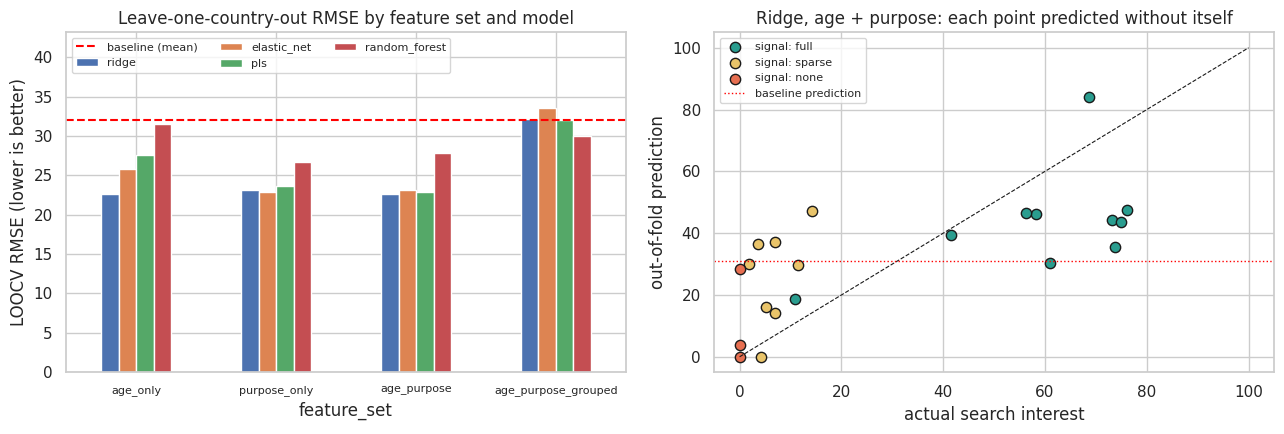

Largest out-of-fold errors:
  country  actual  predicted signal_level  abs_error
    India    73.8       35.7         full       38.1
Sri Lanka     3.6       36.6       sparse       33.0
    China    14.2       47.2       sparse       33.0
    Japan    74.9       43.8         full       31.1
   Taiwan    61.0       30.3         full       30.7


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pivot = results_main.pivot(index="feature_set", columns="model", values="cv_rmse").reindex(RQ1_FEATURE_SETS.keys())[MODELS]
pivot.plot(kind="bar", ax=axes[0], rot=0)
axes[0].axhline(base_main["rmse"], color="red", ls="--", label="baseline (mean)")
axes[0].set_ylabel("LOOCV RMSE (lower is better)")
axes[0].set_title("Leave-one-country-out RMSE by feature set and model")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].set_ylim(0, base_main["rmse"] * 1.35); axes[0].legend(fontsize=8, ncol=3, loc="upper left")

pred = oof_main[("age_purpose", "ridge")]
sig = pdf[SIGNAL_COL].to_numpy()
for lvl, c in [("full", "#2a9d8f"), ("sparse", "#e9c46a"), ("none", "#e76f51")]:
    m = sig == lvl
    axes[1].scatter(y_all[m], pred[m], c=c, s=55, edgecolor="k", label=f"signal: {lvl}")
axes[1].plot([0, 100], [0, 100], "k--", lw=0.8)
axes[1].axhline(y_all.mean(), color="red", ls=":", lw=1, label="baseline prediction")
axes[1].set_xlabel("actual search interest"); axes[1].set_ylabel("out-of-fold prediction")
axes[1].set_title("Ridge, age + purpose: each point predicted without itself")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

diag = pd.DataFrame({ID_COL: oof_main["_country"], "actual": y_all, "predicted": pred,
                     SIGNAL_COL: sig}).assign(abs_error=lambda d: (d.actual - d.predicted).abs())
print("Largest out-of-fold errors:")
print(diag.sort_values("abs_error", ascending=False).head(5).round(1).to_string(index=False))

**What it shows:**
- Ridge on age + purpose is best: RMSE **22.7 vs. 32.0** for the baseline, about 29% less error (R² 0.45).
- Age only and purpose only do almost as well. The **grouped set does not beat the baseline**.
- The biggest misses are India, Sri Lanka, China, Japan, and Taiwan (errors of about 31–38 points).

#### Could Chance Produce This? (Permutation Test)
The search-interest values are shuffled across countries 500 times and the whole LOOCV is rerun each time. The **p-value** is the share of shuffled runs that score as well as the real one (Ojala & Garriga, 2010).

age_only               real RMSE 22.69 | chance RMSE median 33.01 (5th pct 28.72) | p = 0.006
purpose_only           real RMSE 23.16 | chance RMSE median 33.09 (5th pct 27.95) | p = 0.006
age_purpose            real RMSE 22.65 | chance RMSE median 33.37 (5th pct 28.20) | p = 0.010
age_purpose_grouped    real RMSE 32.15 | chance RMSE median 32.80 (5th pct 29.25) | p = 0.291


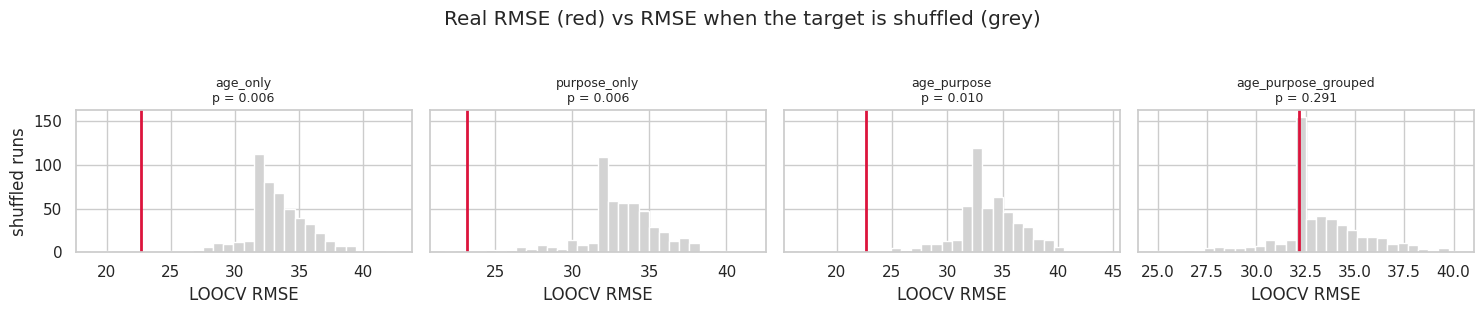

In [41]:
def permutation_test(feats, model="ridge", n_perm=N_PERMUTATIONS, data=pdf):
    X = data[feats].to_numpy(dtype=float)
    y = data[TARGET].to_numpy(dtype=float)
    real = score(y, oof_predict(model, X, y))["rmse"]
    rng = np.random.RandomState(SEED)
    null = np.array([score(yp, oof_predict(model, X, yp))["rmse"]
                     for yp in (rng.permutation(y) for _ in range(n_perm))])
    p = (1 + np.sum(null <= real)) / (n_perm + 1)
    return real, null, p

perm = {}
for fs_name, feats in RQ1_FEATURE_SETS.items():
    perm[fs_name] = permutation_test(feats)
    real, null, p = perm[fs_name]
    print(f"{fs_name:22s} real RMSE {real:5.2f} | chance RMSE median {np.median(null):5.2f} "
          f"(5th pct {np.percentile(null, 5):5.2f}) | p = {p:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, (fs_name, (real, null, p)) in zip(axes, perm.items()):
    ax.hist(null, bins=30, color="lightgrey", edgecolor="white")
    ax.axvline(real, color="crimson", lw=2)
    ax.set_title(f"{fs_name}\np = {p:.3f}", fontsize=9); ax.set_xlabel("LOOCV RMSE")
axes[0].set_ylabel("shuffled runs")
plt.suptitle("Real RMSE (red) vs RMSE when the target is shuffled (grey)", y=1.04)
plt.tight_layout(); plt.show()

**What it shows:** age only, purpose only, and age + purpose all have **p ≤ 0.01**, so their results are very unlikely to be luck. The grouped set has p = 0.29, so its result could be chance.

#### How Stable Is the Score? (Repeated 5-Fold CV)
5-fold CV is repeated with 20 different random splits to see how much the score depends on which countries are held out together.

In [42]:
rep_rows = []
y = pdf[TARGET].to_numpy(dtype=float)
for fs_name, feats in RQ1_FEATURE_SETS.items():
    X = pdf[feats].to_numpy(dtype=float)
    for r in range(N_REPEATS):
        kf = KFold(5, shuffle=True, random_state=SEED + r)
        s, b = score(y, oof_predict("ridge", X, y, kf)), score(y, baseline_oof(y, kf))
        rep_rows.append({"feature_set": fs_name, "repeat": r, "rmse": s["rmse"], "r2": s["r2"],
                         "spearman": s["spearman"], "beats_baseline": s["rmse"] < b["rmse"]})
rep = pd.DataFrame(rep_rows)

q = lambda p: (lambda s: s.quantile(p))
rep.groupby("feature_set").agg(
    rmse_median=("rmse", "median"), r2_median=("r2", "median"),
    r2_p10=("r2", q(0.10)), r2_p90=("r2", q(0.90)),
    spearman_median=("spearman", "median"),
    share_of_splits_beating_baseline=("beats_baseline", "mean")).reindex(RQ1_FEATURE_SETS.keys()).round(2)

,rmse_median,r2_median,r2_p10,r2_p90,spearman_median,share_of_splits_beating_baseline
feature_set,,,,,,
age_only,26.25,0.26,0.08,0.43,0.47,1.00
purpose_only,24.07,0.38,0.10,0.51,0.74,1.00
age_purpose,24.51,0.35,0.20,0.48,0.62,0.95
age_purpose_grouped,33.76,-0.23,-0.43,-0.07,-0.21,0.25


**What it shows:** the detailed feature sets beat the baseline in 95–100% of the 20 splits (median R² 0.26–0.38), so the result does not depend on one lucky split. The grouped set beats it in only 25%.

#### Can Composition Tell High-Interest From Low-Interest Markets?
Search interest has a high group and a low group with an empty gap between them, so we also test a simpler question: is a market above or below 30? Logistic regression is used under the same LOOCV.
- **AUC:** the chance that a high-interest market gets a higher score than a low-interest one (0.5 = coin flip, 1.0 = perfect).
- **Balanced accuracy:** the average hit rate in the two groups (0.5 = guessing).

In [43]:
ys = np.sort(pdf[TARGET].to_numpy()); i = int(np.argmax(np.diff(ys)))
print(f"Largest gap in search interest: {ys[i]:.1f} to {ys[i+1]:.1f} -> the cut at {HIGH_CUT:.0f} sits inside it")

def oof_classify(X, yb):
    proba = np.empty(len(yb))
    for tr, va in LeaveOneOut().split(X):
        n_min = int(np.bincount(yb[tr]).min())
        clf = Pipeline([("scaler", SkStandardScaler()),
                        ("model", LogisticRegressionCV(Cs=np.logspace(-2, 2, 15),
                                                       cv=StratifiedKFold(min(INNER_FOLDS, n_min), shuffle=True, random_state=SEED),
                                                       max_iter=5000))])
        clf.fit(X[tr], yb[tr])
        proba[va] = clf.predict_proba(X[va])[:, 1]
    return proba

yb = (pdf[TARGET].to_numpy() > HIGH_CUT).astype(int)
print(f"high group: {yb.sum()} markets | low group: {len(yb) - yb.sum()} markets")
cls_rows = []
for fs_name, feats in RQ1_FEATURE_SETS.items():
    proba = oof_classify(pdf[feats].to_numpy(dtype=float), yb)
    cls_rows.append({"feature_set": fs_name, "auc": roc_auc_score(yb, proba),
                     "balanced_accuracy": balanced_accuracy_score(yb, proba > 0.5)})
pd.DataFrame(cls_rows).round(2)

Largest gap in search interest: 14.2 to 41.6 -> the cut at 30 sits inside it
high group: 9 markets | low group: 12 markets


,feature_set,auc,balanced_accuracy
0,age_only,0.88,0.71
1,purpose_only,0.80,0.75
2,age_purpose,0.73,0.71
3,age_purpose_grouped,0.61,0.61


**What it shows:** composition separates high- from low-interest markets well. Age only reaches AUC 0.88 and purpose only 0.80. The grouped set is weakest (0.61).

#### Sensitivity Checks
The same LOOCV is rerun (a) **without China**, where Google is blocked, and (b) on the **10 full-year-signal countries only**, where low scores are not caused by missing Google data. Run (b) has only 10 rows, so it is a rough check.

In [44]:
no_china  = rq1_model_df.filter(~F.col(EXCLUDE_COL))
full_year = rq1_model_df.filter(F.col(SIGNAL_COL) == FULL_LABEL)
print("rows without China:", no_china.count(), "| rows, full-year only:", full_year.count())

results_nochina, oof_nochina = run_all(no_china,  label="without_china")
results_full,    oof_full    = run_all(full_year, label="full_year_only")
sens = pd.concat([results_main, results_nochina, results_full], ignore_index=True)

# Ridge only: RMSE gain over the baseline in each run
(sens[sens.model == "ridge"]
 .assign(gain_vs_baseline_pct=lambda d: 100 * (d.baseline_rmse - d.cv_rmse) / d.baseline_rmse)
 .pivot(index="feature_set", columns="run", values="gain_vs_baseline_pct")
 .reindex(RQ1_FEATURE_SETS.keys())[["all_countries", "without_china", "full_year_only"]]
 .round(1).rename_axis(columns="Ridge: RMSE gain vs baseline, %"))

rows without China: 20 | rows, full-year only: 10


"Ridge: RMSE gain vs baseline, %",all_countries,without_china,full_year_only
feature_set,,,
age_only,29.0,24.9,-34.7
purpose_only,27.5,36.8,-2.3
age_purpose,29.1,33.1,-8.3
age_purpose_grouped,-0.6,3.0,-41.9


**What it shows:**
- **Without China**, purpose only improves (37% less error than the baseline), while age only drops a little (25%).
- **On the 10 full-signal countries, no model beats the baseline.** Composition mainly separates strong-interest markets from weak or sparse ones; it does not explain differences among the strong-interest markets.

#### Spark MLlib Cross-Check
The main model is refit with Spark MLlib to confirm the result does not depend on the library. Ridge Regression is Spark's `LinearRegression` with only an L2 penalty (`elasticNetParam = 0`) (Hoerl & Kennard, 1970; Meng et al., 2016). The penalty (`regParam`) is tuned with `ParamGridBuilder` and `CrossValidator` inside the 20 training countries of each leave-one-country-out round, so the held-out country is never used for tuning (Varma & Simon, 2006).

This trains about 1,900 small models, so it takes about 10–15 minutes.

In [45]:
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import RegressionEvaluator

REG_GRID = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]          # Spark's ridge penalty (regParam)
rmse_eval = RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName="rmse")
rq1_spark_data = rq1_model_df.coalesce(1).cache()
rq1_countries = [r[ID_COL] for r in rq1_spark_data.select(ID_COL).collect()]

def spark_ridge(feats):
    # Ridge = LinearRegression with an L2 penalty only (elasticNetParam = 0)
    lr = LinearRegression(featuresCol="features", labelCol=TARGET, elasticNetParam=0.0, standardization=False)
    pipe = SparkPipeline(stages=[VectorAssembler(inputCols=feats, outputCol="raw"),
                                 StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True),
                                 lr])
    grid = ParamGridBuilder().addGrid(lr.regParam, REG_GRID).build()
    return CrossValidator(estimator=pipe, estimatorParamMaps=grid, evaluator=rmse_eval,
                          numFolds=5, seed=SEED)

mllib_rows = []
for fs_name in ["age_only", "purpose_only", "age_purpose"]:
    feats = RQ1_FEATURE_SETS[fs_name]
    preds = []
    for c in rq1_countries:                            # leave one country out
        train = rq1_spark_data.filter(F.col(ID_COL) != c)
        test = rq1_spark_data.filter(F.col(ID_COL) == c)
        model = spark_ridge(feats).fit(train)          # regParam tuned inside the 20 training countries
        p = model.transform(test).select(
            TARGET, F.greatest(F.lit(0.0), F.least(F.lit(100.0), F.col("prediction"))).alias("prediction"))
        preds.append(p.first())
    pdf_p = pd.DataFrame(preds, columns=[TARGET, "prediction"])
    y_, p_ = pdf_p[TARGET].to_numpy(), pdf_p["prediction"].to_numpy()
    mllib_rows.append({"feature_set": fs_name,
                       "mllib_rmse": float(np.sqrt(np.mean((y_ - p_) ** 2))),
                       "mllib_spearman": float(pd.Series(y_).corr(pd.Series(p_), method="spearman"))})

sk = (results_main[results_main.model == "ridge"].set_index("feature_set")
      [["cv_rmse", "cv_spearman"]].rename(columns={"cv_rmse": "sklearn_rmse", "cv_spearman": "sklearn_spearman"}))
mllib_cmp = (pd.DataFrame(mllib_rows).set_index("feature_set").join(sk)
             .assign(baseline_rmse=base_main["rmse"]).round(2))
mllib_cmp

,mllib_rmse,mllib_spearman,sklearn_rmse,sklearn_spearman,baseline_rmse
feature_set,,,,,
age_only,24.27,0.57,22.69,0.66,31.96
purpose_only,22.52,0.84,23.16,0.81,31.96
age_purpose,22.20,0.77,22.65,0.74,31.96


**What it shows:** the Spark MLlib Ridge gives nearly the same result as scikit-learn. Every feature set beats the baseline (RMSE 22.2–24.3 vs. 32.0), and purpose again ranks markets better than age (Spearman 0.84 vs. 0.57). The RQ1 answer does not depend on the library used.

## Interpretation
#### RQ1a: Age or Purpose?
Both factors are scored on the same 21 countries, so we compare them country by country. The 21 countries are resampled 1,000 times (bootstrap; Efron & Tibshirani, 1993) and the RMSE difference is recomputed each time. If the 90% range of the difference includes 0, the data cannot tell the two apart.

In [46]:
def paired_bootstrap(y, pa, pb, n=N_BOOT, seed=SEED):
    rng = np.random.RandomState(seed)
    rm = lambda yy, pp: np.sqrt(np.mean((yy - pp) ** 2))
    diffs = np.array([rm(y[i], pa[i]) - rm(y[i], pb[i])
                      for i in (rng.randint(0, len(y), len(y)) for _ in range(n))])
    return rm(y, pa) - rm(y, pb), np.percentile(diffs, [5, 95]), np.mean(diffs < 0)

rq1a_rows = []
for run_name, oof in [("all_countries", oof_main), ("without_china", oof_nochina), ("full_year_only", oof_full)]:
    yy, pa, pp = oof["_y"], oof[("age_only", "ridge")], oof[("purpose_only", "ridge")]
    d, (lo, hi), share_age_better = paired_bootstrap(yy, pa, pp)
    base_rmse = score(yy, oof["_baseline"])["rmse"]
    a_ok, p_ok = score(yy, pa)["rmse"] < base_rmse, score(yy, pp)["rmse"] < base_rmse
    if not (a_ok or p_ok):
        verdict = "neither beats baseline"
    elif hi < 0:
        verdict = "age"
    elif lo > 0:
        verdict = "purpose"
    else:
        verdict = "cannot separate"
    rq1a_rows.append({"run": run_name, "n": len(yy),
                      "age_rmse": score(yy, pa)["rmse"], "purpose_rmse": score(yy, pp)["rmse"],
                      "age_spearman": score(yy, pa)["spearman"], "purpose_spearman": score(yy, pp)["spearman"],
                      "rmse_diff_age_minus_purpose": d, "diff_90ci_low": lo, "diff_90ci_high": hi,
                      "boot_share_age_better": share_age_better, "verdict": verdict})
rq1a_table = pd.DataFrame(rq1a_rows)
rq1a_table.round(2)

,run,n,age_rmse,purpose_rmse,age_spearman,purpose_spearman,rmse_diff_age_minus_purpose,diff_90ci_low,diff_90ci_high,boot_share_age_better,verdict
0,all_countries,21,22.69,23.16,0.66,0.81,-0.47,-6.20,4.82,0.54,cannot separate
1,without_china,20,24.48,20.59,0.64,0.86,3.89,-0.81,8.40,0.09,cannot separate
2,full_year_only,10,28.77,21.84,-0.49,-0.95,6.94,0.83,16.45,0.01,neither beats baseline


**What it shows:** on error alone, age and purpose **cannot be separated** (RMSE 22.7 vs. 23.2; the 90% range of the difference, −6.2 to +4.8, includes 0). Purpose ranks markets better (ρ 0.81 vs. 0.66) and holds up better without China.

#### Do Age and Purpose Carry the Same Information?

In [47]:
pa, pp, pb = (oof_main[(fs, "ridge")] for fs in ["age_only", "purpose_only", "age_purpose"])
print(f"Correlation between age-only and purpose-only predictions: {np.corrcoef(pa, pp)[0, 1]:.2f}")
for name, p_ in [("age_only", pa), ("purpose_only", pp), ("age_purpose", pb)]:
    s = score(y_all, p_)
    print(f"  {name:13s} RMSE {s['rmse']:5.2f}  R2 {s['r2']:5.2f}  Spearman {s['spearman']:4.2f}")
print("\nThe two strongest single predictors move together:")
for a, b in [("pct_business", "pct_45_54"), ("pct_business", "pct_15_19"), ("pct_45_54", "pct_15_19")]:
    print(f"  r({a}, {b}) = {pdf[a].corr(pdf[b]):+.2f}")

Correlation between age-only and purpose-only predictions: 0.59
  age_only      RMSE 22.69  R2  0.44  Spearman 0.66
  purpose_only  RMSE 23.16  R2  0.42  Spearman 0.81
  age_purpose   RMSE 22.65  R2  0.45  Spearman 0.74

The two strongest single predictors move together:
  r(pct_business, pct_45_54) = +0.53
  r(pct_business, pct_15_19) = -0.54
  r(pct_45_54, pct_15_19) = -0.59


**What it shows:** adding purpose to age barely lowers the error (22.65 vs. 22.69), and the two models' predictions correlate at 0.59. Business share and the 45–54 share also move together (+0.53). Age and purpose partly describe **one market profile** from two angles.

#### Which Features Matter, and How Sure Are We?
Ridge coefficients are read from the age-only and purpose-only models. Each model is refit on 1,000 bootstrap samples. A feature counts as a **stable driver** only if its sign (+ or −) stays the same in at least 90% of samples.

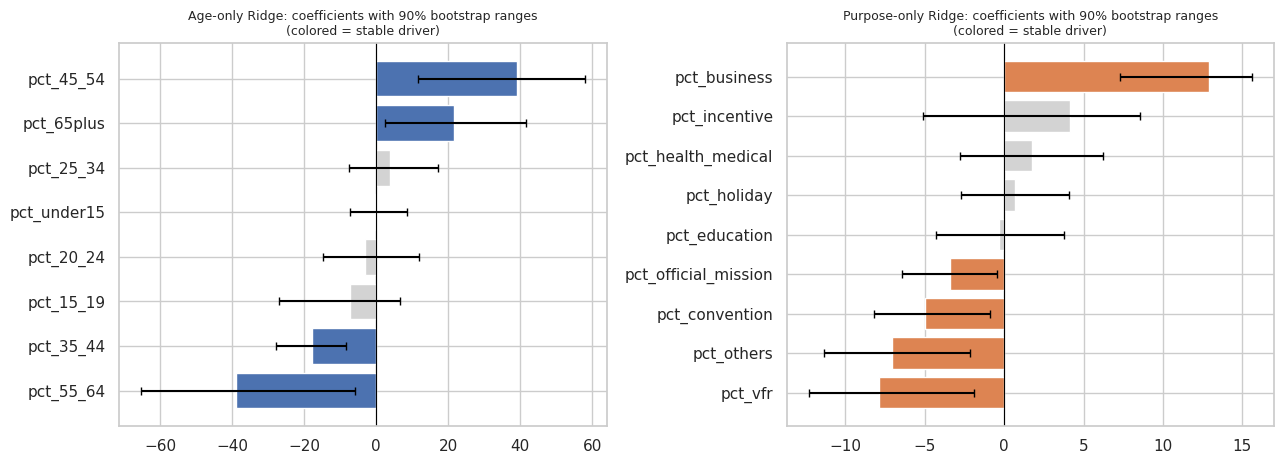

Random Forest, age-only, top 3 importances: {'pct_45_54': 0.37, 'pct_65plus': 0.16, 'pct_15_19': 0.14}
Random Forest, purpose-only, top 3 importances: {'pct_business': 0.31, 'pct_vfr': 0.19, 'pct_education': 0.1}


In [48]:
def ridge_coef_bootstrap(feats, data=pdf, n=N_BOOT, seed=SEED):
    X = data[feats].to_numpy(dtype=float); y = data[TARGET].to_numpy(dtype=float)
    full = make_model("ridge", len(y)).fit(X, y)
    alpha = full.named_steps["model"].alpha_
    coef_full = full.named_steps["model"].coef_
    rng = np.random.RandomState(seed); boots = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if np.ptp(y[i]) == 0:
            continue
        m = Pipeline([("scaler", SkStandardScaler()), ("model", Ridge(alpha=alpha))]).fit(X[i], y[i])
        boots.append(m.named_steps["model"].coef_)
    boots = np.array(boots)
    out = pd.DataFrame({"feature": feats, "coef": coef_full,
                        "ci90_low": np.percentile(boots, 5, axis=0),
                        "ci90_high": np.percentile(boots, 95, axis=0),
                        "sign_stability": (np.sign(boots) == np.sign(coef_full)).mean(axis=0)})
    out["stable_driver"] = out.sign_stability >= 0.90
    return out.sort_values("coef", ascending=False), alpha

coef_age, alpha_age = ridge_coef_bootstrap(RQ1_AGE)
coef_pur, alpha_pur = ridge_coef_bootstrap(RQ1_PURPOSE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (title, c, col) in zip(axes, [("Age-only Ridge", coef_age, "#4C72B0"),
                                      ("Purpose-only Ridge", coef_pur, "#DD8452")]):
    d = c.iloc[::-1]
    colors = [col if s else "lightgrey" for s in d.stable_driver]
    ax.barh(d.feature, d.coef, color=colors,
            xerr=[d.coef - d.ci90_low, d.ci90_high - d.coef], ecolor="black", capsize=3)
    ax.axvline(0, c="black", lw=0.8)
    ax.set_title(f"{title}: coefficients with 90% bootstrap ranges\n(colored = stable driver)", fontsize=9)
plt.tight_layout(); plt.show()

for feats, name in [(RQ1_AGE, "age"), (RQ1_PURPOSE, "purpose")]:
    rf = make_model("random_forest", len(pdf)).fit(pdf[feats].to_numpy(dtype=float), pdf[TARGET].to_numpy(dtype=float))
    imp = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False)
    print(f"Random Forest, {name}-only, top 3 importances:", imp.head(3).round(2).to_dict())

**What it shows:**
- **Higher search interest** goes with a higher **business** share and a higher **45–54** share.
- **Lower search interest** goes with higher **VFR, others, convention, and official-mission** shares.
- The Random Forest agrees on the top features (45–54 for age; business, then VFR, for purpose). These are links, not causes.

**Answer to RQ1:** age and purpose composition predicts relative search interest **moderately, and the signal is real** (29% less error than the baseline, p ≤ 0.01), and the Spark MLlib cross-check agrees. It mainly separates strong-interest markets from weak ones.

**Answer to RQ1a:** purpose shows a **somewhat stronger and more consistent** link (better ranking, more stable), but the difference from age is not decisive. Both carry real signal.

**Limits:** 21 countries and one year of data. Google Trends shows low-volume searches as 0 (Google, n.d.), and search data can carry biases across countries (Dergiades et al., 2018).

## Insights
- **For DOT and the Tourism Promotions Board:** a high-interest profile exists: markets with more **business travelers and travelers aged 45–54**. Online campaigns can start with these markets. This fits the digitalization goal of the National Tourism Development Plan (Department of Tourism [DOT], 2023), and search data is a known early signal of tourism demand (Yang et al., 2022).
- **Lead with purpose of travel.** Purpose ranks markets better and is easier to act on, for example "bleisure" packages that add leisure days to business trips (Lichy & McLeay, 2018).
- **Keep categories detailed.** Merging business with conventions and official missions hides the signal, because they move in opposite directions. Reports should keep them separate.
- **Use the model to screen, not to forecast.** It tells strong-interest markets from weak ones, but cannot rank the strong ones.
- **SDG 8 and SDG 12:** targeting the right markets uses promotion budgets better and helps grow arrivals from more markets, in line with the plan's goal to diversify markets (DOT, 2023).

# RQ2: Classification

## Exploratory Data Analysis

#### How Many Countries Are in Each Class?

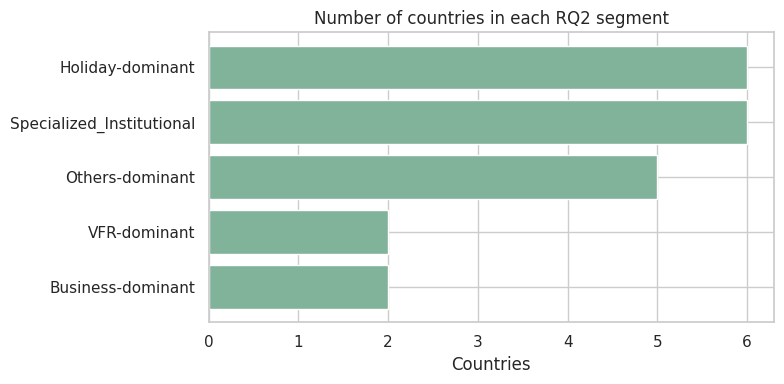

Baseline accuracy (always guessing the largest class): 28.6%


In [49]:
counts = rq2_df.groupBy("rq2_segment_label").count().orderBy("count").toPandas()
plt.figure(figsize=(8, 4))
plt.barh(counts["rq2_segment_label"], counts["count"], color="#81B29A")
plt.title("Number of countries in each RQ2 segment"); plt.xlabel("Countries"); plt.tight_layout(); plt.show()
print(f"Baseline accuracy (always guessing the largest class): {counts['count'].max() / 21:.1%}")

**What it shows:** the classes are uneven. Holiday-dominant and Specialized_Institutional have 6 countries each, Others-dominant has 5, and Business-dominant and VFR-dominant have only 2 each.
- Always guessing the biggest class would be right 28.6% of the time. **This is the baseline every RQ2 model must beat.**
- The two small classes are why cross-validation is needed: a single random split could leave one of them out of training completely.

#### Which Countries Are in Each Class?
The table lists each country's class, the purpose it stands out in most, and how strongly (its z-score).

In [50]:
(rq2_df.select("rq2_segment_label", "country", "rq2_zscore_raw_category", "rq2_zscore_value")
       .orderBy("rq2_segment_label", F.desc("rq2_zscore_value"))
       .show(21, truncate=False))

+-------------------------+-----------------+-----------------------+----------------+
|rq2_segment_label        |country          |rq2_zscore_raw_category|rq2_zscore_value|
+-------------------------+-----------------+-----------------------+----------------+
|Business-dominant        |Singapore        |business               |2.696           |
|Business-dominant        |Thailand         |business               |1.69            |
|Holiday-dominant         |South Korea      |holiday                |2.426           |
|Holiday-dominant         |Taiwan           |holiday                |1.506           |
|Holiday-dominant         |Brunei Darussalam|holiday                |1.319           |
|Holiday-dominant         |Macau            |holiday                |1.178           |
|Holiday-dominant         |Japan            |holiday                |0.985           |
|Holiday-dominant         |Hong Kong        |holiday                |0.692           |
|Others-dominant          |India           

**What it shows:**
- Most labels make sense: Singapore and Thailand stand out for business, South Korea and Taiwan for holidays, and Pakistan for visiting family.
- Six countries barely stand out in any purpose (score below 1), so models may get them wrong more often.
- Holiday-dominant is mostly Northeast Asia, and Others-dominant is mostly South Asia.

#### Do the Classes Have Different Age Profiles?
RQ2 asks whether age alone can predict the class. This heatmap shows the average age mix of each class.

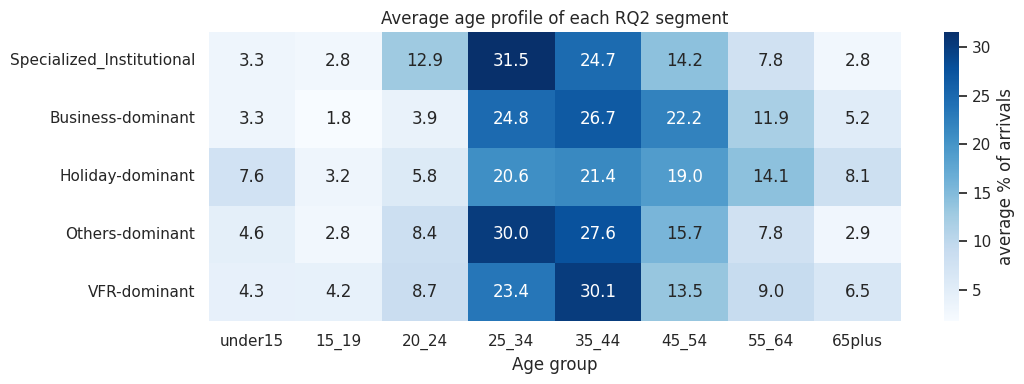

In [51]:
seg_age = (rq2_df.groupBy("rq2_segment_label")
           .agg(*[F.round(F.avg(f"pct_{c}"), 1).alias(c) for c in AGE_COLS])
           .toPandas().set_index("rq2_segment_label"))
plt.figure(figsize=(11, 4))
sns.heatmap(seg_age, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "average % of arrivals"})
plt.title("Average age profile of each RQ2 segment"); plt.ylabel(""); plt.xlabel("Age group")
plt.tight_layout(); plt.show()

**What it shows:** each class has a different age mix, so age may help predict the class.
- **Holiday-dominant:** most children (7.6%) and most travelers aged 55+ (22.2%), pointing to families and older tourists.
- **Specialized_Institutional:** most young adults (aged 20–34), likely students and young workers.
- **Business-dominant:** mostly aged 35–54.
- **VFR-dominant:** most aged 35–44.

Others-dominant and Specialized_Institutional look very similar, so the model may mix them up.

## Model Setup
- **Features:** age shares only. Purpose shares are left out because the labels are built from them (that would be leakage).
- **Two feature sets, both planned in preprocessing:** the 8 detailed age shares, and 4 grouped ones (under 15, 15–34, 35–54, 55+). With only 21 countries, fewer and broader features are easier to learn from.
- **Testing:** leave-one-country-out. Each country is predicted by a model trained on the other 20, as in RQ1.
- **Scores:** accuracy, plus **macro F1** and **balanced accuracy**, which count every class equally. With uneven classes (6, 6, 5, 2, 2), plain accuracy can look good while small classes are always missed (Sokolova & Lapalme, 2009).
- All models are Spark MLlib classifiers (Meng et al., 2016).

In [52]:
import warnings
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier, MultilayerPerceptronClassifier)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix
warnings.filterwarnings("ignore", category=UserWarning)
spark.sparkContext.setLogLevel("OFF")   # hides harmless optimizer messages from tiny training sets

RQ2_SEED = 42
RQ2_SETS = {"detailed_8": RQ2_FEATURES, "grouped_4": RQ2_FEATURES_GROUPED}
N_CLASSES = len(LABELS)

rq2_base = (rq2_df.select("country", "rq2_segment_label", F.col("label_index").cast("double").alias("label_index"),
                          *RQ2_FEATURES, *[c for c in RQ2_FEATURES_GROUPED if c not in RQ2_FEATURES])
            .coalesce(1).cache())
rq2_pd = rq2_base.toPandas()
y_true = rq2_pd["label_index"].astype(int).to_numpy()
rq2_countries = rq2_pd["country"].tolist()
baseline_acc = np.bincount(y_true).max() / len(y_true)
print("Countries:", len(y_true), "| class sizes:", dict(zip(LABELS, np.bincount(y_true))))
print(f"Baseline (always the largest class): {baseline_acc:.1%}")

def build(model_name, feats):
    # Assemble -> scale (scaling only matters for LR and MLP, harmless for trees) -> classifier
    clf = {
        "Logistic Regression": LogisticRegression(featuresCol="features", labelCol="label_index", maxIter=200, regParam=0.1),
        "Decision Tree": DecisionTreeClassifier(featuresCol="features", labelCol="label_index", maxDepth=3, seed=RQ2_SEED),
        "Random Forest": RandomForestClassifier(featuresCol="features", labelCol="label_index", numTrees=40, maxDepth=3, seed=RQ2_SEED),
        "Multilayer Perceptron": MultilayerPerceptronClassifier(featuresCol="features", labelCol="label_index",
                                                                layers=[len(feats), 6, N_CLASSES], maxIter=200,
                                                                blockSize=1, seed=RQ2_SEED),
    }[model_name]
    return SparkPipeline(stages=[VectorAssembler(inputCols=feats, outputCol="raw"),
                                 StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True),
                                 clf])

def scores(y, p):
    return {"accuracy": accuracy_score(y, p),
            "macro_f1": f1_score(y, p, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, p)}

def loo_predict(make_estimator, feats, data=rq2_base):
    # Leave one country out: each country is predicted by a model trained on the other 20
    preds, probs = [], []
    for c in rq2_countries:
        model = make_estimator(feats).fit(data.filter(F.col("country") != c))
        row = model.transform(data.filter(F.col("country") == c)).select("prediction", "probability").first()
        preds.append(int(row["prediction"])); probs.append(row["probability"].toArray())
    return np.array(preds), np.vstack(probs)

Countries: 21 | class sizes: {'Business-dominant': np.int64(2), 'Holiday-dominant': np.int64(6), 'Others-dominant': np.int64(5), 'Specialized_Institutional': np.int64(6), 'VFR-dominant': np.int64(2)}
Baseline (always the largest class): 28.6%


## Train and Tune
Four Spark models are compared on both feature sets: **Logistic Regression**, **Decision Tree**, **Random Forest** (Breiman, 2001), and **Multilayer Perceptron**. This runs 168 small models (about 3 minutes).

In [53]:
MODEL_NAMES = ["Logistic Regression", "Decision Tree", "Random Forest", "Multilayer Perceptron"]
oof = {}
rows = []
for set_name, feats in RQ2_SETS.items():
    for name in MODEL_NAMES:
        pred, prob = loo_predict(lambda f, n=name: build(n, f), feats)
        oof[(set_name, name)] = (pred, prob)
        rows.append({"feature_set": set_name, "model": name, **scores(y_true, pred)})
compare_df = pd.DataFrame(rows).sort_values(["macro_f1", "accuracy"], ascending=False).round(3)
compare_df

,feature_set,model,accuracy,macro_f1,balanced_accuracy
3,detailed_8,Multilayer Perceptron,0.476,0.329,0.340
7,grouped_4,Multilayer Perceptron,0.429,0.327,0.313
4,grouped_4,Logistic Regression,0.524,0.323,0.373
6,grouped_4,Random Forest,0.476,0.271,0.333
2,detailed_8,Random Forest,0.381,0.255,0.273
0,detailed_8,Logistic Regression,0.429,0.240,0.300
1,detailed_8,Decision Tree,0.286,0.199,0.207
5,grouped_4,Decision Tree,0.286,0.187,0.200


**What it shows:** with grouped ages, **Logistic Regression and Random Forest improve** to 52.4% accuracy (from 42.9% and 33.3% with detailed ages), against 28.6% for the baseline. The Multilayer Perceptron does not improve, and the Decision Tree does no better than the baseline.

**Tuning the main model:** Logistic Regression's penalty (`regParam`) is chosen by `CrossValidator` inside the 20 training countries of every round, so the held-out country is never used for tuning (Varma & Simon, 2006). This takes about 3 minutes.

In [54]:
def tuned_lr(feats):
    # regParam is chosen by 3-fold CrossValidator inside the 20 training countries only
    est = build("Logistic Regression", feats)
    lr = est.getStages()[-1]
    grid = ParamGridBuilder().addGrid(lr.regParam, [0.01, 0.1, 1.0]).build()
    return CrossValidator(estimator=est, estimatorParamMaps=grid, numFolds=3, seed=RQ2_SEED,
                          evaluator=MulticlassClassificationEvaluator(labelCol="label_index", metricName="f1"))

tuned_pred, tuned_prob = loo_predict(tuned_lr, RQ2_FEATURES_GROUPED)
oof[("grouped_4", "Logistic Regression (tuned)")] = (tuned_pred, tuned_prob)
print("Tuned Logistic Regression, grouped ages:", {k: round(v, 3) for k, v in scores(y_true, tuned_pred).items()})

Tuned Logistic Regression, grouped ages: {'accuracy': 0.524, 'macro_f1': 0.357, 'balanced_accuracy': np.float64(0.373)}


## Evaluation
**Voting ensembles:** hard voting takes the class most models pick; soft voting averages their probabilities (Kuncheva, 2004). Ties in hard voting are broken by the average probability, not by label order.

In [55]:
ens_set = "grouped_4"
member_preds = np.column_stack([oof[(ens_set, n)][0] for n in MODEL_NAMES])
member_probs = np.stack([oof[(ens_set, n)][1] for n in MODEL_NAMES])      # models x countries x classes
soft_prob = member_probs.mean(axis=0)
soft_pred = soft_prob.argmax(axis=1)

def hard_vote(i):
    counts = np.bincount(member_preds[i], minlength=N_CLASSES)
    tied = np.flatnonzero(counts == counts.max())
    return int(tied[np.argmax(soft_prob[i, tied])])     # ties broken by the average probability, not by label order
hard_pred = np.array([hard_vote(i) for i in range(len(y_true))])

final_rows = [{"model": f"{n} ({ens_set})", **scores(y_true, oof[(ens_set, n)][0])} for n in MODEL_NAMES]
final_rows += [{"model": "Logistic Regression, tuned (grouped_4)", **scores(y_true, tuned_pred)},
               {"model": "Hard voting (grouped_4)", **scores(y_true, hard_pred)},
               {"model": "Soft voting (grouped_4)", **scores(y_true, soft_pred)},
               {"model": "Baseline: largest class", "accuracy": baseline_acc,
                "macro_f1": f1_score(y_true, np.full_like(y_true, np.bincount(y_true).argmax()), average="macro", zero_division=0),
                "balanced_accuracy": 1 / N_CLASSES}]
final_df = pd.DataFrame(final_rows).sort_values("macro_f1", ascending=False).round(3)
final_df

,model,accuracy,macro_f1,balanced_accuracy
4,"Logistic Regression, tuned (grouped_4)",0.524,0.357,0.373
3,Multilayer Perceptron (grouped_4),0.429,0.327,0.313
0,Logistic Regression (grouped_4),0.524,0.323,0.373
5,Hard voting (grouped_4),0.476,0.285,0.333
2,Random Forest (grouped_4),0.476,0.271,0.333
6,Soft voting (grouped_4),0.381,0.247,0.267
1,Decision Tree (grouped_4),0.286,0.187,0.200
7,Baseline: largest class,0.286,0.089,0.200


**What it shows:**
- **Tuned Logistic Regression is the best model:** 52.4% accuracy, macro F1 0.36, and balanced accuracy 0.37, against 28.6%, 0.09, and 0.20 for the baseline.
- The ensembles do not beat it: hard voting ties on accuracy (52.4%), and soft voting is lower (42.9%), because the weak Decision Tree pulls the vote down.

#### Could Chance Produce This? (Permutation Test)
The segment labels are shuffled 100 times and the model is retrained each time on the same 3-fold split. The **p-value** is the share of shuffled runs that score as well as the real labels (Ojala & Garriga, 2010). This takes about 4 minutes.

Real macro F1 0.314 | shuffled median 0.111 | p = 0.010


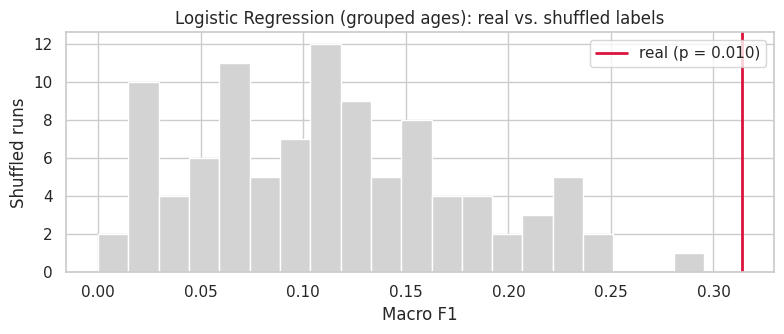

In [56]:
# Real vs shuffled labels, same fixed 3-fold stratified split (Logistic Regression, grouped ages)
def kfold_predict(labels, feats, splits):
    data = rq2_pd.assign(label_index=labels.astype(float))
    pred = np.empty(len(labels), dtype=int)
    for tr, te in splits:
        m = build("Logistic Regression", feats).fit(spark.createDataFrame(data.iloc[tr]))
        pred[te] = [int(r["prediction"]) for r in m.transform(spark.createDataFrame(data.iloc[te])).select("prediction").collect()]
    return pred

N_PERM = 100
splits = list(StratifiedKFold(3, shuffle=True, random_state=RQ2_SEED).split(rq2_pd, y_true))
real_f1 = f1_score(y_true, kfold_predict(y_true, RQ2_FEATURES_GROUPED, splits), average="macro", zero_division=0)
rng = np.random.RandomState(RQ2_SEED)
null_f1 = np.array([f1_score(yp, kfold_predict(yp, RQ2_FEATURES_GROUPED, splits), average="macro", zero_division=0)
                    for yp in (rng.permutation(y_true) for _ in range(N_PERM))])
p_value = (1 + np.sum(null_f1 >= real_f1)) / (N_PERM + 1)
print(f"Real macro F1 {real_f1:.3f} | shuffled median {np.median(null_f1):.3f} | p = {p_value:.3f}")

plt.figure(figsize=(8, 3.5))
plt.hist(null_f1, bins=20, color="lightgrey", edgecolor="white")
plt.axvline(real_f1, color="crimson", lw=2, label=f"real (p = {p_value:.3f})")
plt.xlabel("Macro F1"); plt.ylabel("Shuffled runs"); plt.legend()
plt.title("Logistic Regression (grouped ages): real vs. shuffled labels"); plt.tight_layout(); plt.show()

**What it shows:** real macro F1 is 0.31 versus a shuffled median of 0.11, with **p = 0.01**. Age carries real information about a market's purpose segment, not just chance.

#### Which Segments Does the Model Get Right?

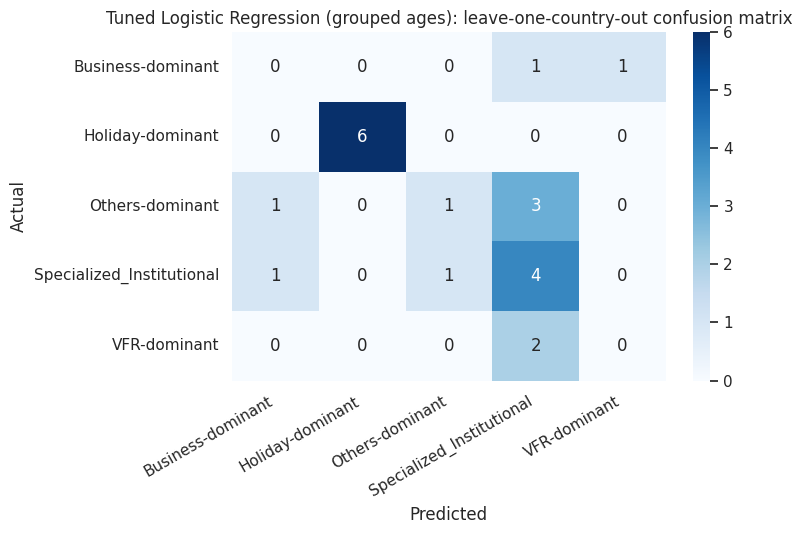

Recall per class: {'Business-dominant': np.float64(0.0), 'Holiday-dominant': np.float64(1.0), 'Others-dominant': np.float64(0.2), 'Specialized_Institutional': np.float64(0.67), 'VFR-dominant': np.float64(0.0)}


In [57]:
best_pred = tuned_pred
cm = confusion_matrix(y_true, best_pred, labels=list(range(N_CLASSES)))
plt.figure(figsize=(8, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Tuned Logistic Regression (grouped ages): leave-one-country-out confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
print("Recall per class:", {LABELS[k]: round(cm[k, k] / cm[k].sum(), 2) for k in range(N_CLASSES)})

**What it shows:**
- **Holiday-dominant: all 6 correct.** Specialized_Institutional: 4 of 6.
- **Business-dominant and VFR-dominant: 0 correct.** Each has only 2 countries, too few to learn from. Others-dominant (1 of 5) is mostly confused with Specialized_Institutional, as the EDA warned.

## Interpretation
#### RQ2a: Which Age Groups Distinguish Each Segment?
Logistic Regression is fit on all 21 countries. A positive coefficient means more of that age group pushes a market toward the segment; a negative one pushes it away.

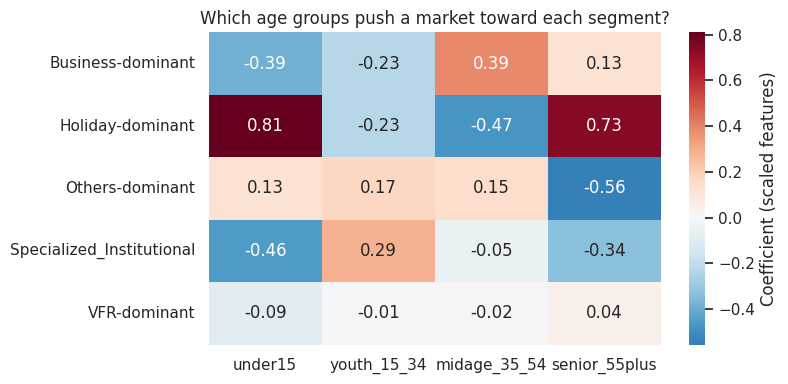

In [58]:
lr_full = build("Logistic Regression", RQ2_FEATURES_GROUPED).fit(rq2_base).stages[-1]
coef = pd.DataFrame(lr_full.coefficientMatrix.toArray(), index=LABELS,
                    columns=[c.replace("pct_", "") for c in RQ2_FEATURES_GROUPED])
plt.figure(figsize=(8, 4))
sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "Coefficient (scaled features)"})
plt.title("Which age groups push a market toward each segment?"); plt.tight_layout(); plt.show()
spark.sparkContext.setLogLevel("ERROR")

**Answer to RQ2a:**
- **Holiday-dominant:** more **children (under 15)** and **seniors (55+)**, fewer 35–54. These look like family and retiree trips, the same profile as RQ3's Mature Leisure persona.
- **Specialized_Institutional:** more **young adults (15–34)**, fewer children and seniors, consistent with study, training, and official trips.
- **Business-dominant:** more **35–54** travelers (working age).
- **Others-dominant:** fewer seniors. **VFR-dominant:** no clear age pattern (all coefficients near 0).

**Answer to RQ2:** age alone predicts a market's purpose segment **better than chance but only moderately** (52.4% vs. 28.6%, p = 0.01). It identifies Holiday-dominant markets reliably and cannot identify the two smallest segments. These coefficients come from 21 countries, so they show patterns, not causes.

## Insights
- **For DOT and the Tourism Promotions Board:** age data alone reliably flags **holiday markets** (many children and seniors). These markets fit family and senior-friendly leisure products.
- **Age is not enough for the other segments.** Business and VFR markets can only be identified from purpose data, so DOT's purpose-by-country tables remain essential.
- **Young-adult-heavy markets** lean toward study, training, and official trips, which fits the National Tourism Development Plan's push for education and MICE tourism (Department of Tourism [DOT], 2023).
- **SDG 8 and SDG 12:** using visitor profiles to match products to markets supports more targeted, less wasteful promotion.

**Limitation:** 21 countries, uneven classes, and two classes with only 2 countries each.

# RQ3: Clustering

## Exploratory Data Analysis

#### Age and Purpose Mix of Every Country
These heatmaps show each country's age and purpose shares. Countries are grouped by region and then sorted by holiday share.

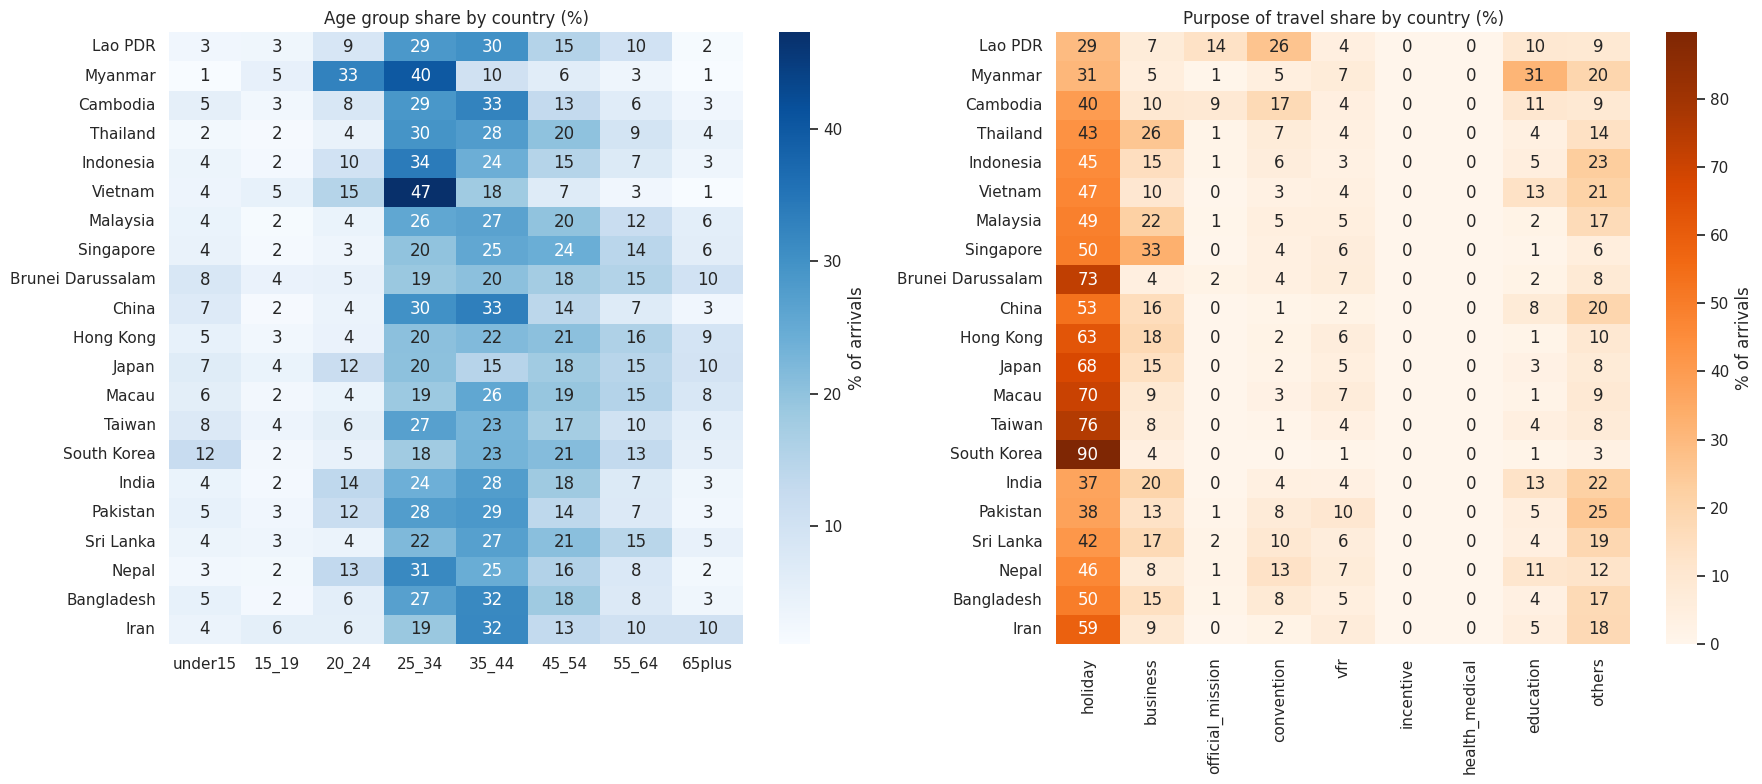

In [59]:
age_cols = [f"pct_{c}" for c in AGE_COLS]
pur_cols = [f"pct_{c}" for c in PURPOSE_COLS]
order = pdf_master.sort_values(["region", "pct_holiday"]).index

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.heatmap(pdf_master.loc[order, age_cols].rename(columns=lambda c: c.replace("pct_", "")),
            annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar_kws={"label": "% of arrivals"})
axes[0].set_title("Age group share by country (%)")
sns.heatmap(pdf_master.loc[order, pur_cols].rename(columns=lambda c: c.replace("pct_", "")),
            annot=True, fmt=".0f", cmap="Oranges", ax=axes[1], cbar_kws={"label": "% of arrivals"})
axes[1].set_title("Purpose of travel share by country (%)")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()

**What it shows:**
- Ages 25–44 are the biggest group in every country.
- Holiday is the top purpose almost everywhere, from 29% (Lao PDR) to 90% (South Korea).
- Some countries look alike: Northeast Asia leans toward holiday trips and older travelers, while Lao PDR, Myanmar, and Cambodia lean toward younger travelers and official, convention, or study trips.
- Incentive and health/medical are almost zero everywhere.

#### How Much Does Each Feature Vary?
This chart shows the standard deviation of each clustering feature: how much it changes from country to country.

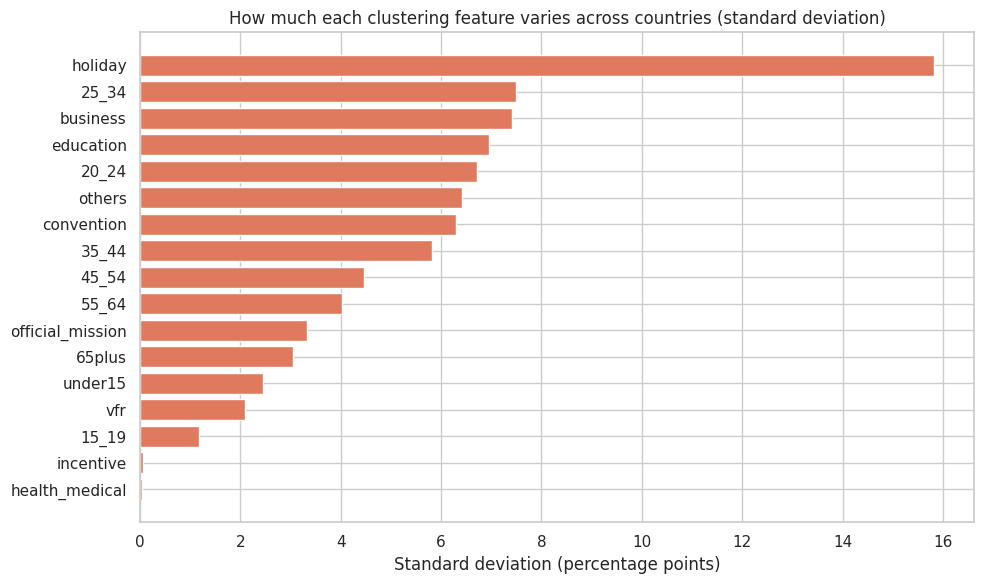

Largest spread: pct_holiday (15.8) | Smallest: pct_health_medical (0.04)


In [60]:
spread = (rq3_df.agg(*[F.stddev(c).alias(c) for c in RQ3_FEATURES]).toPandas().T[0]
                 .sort_values())
plt.figure(figsize=(10, 6))
plt.barh(spread.index.str.replace("pct_", ""), spread.values, color="#E07A5F")
plt.title("How much each clustering feature varies across countries (standard deviation)")
plt.xlabel("Standard deviation (percentage points)"); plt.tight_layout(); plt.show()
print(f"Largest spread: {spread.idxmax()} ({spread.max():.1f}) | Smallest: {spread.idxmin()} ({spread.min():.2f})")

**What it shows:**
- Holiday varies the most (about 16 points); incentive and health/medical barely vary.
- K-Means groups by distance, so without scaling, holiday alone would decide the clusters. Features are therefore scaled.
- Scaling would also give the two near-zero features full weight, so RQ3 tests clustering with and without them.

#### A Preview of Natural Groupings (PCA)
PCA (Principal Component Analysis) squeezes the 17 scaled features into 2 summary axes so all countries can be shown on one flat chart. Countries close together have similar age and purpose mixes. Colors show DOT's official regions.

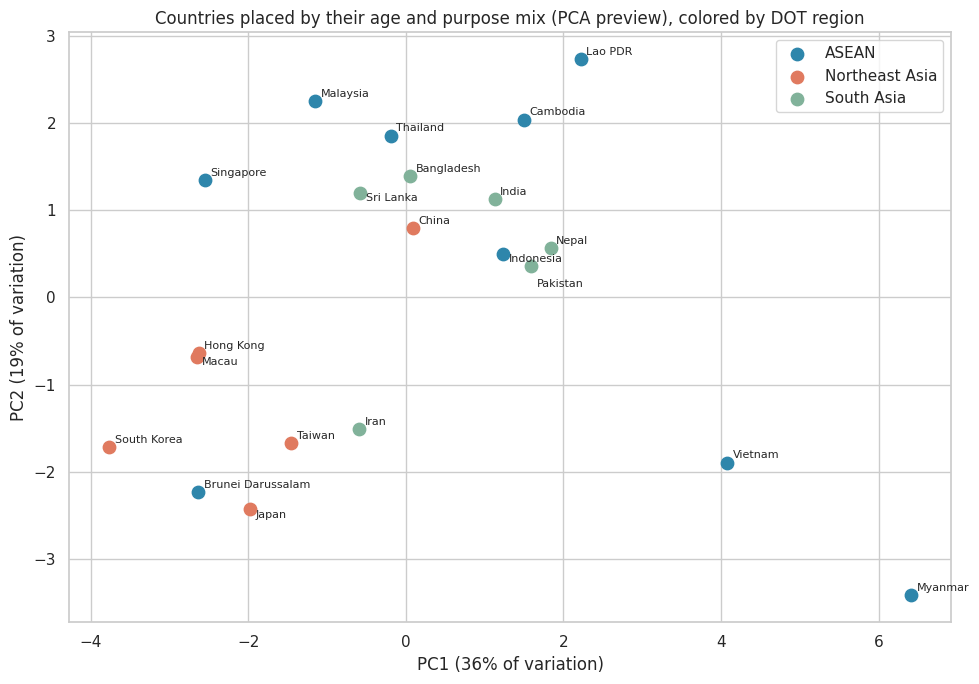

The two axes together show 55% of the variation in the 17 features.


In [61]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA

vec = VectorAssembler(inputCols=RQ3_FEATURES, outputCol="raw").transform(rq3_df)
scaled = StandardScaler(inputCol="raw", outputCol="scaled", withMean=True, withStd=True).fit(vec).transform(vec)
pca_model = PCA(k=2, inputCol="scaled", outputCol="pc").fit(scaled)
pcs = pca_model.transform(scaled).select("country", "region", "pc").toPandas()
pcs["PC1"] = pcs["pc"].apply(lambda v: float(v[0])); pcs["PC2"] = pcs["pc"].apply(lambda v: float(v[1]))

plt.figure(figsize=(10, 7))
for region, color in REGION_COLORS.items():
    sub = pcs[pcs["region"] == region]
    plt.scatter(sub["PC1"], sub["PC2"], s=80, color=color, label=region.replace("_", " "))
label_points(plt.gca(), pcs["PC1"].tolist(), pcs["PC2"].tolist(), pcs["country"].tolist())
explained = pca_model.explainedVariance.toArray()
plt.xlabel(f"PC1 ({explained[0]:.0%} of variation)"); plt.ylabel(f"PC2 ({explained[1]:.0%} of variation)")
plt.title("Countries placed by their age and purpose mix (PCA preview), colored by DOT region")
plt.legend(); plt.tight_layout(); plt.show()
print(f"The two axes together show {explained.sum():.0%} of the variation in the 17 features.")

**What it shows:** this 2D view keeps 55% of the differences, so it is a rough preview. Most Northeast Asian countries sit together (with Brunei), China sits near South Asia, and Vietnam and Myanmar sit apart. This hints that clusters may not match DOT's regions (RQ3a).

## Model Setup
Two feature sets are prepared and scaled so every feature counts equally in the distance calculation.
- **Set A (17 features):** all 8 age and 9 purpose shares.
- **Set B (15 features):** drops incentive and health/medical, which barely vary (EDA) and may only add noise after scaling.

**Scaling:** `StandardScaler` divides each feature by its standard deviation. `withMean=False` is used because Bisecting K-Means fails on data centered at zero; centering does not change distances, so K-Means is not affected.

Clustering has no target or test set, so fitting the scaler on all 21 countries causes no leakage.

In [62]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans, BisectingKMeans
from pyspark.ml.evaluation import ClusteringEvaluator

FEATURE_SETS = {
    "A (17 features)": RQ3_FEATURES,
    "B (15 features)": [c for c in RQ3_FEATURES if c not in ("pct_incentive", "pct_health_medical")],
}

def scale_features(cols):
    # coalesce(1) keeps the data in one partition so results are the same on every run
    assembled = VectorAssembler(inputCols=cols, outputCol="raw").transform(rq3_df.coalesce(1))
    scaler = StandardScaler(inputCol="raw", outputCol="features", withMean=False, withStd=True)
    return (scaler.fit(assembled).transform(assembled)
            .select("country", "region", "rq2_segment_label", "features").cache())

scaled_sets = {name: scale_features(cols) for name, cols in FEATURE_SETS.items()}
for name, data in scaled_sets.items():
    print(f"Set {name}: {data.count()} countries")

Set A (17 features): 21 countries
Set B (15 features): 21 countries


## Train and Tune
**K-Means** and **Bisecting K-Means** (Steinbach et al., 2000) are trained on both feature sets for k = 2 to 8.
- **K-Means** moves k centers until each country is as close as possible to its center. Spark starts it with the k-means|| method (Bahmani et al., 2012), which depends on a random seed.
- **Bisecting K-Means** starts with one group and keeps splitting the largest one in two.
- Each setting is run with 5 seeds, and the tightest run (lowest WSSSE) is kept. This trains 140 models and takes a few minutes.

In [63]:
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="cluster",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")
ALGORITHMS = {"K-Means": KMeans, "Bisecting K-Means": BisectingKMeans}
K_VALUES = range(2, 9)
SEEDS = range(1, 6)

results, models = [], {}
for set_name, data in scaled_sets.items():
    for alg_name, Algorithm in ALGORITHMS.items():
        for k in K_VALUES:
            fits = [Algorithm(k=k, seed=s, maxIter=50, featuresCol="features", predictionCol="cluster").fit(data)
                    for s in SEEDS]
            model = min(fits, key=lambda m: m.summary.trainingCost)   # keep the tightest run
            sizes = sorted(model.summary.clusterSizes, reverse=True)
            results.append({"feature_set": set_name, "algorithm": alg_name, "k": k,
                            "wssse": round(model.summary.trainingCost, 1),
                            "silhouette": round(evaluator.evaluate(model.transform(data)), 3),
                            "cluster_sizes": sizes, "smallest_cluster": sizes[-1]})
            models[(set_name, alg_name, k)] = model

results_df = pd.DataFrame(results)
print(len(results_df), "settings trained")

28 settings trained


## Evaluation
- **WSSSE:** total distance from each country to its cluster center. It always drops as k grows, so we look for the **elbow**, where adding a cluster stops helping much (Thorndike, 1953).
- **Silhouette score (−1 to 1):** how close each country is to its own cluster versus the next one (Rousseeuw, 1987). Kaufman and Rousseeuw (1990) read it as: **0.71–1.00 strong**, **0.51–0.70 reasonable**, **0.26–0.50 weak**, and **0.25 or below no real structure**.

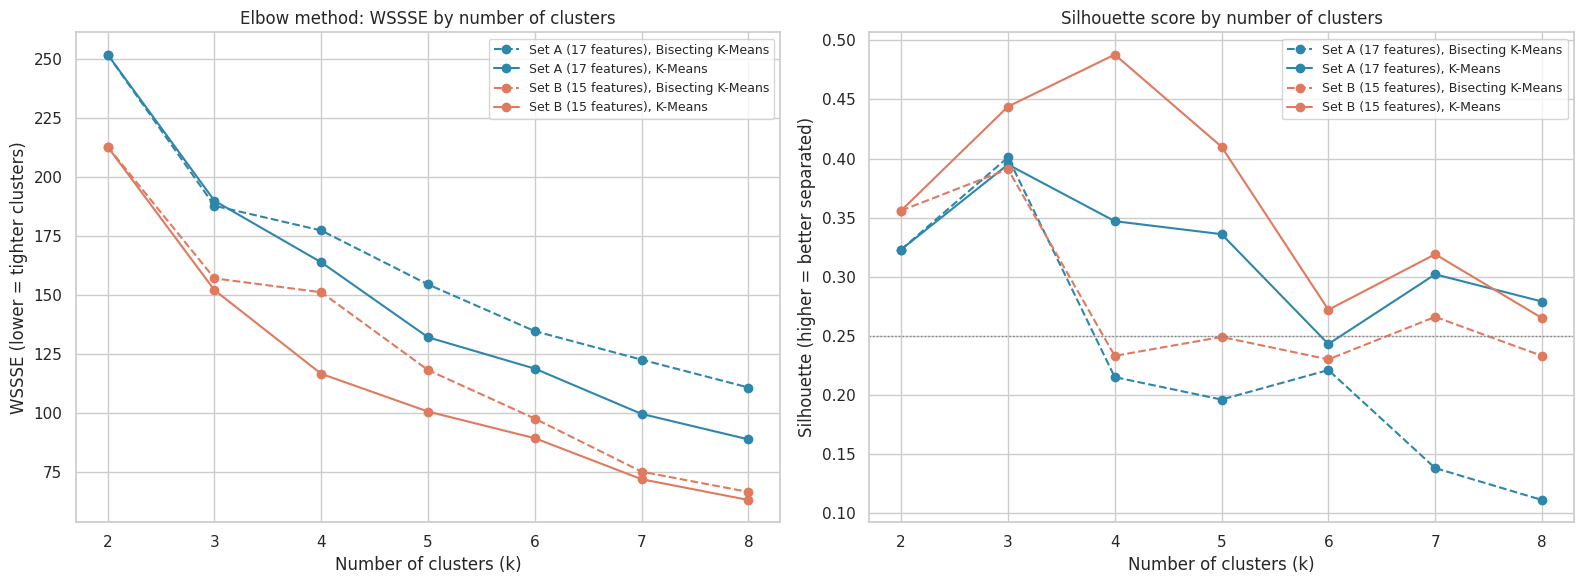

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
styles = {("A (17 features)", "K-Means"): ("#2E86AB", "-"), ("A (17 features)", "Bisecting K-Means"): ("#2E86AB", "--"),
          ("B (15 features)", "K-Means"): ("#E07A5F", "-"), ("B (15 features)", "Bisecting K-Means"): ("#E07A5F", "--")}
for (set_name, alg_name), grp in results_df.groupby(["feature_set", "algorithm"]):
    color, line = styles[(set_name, alg_name)]
    label = f"Set {set_name}, {alg_name}"
    axes[0].plot(grp["k"], grp["wssse"], marker="o", color=color, linestyle=line, label=label)
    axes[1].plot(grp["k"], grp["silhouette"], marker="o", color=color, linestyle=line, label=label)
axes[0].set_title("Elbow method: WSSSE by number of clusters"); axes[0].set_ylabel("WSSSE (lower = tighter clusters)")
axes[1].set_title("Silhouette score by number of clusters"); axes[1].set_ylabel("Silhouette (higher = better separated)")
axes[1].axhline(0.25, color="gray", linestyle=":", linewidth=1)
for ax in axes:
    ax.set_xlabel("Number of clusters (k)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**What it shows:**
- **Set B with K-Means has the best silhouette at every k**, so dropping the two near-constant features helped.
- For Set B with K-Means, WSSSE drops sharply up to k = 4 (212.9 → 152.1 → 116.6) and then flattens, and the silhouette peaks at k = 4 (0.488).

**Choosing the final model:** keep settings where every cluster has at least 2 countries (a one-country cluster is an outlier, not a segment), then pick the highest silhouette.

In [65]:
candidates = results_df[results_df["smallest_cluster"] >= 2].sort_values("silhouette", ascending=False)
display(candidates.head(5).reset_index(drop=True))
print("For comparison, k = 3:")
display(results_df[results_df["k"] == 3].reset_index(drop=True))

best = candidates.iloc[0]
BEST_SET, BEST_ALG, BEST_K = best["feature_set"], best["algorithm"], int(best["k"])
print(f"Final model: {BEST_ALG}, feature set {BEST_SET}, k = {BEST_K} "
      f"(silhouette {best['silhouette']}, WSSSE {best['wssse']})")

,feature_set,algorithm,k,wssse,silhouette,cluster_sizes,smallest_cluster
0,B (15 features),K-Means,4,116.6,0.488,"[10, 7, 2, 2]",2
1,B (15 features),K-Means,3,152.1,0.444,"[11, 8, 2]",2
2,A (17 features),Bisecting K-Means,3,187.9,0.401,"[11, 8, 2]",2
3,A (17 features),K-Means,3,190.0,0.395,"[12, 7, 2]",2
4,B (15 features),Bisecting K-Means,3,157.1,0.391,"[10, 9, 2]",2


For comparison, k = 3:


,feature_set,algorithm,k,wssse,silhouette,cluster_sizes,smallest_cluster
0,A (17 features),K-Means,3,190.0,0.395,"[12, 7, 2]",2
1,A (17 features),Bisecting K-Means,3,187.9,0.401,"[11, 8, 2]",2
2,B (15 features),K-Means,3,152.1,0.444,"[11, 8, 2]",2
3,B (15 features),Bisecting K-Means,3,157.1,0.391,"[10, 9, 2]",2


Final model: K-Means, feature set B (15 features), k = 4 (silhouette 0.488, WSSSE 116.6)


**Result:** the final model is **K-Means, Set B, k = 4** (silhouette 0.488). This is at the top of the "weak" range and just below "reasonable" (Kaufman & Rousseeuw, 1990), so the clusters are a useful but **rough** grouping, not sharp boundaries.

In [66]:
final_model = models[(BEST_SET, BEST_ALG, BEST_K)]
final_cols = FEATURE_SETS[BEST_SET]
clustered = final_model.transform(scaled_sets[BEST_SET]).select("country", "region", "rq2_segment_label", "cluster")

# Spark numbers clusters 0..k-1 in no particular order. We attach a persona name to each cluster
# using one well-known member country, so the names stay correct even if the numbers change.
PERSONA_ANCHORS = {"Japan": "Mature Leisure Markets",
                   "India": "Mixed Leisure-Business Markets",
                   "Lao PDR": "Official and MICE Markets",
                   "Vietnam": "Young Education Markets"}
anchor_rows = clustered.filter(F.col("country").isin(list(PERSONA_ANCHORS))).collect()
cluster_to_persona = {r["cluster"]: PERSONA_ANCHORS[r["country"]] for r in anchor_rows}
assert len(cluster_to_persona) == BEST_K, "Two anchor countries share a cluster. Check the cluster members below."

persona_map = F.create_map(*[F.lit(x) for kv in cluster_to_persona.items() for x in kv])
clustered = clustered.withColumn("persona", persona_map[F.col("cluster")])

(clustered.groupBy("persona")
    .agg(F.count("*").alias("countries"), F.concat_ws(", ", F.sort_array(F.collect_list("country"))).alias("members"))
    .orderBy(F.desc("countries")).show(truncate=False))

+------------------------------+---------+----------------------------------------------------------------------------------------------+
|persona                       |countries|members                                                                                       |
+------------------------------+---------+----------------------------------------------------------------------------------------------+
|Mixed Leisure-Business Markets|10       |Bangladesh, China, India, Indonesia, Malaysia, Nepal, Pakistan, Singapore, Sri Lanka, Thailand|
|Mature Leisure Markets        |7        |Brunei Darussalam, Hong Kong, Iran, Japan, Macau, South Korea, Taiwan                         |
|Official and MICE Markets     |2        |Cambodia, Lao PDR                                                                             |
|Young Education Markets       |2        |Myanmar, Vietnam                                                                              |
+------------------------------+--

## Interpretation
#### What Each Cluster Looks Like
Average age and purpose shares (%, before scaling) of each cluster.

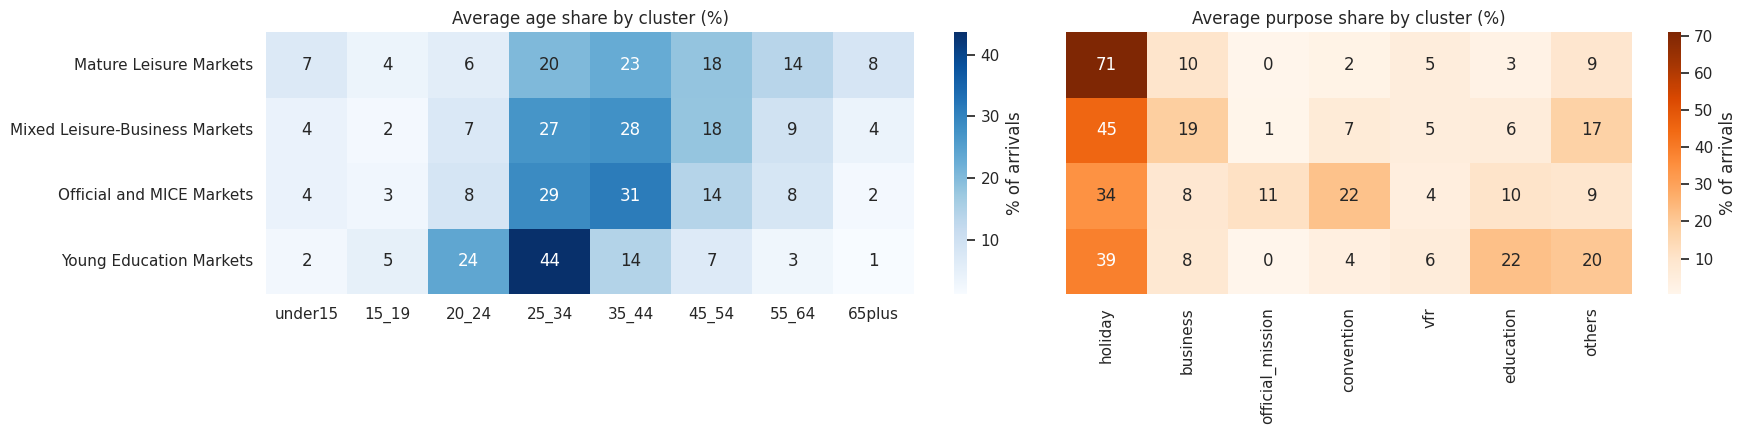

In [67]:
PERSONA_ORDER = ["Mature Leisure Markets", "Mixed Leisure-Business Markets",
                 "Official and MICE Markets", "Young Education Markets"]
profile = (rq3_df.join(clustered.select("country", "persona"), "country")
    .groupBy("persona").agg(*[F.avg(c).alias(c) for c in final_cols]).toPandas()
    .set_index("persona").loc[PERSONA_ORDER])
profile.columns = [c.replace("pct_", "") for c in profile.columns]
age_names = [c for c in AGE_COLS]
purpose_names = [c for c in PURPOSE_COLS if c in profile.columns]

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={"width_ratios": [8, 7]})
sns.heatmap(profile[age_names], annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar_kws={"label": "% of arrivals"})
axes[0].set_title("Average age share by cluster (%)")
sns.heatmap(profile[purpose_names], annot=True, fmt=".0f", cmap="Oranges", ax=axes[1], cbar_kws={"label": "% of arrivals"})
axes[1].set_title("Average purpose share by cluster (%)")
for ax in axes: ax.set_ylabel("")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Visitor personas:**
- **Mature Leisure** (Brunei, Hong Kong, Iran, Japan, Macau, South Korea, Taiwan): 71% holiday trips, the most travelers aged 55+ (22%) and the most children (7%).
- **Mixed Leisure-Business** (Bangladesh, China, India, Indonesia, Malaysia, Nepal, Pakistan, Singapore, Sri Lanka, Thailand): 45% holiday and the highest business share (19%).
- **Official and MICE** (Cambodia, Lao PDR): conventions (22%) and official missions (11%) make up a third of trips. MICE means Meetings, Incentives, Conventions, and Exhibitions.
- **Young Education** (Myanmar, Vietnam): two in three travelers are aged 20–34, and education is the highest of any group (22%).

#### Where the Clusters Sit (PCA View)
Colors show clusters; marker shapes show DOT regions.

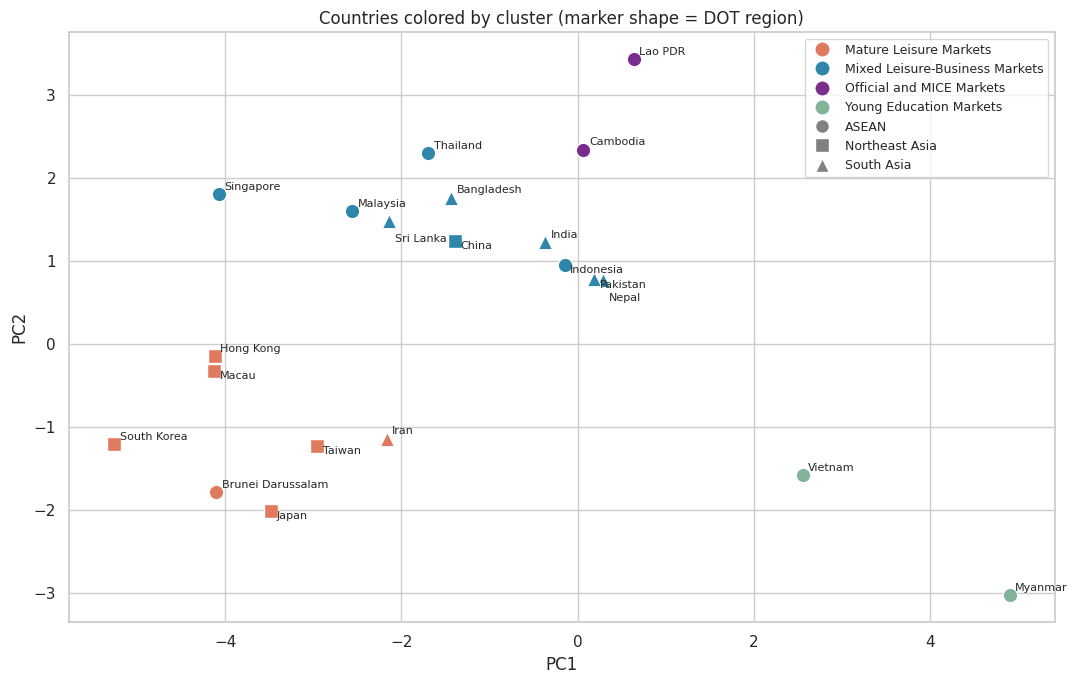

In [68]:
from pyspark.ml.feature import PCA

pca_in = scaled_sets[BEST_SET].join(clustered.select("country", "persona"), "country")
pca_fit = PCA(k=2, inputCol="features", outputCol="pc").fit(pca_in)
pc_df = pca_fit.transform(pca_in).select("country", "region", "persona", "pc").toPandas()
pc_df["PC1"] = pc_df["pc"].apply(lambda v: float(v[0])); pc_df["PC2"] = pc_df["pc"].apply(lambda v: float(v[1]))

PERSONA_COLORS = dict(zip(PERSONA_ORDER, ["#E07A5F", "#2E86AB", "#7B2D8E", "#81B29A"]))
REGION_MARKERS = {"ASEAN": "o", "Northeast_Asia": "s", "South_Asia": "^"}

plt.figure(figsize=(11, 7))
for persona, color in PERSONA_COLORS.items():
    for region, marker in REGION_MARKERS.items():
        sub = pc_df[(pc_df["persona"] == persona) & (pc_df["region"] == region)]
        if len(sub):
            plt.scatter(sub["PC1"], sub["PC2"], s=110, color=color, marker=marker, edgecolor="white")
label_points(plt.gca(), pc_df["PC1"].tolist(), pc_df["PC2"].tolist(), pc_df["country"].tolist())
from matplotlib.lines import Line2D
handles = ([Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=11, label=p) for p, c in PERSONA_COLORS.items()]
           + [Line2D([0], [0], marker=m, color="w", markerfacecolor="gray", markersize=10, label=r.replace("_", " "))
              for r, m in REGION_MARKERS.items()])
plt.legend(handles=handles, loc="best", fontsize=9)
plt.title("Countries colored by cluster (marker shape = DOT region)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.show()

**What it shows:** the four clusters sit in separate areas, and each cluster mixes marker shapes, so clusters cut across DOT regions.

#### RQ3a: Do the Clusters Match DOT's Regions and the RQ2 Segments?
**Purity** is the share of countries that belong to the most common region (or segment) in their cluster. A purity of 1.0 would mean the clusters copy the regions.

In [69]:
cmp_pdf = clustered.toPandas()
print("Clusters vs. DOT regions")
display(pd.crosstab(cmp_pdf["persona"], cmp_pdf["region"]).loc[PERSONA_ORDER])
print("Clusters vs. RQ2 purpose segments")
display(pd.crosstab(cmp_pdf["persona"], cmp_pdf["rq2_segment_label"]).loc[PERSONA_ORDER])

def purity(col):
    return pd.crosstab(cmp_pdf["persona"], cmp_pdf[col]).max(axis=1).sum() / len(cmp_pdf)
print(f"Purity vs. DOT regions: {purity('region'):.2f} | Purity vs. RQ2 segments: {purity('rq2_segment_label'):.2f}")

Clusters vs. DOT regions


region,ASEAN,Northeast_Asia,South_Asia
persona,,,
Mature Leisure Markets,1,5,1
Mixed Leisure-Business Markets,4,1,5
Official and MICE Markets,2,0,0
Young Education Markets,2,0,0


Clusters vs. RQ2 purpose segments


rq2_segment_label,Business-dominant,Holiday-dominant,Others-dominant,Specialized_Institutional,VFR-dominant
persona,,,,,
Mature Leisure Markets,0,6,0,0,1
Mixed Leisure-Business Markets,2,0,4,3,1
Official and MICE Markets,0,0,0,2,0
Young Education Markets,0,0,1,1,0


Purity vs. DOT regions: 0.67 | Purity vs. RQ2 segments: 0.62


**Answer to RQ3:** four visitor personas emerge: **Mature Leisure** (holiday trips, children and seniors), **Mixed Leisure-Business**, **Official and MICE** (Cambodia, Lao PDR), and **Young Education** (Myanmar, Vietnam). The silhouette (0.488) shows real but rough groups (Kaufman & Rousseeuw, 1990).

**Answer to RQ3a:** the clusters **do not follow DOT's regions** (purity 0.67).
- Five of six Northeast Asian markets form the core of Mature Leisure, but **China** joins the mixed group.
- **ASEAN splits across all four clusters.**
- Purity against the RQ2 segments is 0.62: age, not just purpose, separates Myanmar and Vietnam.

This supports grouping markets by data on how they travel rather than by fixed categories like geography (Dolnicar, 2004).

#### How Big Is Each Cluster? (Business Context)
These columns were **not** used for clustering.

In [70]:
context = (clustered.join(master_df.select("country", "arrivals_2024", "recovery_ratio",
                                           "search_interest_index_mean", "is_visa_free"), "country")
    .groupBy("persona")
    .agg(F.count("*").alias("countries"),
         F.sum("arrivals_2024").alias("arrivals_2024"),
         F.round(F.avg("recovery_ratio"), 2).alias("avg_recovery_vs_2019"),
         F.round(F.expr("percentile(search_interest_index_mean, 0.5)"), 1).alias("median_search_interest"),
         F.sum(F.col("is_visa_free").cast("int")).alias("visa_free_countries")))
total_arrivals = context.agg(F.sum("arrivals_2024")).first()[0]
context_pdf = (context.withColumn("share_of_asian_arrivals_pct", F.round(F.col("arrivals_2024") / total_arrivals * 100, 1))
               .toPandas().set_index("persona").loc[PERSONA_ORDER])
context_pdf["arrivals_2024"] = context_pdf["arrivals_2024"].astype(int)
display(context_pdf)

,countries,arrivals_2024,avg_recovery_vs_2019,median_search_interest,visa_free_countries,share_of_asian_arrivals_pct
persona,,,,,,
Mature Leisure Markets,7,2256952,0.66,56.2,6,73.0
Mixed Leisure-Business Markets,10,763196,0.66,27.9,5,24.7
Official and MICE Markets,2,5123,0.72,3.5,2,0.2
Young Education Markets,2,67241,0.76,5.4,2,2.2


**What it shows:**
- **Mature Leisure brings 73% of arrivals**; South Korea alone brings about half (51%).
- **Mixed Leisure-Business brings about 25%** and holds the slowest-recovering market (China, 0.18).
- The two small clusters bring about 2.4% of arrivals and have very low search interest, but they recovered the most (0.72 and 0.76).

## Insights
- **For DOT and the Tourism Promotions Board:** plan campaigns by persona, not by region, since one region holds very different travelers (Dolnicar, 2004). This also supports the National Tourism Development Plan's goal to diversify markets (Department of Tourism [DOT], 2023).
- **Mixed Leisure-Business:** offer "bleisure" packages that add leisure days to business trips (Lichy & McLeay, 2018).
- **Official and MICE (Cambodia, Lao PDR):** grow them through meetings and events, which the plan lists as high-value tourism (DOT, 2023).
- **Young Education (Myanmar, Vietnam):** students also attract visits from family and friends (Bischoff & Koenig-Lewis, 2007), and the plan targets education and long-stay visitors (DOT, 2023).
- **SDG 8:** three-quarters of arrivals come from one persona. Growing the others spreads tourism income and jobs across more markets.

**Limitation:** 21 countries, one year, and a silhouette in the weak range. Treat the personas as a starting point and re-run them with new DOT data.

# RQ4: Association Rule Mining

## Exploratory Data Analysis

#### How Often Each Item Appears (Support)
Support is the share of the 21 countries that have an item. The dashed line marks a support of 0.15, the lowest level planned for FP-Growth.

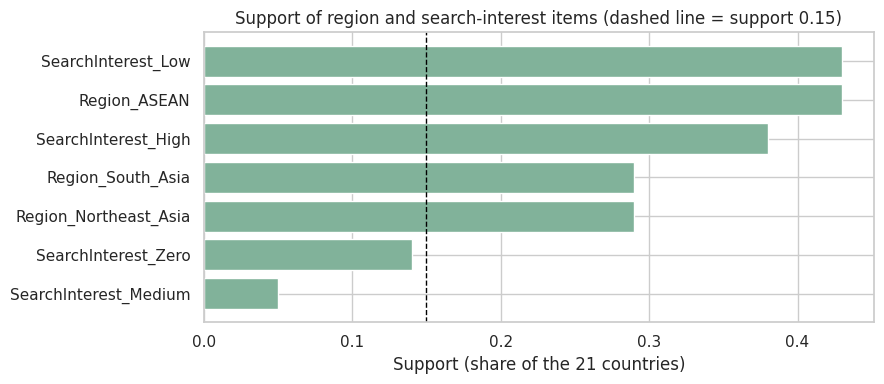

Age and purpose items: 51 | support of every one: [np.float64(0.33)]


In [71]:
items = (rq4_df.select(F.explode("items").alias("item")).groupBy("item").count()
               .withColumn("support", F.round(F.col("count") / 21, 2)).toPandas())
items["group"] = items["item"].str.split("_").str[0]
special = items[items["group"].isin(["Region", "SearchInterest"])].sort_values("support")

plt.figure(figsize=(9, 4))
plt.barh(special["item"], special["support"], color="#81B29A")
plt.axvline(0.15, color="black", linestyle="--", linewidth=1)
plt.title("Support of region and search-interest items (dashed line = support 0.15)")
plt.xlabel("Support (share of the 21 countries)"); plt.tight_layout(); plt.show()

tercile = items[~items["group"].isin(["Region", "SearchInterest"])]
print("Age and purpose items:", len(tercile), "| support of every one:", sorted(tercile["support"].unique()))

**What it shows:**
- Every age and purpose item appears in exactly 7 of 21 countries (support 0.33), because terciles make three equal groups.
- `SearchInterest_Zero` (3 countries) and `SearchInterest_Medium` (1) fall below 0.15, so rules can only mention high or low search interest.

#### Region vs. Search Interest (Spark Pivot)
This table uses a Spark `pivot` to count how many countries in each region fall into each search-interest level. It gives an early hint of rules FP-Growth may find.

In [72]:
(rq4_df.select("country", F.explode("items").alias("item"))
       .filter(F.col("item").startswith("SearchInterest_"))
       .join(master_df.select("country", "region"), "country")
       .groupBy("region").pivot("item").count().na.fill(0)
       .orderBy("region").show(truncate=False))

+--------------+-------------------+------------------+---------------------+-------------------+
|region        |SearchInterest_High|SearchInterest_Low|SearchInterest_Medium|SearchInterest_Zero|
+--------------+-------------------+------------------+---------------------+-------------------+
|ASEAN         |3                  |3                 |1                    |2                  |
|Northeast_Asia|4                  |2                 |0                    |0                  |
|South_Asia    |1                  |4                 |0                    |1                  |
+--------------+-------------------+------------------+---------------------+-------------------+



**What it shows:** Northeast Asia leans toward high search interest (4 of 6), South Asia toward low (4 of 6), and ASEAN is mixed. FP-Growth may find rules linking region and search interest (RQ4a).

## Model Setup
Each country is one **basket** of 19 items: its region, a Low/Medium/High level for each age and purpose share, and its search-interest level. Each rule reads **IF A THEN B** and is measured by:
- **Support:** share of countries with both A and B (Agrawal et al., 1993).
- **Confidence:** of the countries with A, the share that also have B (Agrawal et al., 1993).
- **Lift:** how much more likely B is when A is present. Above 1 means A and B appear together more than by chance (Brin et al., 1997).

FP-Growth finds frequent item combinations without generating every candidate (Han et al., 2000).

In [73]:
from pyspark.ml.fpm import FPGrowth
import math

baskets = rq4_df.select("country", "items").cache()
N = baskets.count()
print(N, "baskets |", baskets.select(F.size("items")).first()[0], "items in each")
baskets.show(3, truncate=100)

21 baskets | 19 items in each
+-----------------+----------------------------------------------------------------------------------------------------+
|          country|                                                                                               items|
+-----------------+----------------------------------------------------------------------------------------------------+
|Brunei Darussalam|[Region_ASEAN, Under15_High, Age15_19_High, Age20_24_Medium, Age25_34_Low, Age35_44_Low, Age45_54...|
|         Cambodia|[Region_ASEAN, Under15_High, Age15_19_Medium, Age20_24_Medium, Age25_34_High, Age35_44_High, Age4...|
|        Indonesia|[Region_ASEAN, Under15_Low, Age15_19_Low, Age20_24_High, Age25_34_High, Age35_44_Medium, Age45_54...|
+-----------------+----------------------------------------------------------------------------------------------------+
only showing top 3 rows


## Train and Tune
Two settings are tuned: **minSupport** (smallest share of countries a pattern must appear in) and **minConfidence** (smallest confidence a rule must have). We count the rules each pair gives, and how many end in a Region or Search Interest item (RQ4a).

In [74]:
RQ4A_ITEM = "x LIKE 'Region_%' OR x LIKE 'SearchInterest_%'"

tuning = []
for s in [0.15, 0.20, 0.25]:
    for c in [0.6, 0.7, 0.8]:
        m = FPGrowth(itemsCol="items", minSupport=s, minConfidence=c).fit(baskets)
        r = m.associationRules
        tuning.append({"minSupport": s, "min_countries": math.ceil(s * N), "minConfidence": c,
                       "itemsets": m.freqItemsets.count(), "rules": r.count(),
                       "region_rules": r.filter(F.expr("exists(consequent, x -> x LIKE 'Region_%')")).count(),
                       "search_rules": r.filter(F.expr("exists(consequent, x -> x LIKE 'SearchInterest_%')")).count()})
display(pd.DataFrame(tuning))

,minSupport,min_countries,minConfidence,itemsets,rules,region_rules,search_rules
0,0.15,4,0.6,606,1120,70,41
1,0.15,4,0.7,606,1013,62,29
2,0.15,4,0.8,606,909,56,23
3,0.20,5,0.6,156,224,11,6
4,0.20,5,0.7,156,220,11,6
5,0.20,5,0.8,156,116,5,0
6,0.25,6,0.6,72,33,2,0
7,0.25,6,0.7,72,32,2,0
8,0.25,6,0.8,72,32,2,0


**What it shows:**
- **minSupport 0.15** (4 countries) gives about 900–1,100 rules; in 21 countries, a 4-country pattern can easily be chance.
- **minSupport 0.25** leaves no search-interest rules, and **minConfidence 0.8** removes all 6 of them at minSupport 0.2.

**Chosen: minSupport = 0.2 and minConfidence = 0.7.** A pattern must appear in at least 5 countries, and a rule must hold for at least 5 of 7.

In [75]:
MIN_SUPPORT, MIN_CONFIDENCE = 0.2, 0.7
fp_model = FPGrowth(itemsCol="items", minSupport=MIN_SUPPORT, minConfidence=MIN_CONFIDENCE).fit(baskets)

rules = (fp_model.associationRules
    .withColumn("rule", F.concat(F.lit("IF "), F.concat_ws(" + ", "antecedent"),
                                 F.lit("  THEN "), F.concat_ws(" + ", "consequent")))
    .withColumn("countries", F.round(F.col("support") * N).cast("int"))
    .select("rule", "antecedent", "consequent", "countries",
            F.round("support", 2).alias("support"), F.round("confidence", 2).alias("confidence"),
            F.round("lift", 2).alias("lift"))
    .cache())
print("Frequent itemsets:", fp_model.freqItemsets.count(), "| Rules:", rules.count())

Frequent itemsets: 156 | Rules: 220


## Evaluation
Only rules with **lift above 1** are kept, ranked by lift.

Rules with lift > 1: 220 of 220


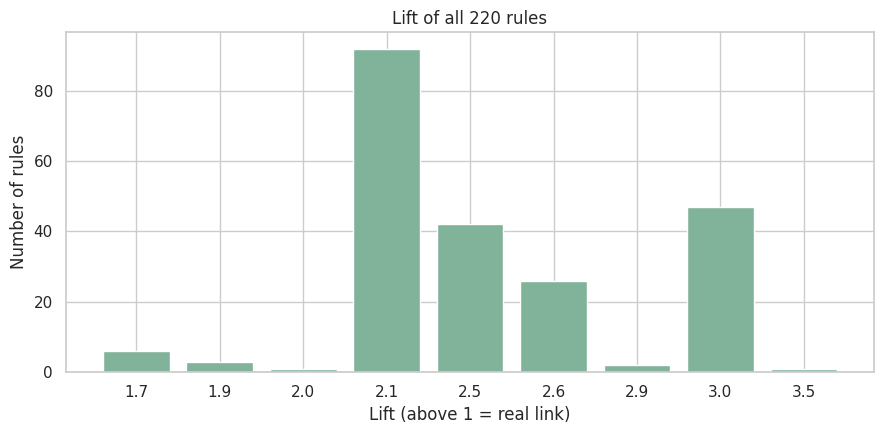

+------------------------------------------------------------+---------+----------+----+
|rule                                                        |countries|confidence|lift|
+------------------------------------------------------------+---------+----------+----+
|IF Under15_High + Convention_Low  THEN Region_Northeast_Asia|5        |1.0       |3.5 |
|IF Region_Northeast_Asia  THEN Convention_Low               |6        |1.0       |3.0 |
|IF Convention_Low  THEN Region_Northeast_Asia               |6        |0.86      |3.0 |
|IF Age25_34_Low + Education_Low  THEN Age55_64_High         |6        |1.0       |3.0 |
|IF Age55_64_High + Age25_34_Low  THEN Education_Low         |6        |1.0       |3.0 |
|IF Age55_64_High + Education_Low  THEN Age25_34_Low         |6        |1.0       |3.0 |
|IF Region_Northeast_Asia + Under15_High  THEN Convention_Low|5        |1.0       |3.0 |
|IF Age45_54_Low + Others_High  THEN Age55_64_Low            |5        |1.0       |3.0 |
|IF Age55_64_High + O

In [76]:
strong = rules.filter("lift > 1").orderBy(F.desc("lift"), F.desc("support"), F.size("antecedent"))
print(f"Rules with lift > 1: {strong.count()} of {rules.count()}")

pdf_rules = strong.toPandas()
lift_counts = pdf_rules["lift"].round(1).value_counts().sort_index()
plt.figure(figsize=(9, 4.5))
plt.bar(lift_counts.index.astype(str), lift_counts.values, color="#81B29A")
plt.xlabel("Lift (above 1 = real link)"); plt.ylabel("Number of rules")
plt.title(f"Lift of all {len(pdf_rules)} rules")
plt.tight_layout(); plt.show()

strong.select("rule", "countries", "confidence", "lift").show(10, truncate=False)

**What it shows:**
- All 220 rules have lift above 1. Most are between 2 and 3; the highest is 3.5.
- Many top rules link age groups to each other, which is expected because shares add up to 100% (Aitchison, 1982).

## Interpretation
#### RQ4a: Rules That Point to a Region or a Search-Interest Level
`which_countries` lists the countries where the whole rule is true.

In [77]:
pdf_baskets = baskets.toPandas()
def which_countries(items):
    return ", ".join(r.country for r in pdf_baskets.itertuples() if set(items) <= set(r.items))

rq4a = (strong.filter(F.expr(f"exists(consequent, x -> {RQ4A_ITEM})"))
        .orderBy(F.desc("lift"), F.size("antecedent")).toPandas())
rq4a["type"] = rq4a["consequent"].apply(lambda c: "Region" if c[0].startswith("Region_") else "Search interest")
rq4a["which_countries"] = rq4a.apply(lambda r: which_countries(list(r["antecedent"]) + list(r["consequent"])), axis=1)
display(rq4a[["type", "rule", "countries", "confidence", "lift", "which_countries"]])

,type,rule,countries,confidence,lift,which_countries
0,Region,IF Under15_High + Convention_Low THEN Region_...,5,1.00,3.50,"China, Japan, South Korea, Macau, Taiwan"
1,Region,IF Convention_Low THEN Region_Northeast_Asia,6,0.86,3.00,"China, Hong Kong, Japan, South Korea, Macau, T..."
2,Region,IF Holiday_High + Convention_Low THEN Region_...,5,0.83,2.92,"Hong Kong, Japan, South Korea, Macau, Taiwan"
3,Region,IF Convention_Low + OfficialMission_Low THEN ...,5,0.83,2.92,"China, Hong Kong, South Korea, Macau, Taiwan"
4,Region,IF Holiday_High THEN Region_Northeast_Asia,5,0.71,2.50,"Hong Kong, Japan, South Korea, Macau, Taiwan"
5,Region,IF Under15_High THEN Region_Northeast_Asia,5,0.71,2.50,"China, Japan, South Korea, Macau, Taiwan"
6,Region,IF OfficialMission_Low THEN Region_Northeast_...,5,0.71,2.50,"China, Hong Kong, South Korea, Macau, Taiwan"
7,Region,IF Convention_Medium THEN Region_ASEAN,6,0.86,2.00,"Brunei Darussalam, Indonesia, Malaysia, Myanma..."
8,Search interest,IF Business_High THEN SearchInterest_High,5,0.71,1.88,"Malaysia, Singapore, Thailand, Hong Kong, India"
9,Search interest,IF Education_Low THEN SearchInterest_High,5,0.71,1.88,"Malaysia, Singapore, Hong Kong, Japan, South K..."


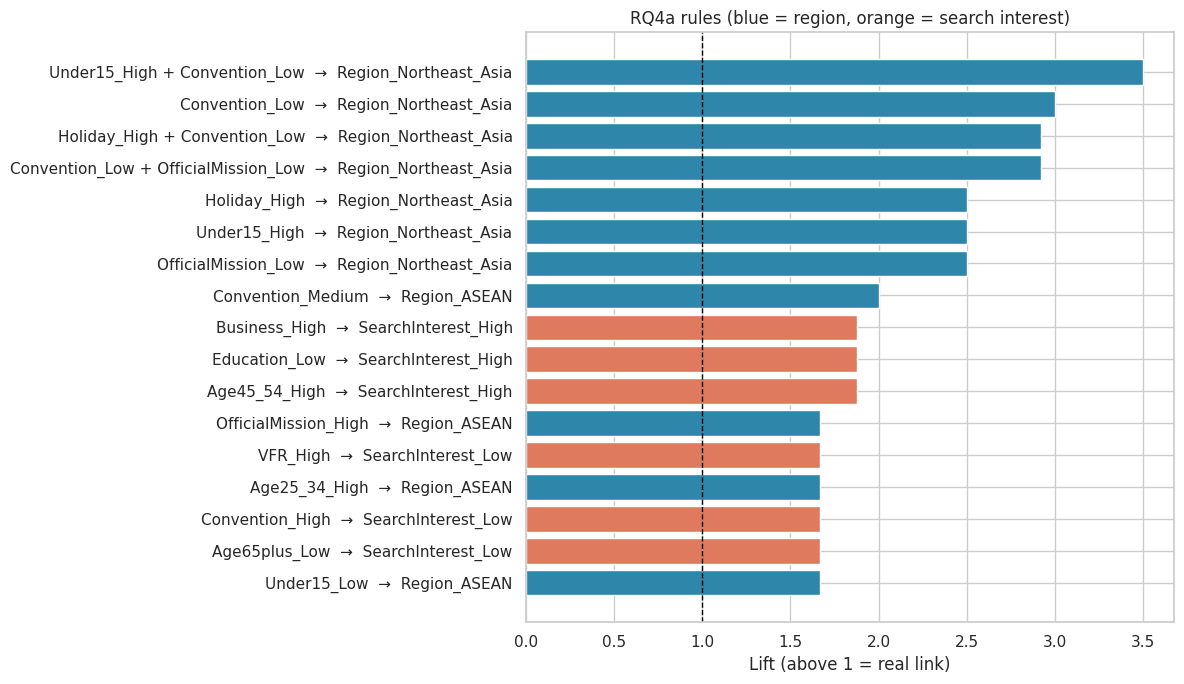

In [78]:
plot_df = rq4a.sort_values("lift")
colors = plot_df["type"].map({"Region": "#2E86AB", "Search interest": "#E07A5F"})
plt.figure(figsize=(12, 7))
plt.barh(plot_df["rule"].str.replace("IF ", "").str.replace("  THEN ", "  →  "), plot_df["lift"], color=colors)
plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.xlabel("Lift (above 1 = real link)")
plt.title("RQ4a rules (blue = region, orange = search interest)")
plt.tight_layout(); plt.show()

**Answer to RQ4:** FP-Growth finds 220 rules, all with lift above 1 (most between 2 and 3). Many link age groups to purposes, such as many children with a high holiday share, and many 25–34 travelers with a high education share, so age and purpose levels clearly travel together across markets.

**Answer to RQ4a:**
- **Northeast Asia:** few convention trips points to Northeast Asia (6 of 7 countries). Adding many children under 15 makes it 5 of 5. Northeast Asia leans toward family leisure travel.
- **ASEAN:** high official-mission share, many 25–34 travelers, and few children point to ASEAN (5–6 of 7 each).
- **South Asia:** no strong rule, matching RQ3, where most of it fell in the mixed group.
- **High search interest** goes with a high business share and many 45–54 travelers (5 of 7 each), matching RQ1.
- **Low search interest** goes with high convention and high VFR shares (5 of 7 each).

These rules show what appears together, not causes, and each rests on 5–6 countries.

## Insights
- **For DOT and the Tourism Promotions Board:** online campaigns fit high-search markets (business-heavy, mid-career). For low-search markets, use partners such as event organizers and embassies. This matches the plan's call for both digital promotion and new markets (Department of Tourism [DOT], 2023).
- **Northeast Asia:** promote family-friendly destinations and packages.
- **ASEAN and convention-heavy markets:** regional meetings and events fit their travel purpose; the plan lists MICE as high-value tourism (DOT, 2023).
- **SDG 8:** using the right channel for each market helps bring in travelers from more countries, so income and jobs do not depend on a few markets.

# Supplementary Analyses

## Risk Monitoring: Market Concentration Risk | Capacity Indicator

**Market concentration: how much depends on a few markets?**
This chart shows the share of the 21 markets' combined arrivals held by the five biggest markets in 2024.

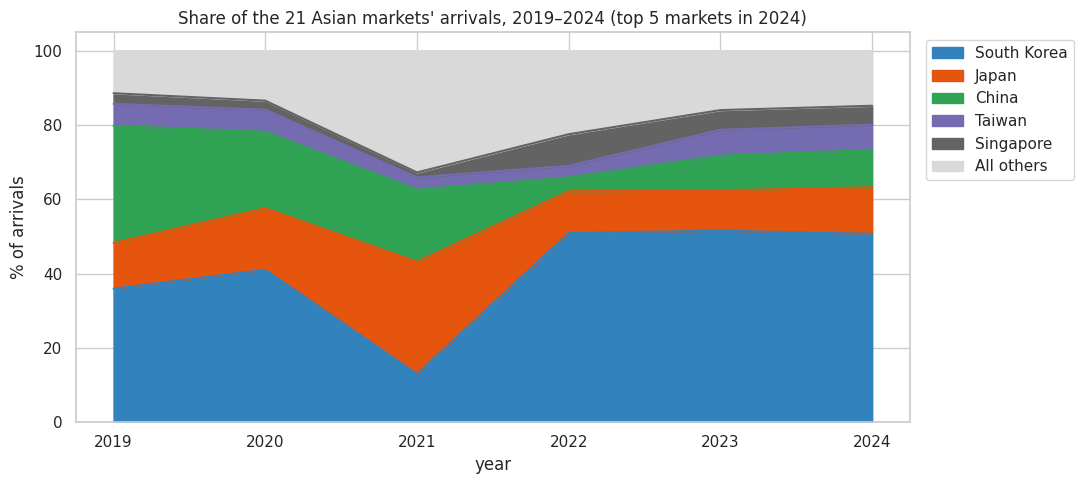

In [79]:
shares = arrivals_long.toPandas().pivot(index="year", columns="country", values="share_pct")
top = shares.loc[2024].sort_values(ascending=False).head(5).index.tolist()
plot_df = shares[top].copy(); plot_df["All others"] = 100 - plot_df.sum(axis=1)
plot_df.plot.area(figsize=(11, 5), colormap="tab20c")
plt.title("Share of the 21 Asian markets' arrivals, 2019–2024 (top 5 markets in 2024)")
plt.ylabel("% of arrivals"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

**What it shows:**
- South Korea's share grew from 36.0% (2019) to 50.7% (2024): half of all arrivals from these 21 markets now come from one country.
- China's share fell from 31.5% to 10.1%.

**Hotel capacity: is Metro Manila running out of rooms?**

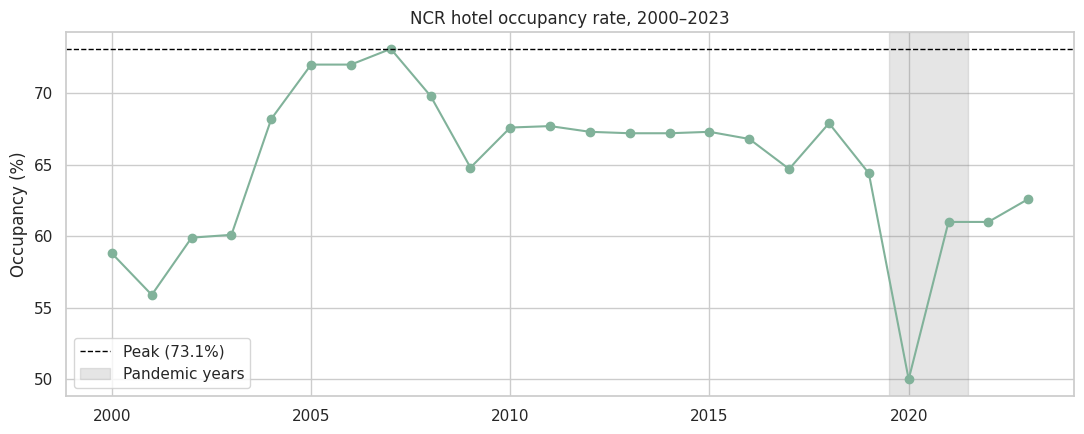

In [80]:
o = occupancy_df.toPandas()
plt.figure(figsize=(11, 4.5))
plt.plot(o["year"], o["occupancy_total_pct"], marker="o", color="#81B29A")
plt.axhline(o["occupancy_total_pct"].max(), color="black", linestyle="--", linewidth=1, label="Peak (73.1%)")
plt.axvspan(2019.5, 2021.5, color="grey", alpha=0.2, label="Pandemic years")
plt.title("NCR hotel occupancy rate, 2000–2023"); plt.ylabel("Occupancy (%)"); plt.legend()
plt.tight_layout(); plt.show()

**What it shows:**
- Occupancy fell to 50.0% in 2020 and reached 62.6% in 2023, still 10.5 points below the 73.1% peak (2007).
- 2021 and 2022 both read exactly 61.0% and should be checked against the DOT source.

**Caution:** this is the share of rooms filled, not guests. Room counts stopped after 2018.

**Seasons: which months are busiest?**
Orange bars mark months with at least one major festival or event.

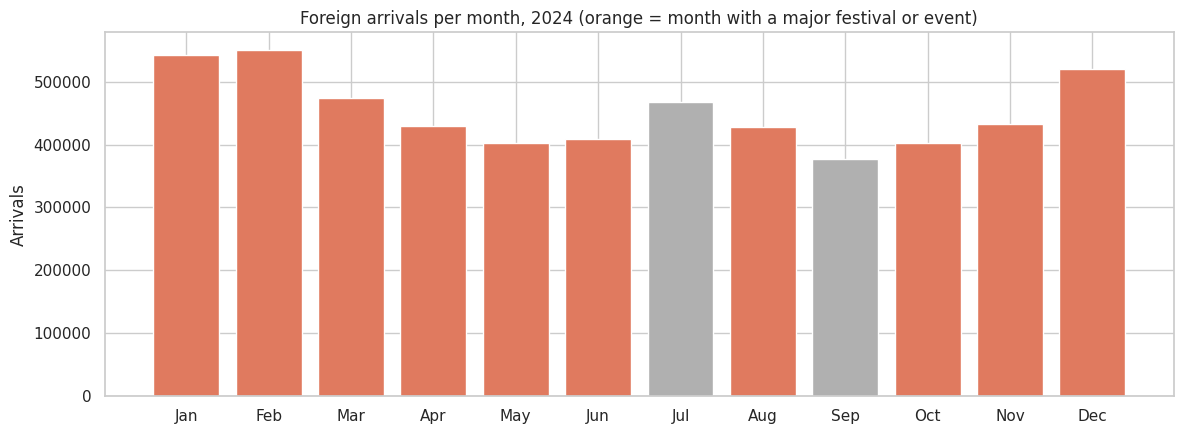

    month  foreign_arrivals  event_count
  January            542066            3
 February            551217            1
    March            474943            1
    April            429516            1
      May            402336            1
     June            408637            1
     July            468016            0
   August            428537            1
September            377003            0
  October            403017            1
 November            433130            2
 December            520549            3


In [81]:
s = seasonal_df.toPandas().sort_values("month_num")
plt.figure(figsize=(12, 4.5))
plt.bar(s["month"].str[:3], s["foreign_arrivals"],
        color=["#E07A5F" if e else "#B0B0B0" for e in s["has_major_event"]])
plt.title("Foreign arrivals per month, 2024 (orange = month with a major festival or event)")
plt.ylabel("Arrivals"); plt.tight_layout(); plt.show()
print(s[["month", "foreign_arrivals", "event_count"]].to_string(index=False))

**What it shows:** the busiest months were February (551,217), January (542,066), and December (520,549); the quietest was September (377,003). Ten of 12 months have a listed event, so festivals alone do not explain the busy months.

### Analysis
**Market concentration (HHI)**
The Herfindahl-Hirschman Index adds up the squared market shares (0 = spread out, 10,000 = one market). Above 2,500 is **highly concentrated** and 1,500–2,500 is moderately concentrated (U.S. Department of Justice & Federal Trade Commission, 2010). `equivalent_markets` = 10,000 ÷ HHI.

In [82]:
# HHI per year
hhi = (arrivals_long.groupBy("year")
       .agg(F.round(F.sum(F.pow("share_pct", 2)), 0).alias("hhi"),
            F.round(F.max("share_pct"), 1).alias("top_market_share_pct"))
       .withColumn("equivalent_markets", F.round(10000 / F.col("hhi"), 1))
       .withColumn("level", F.when(F.col("hhi") > 2500, "High").when(F.col("hhi") >= 1500, "Moderate").otherwise("Low"))
       .orderBy("year"))
hhi.show()

+----+------+--------------------+------------------+--------+
|year|   hhi|top_market_share_pct|equivalent_markets|   level|
+----+------+--------------------+------------------+--------+
|2019|2502.0|                36.0|               4.0|    High|
|2020|2457.0|                41.1|               4.1|Moderate|
|2021|1735.0|                30.2|               5.8|Moderate|
|2022|2900.0|                51.0|               3.4|    High|
|2023|2981.0|                51.6|               3.4|    High|
|2024|2937.0|                50.7|               3.4|    High|
+----+------+--------------------+------------------+--------+



**What it shows:** concentration is **high** and rising: HHI went from 2,502 (2019) to 2,937 (2024), so the 21 markets act like only **3.4 equal-sized markets**.

**Recovery and volatility per market**
`recovery_ratio` = 2024 ÷ 2019 arrivals. `volatility` = standard deviation of yearly log growth, 2019–2024; higher means less stable.

In [83]:
market_risk = (arrivals_long.groupBy("country", "region")
    .agg(F.max(F.when(F.col("year") == 2019, F.col("arrivals"))).alias("arrivals_2019"),
         F.max(F.when(F.col("year") == 2024, F.col("arrivals"))).alias("arrivals_2024"),
         F.round(F.stddev("log_growth"), 2).alias("volatility"))
    .withColumn("recovery_ratio", F.round(F.col("arrivals_2024") / F.col("arrivals_2019"), 2))
    .withColumn("share_2024_pct", F.round(F.col("arrivals_2024") / F.sum("arrivals_2024").over(Window.partitionBy()) * 100, 1))
    .select("country", "region", "share_2024_pct", "recovery_ratio", "volatility")
    .orderBy(F.desc("share_2024_pct")))
market_risk.show(21)

+-----------------+--------------+--------------+--------------+----------+
|          country|        region|share_2024_pct|recovery_ratio|volatility|
+-----------------+--------------+--------------+--------------+----------+
|      South Korea|Northeast_Asia|          50.7|          0.79|      3.04|
|            Japan|Northeast_Asia|          12.6|          0.57|      1.74|
|            China|Northeast_Asia|          10.1|          0.18|       2.2|
|           Taiwan|Northeast_Asia|           6.7|          0.64|      2.59|
|        Singapore|         ASEAN|           5.1|          0.99|      3.05|
|         Malaysia|         ASEAN|           3.1|          0.68|      2.27|
|        Hong Kong|Northeast_Asia|           2.6|          0.86|      2.91|
|            India|    South_Asia|           2.6|          0.59|      1.35|
|          Vietnam|         ASEAN|           1.9|          0.87|      1.91|
|        Indonesia|         ASEAN|           1.8|          0.81|       1.8|
|         Th

**What it shows:** the biggest markets carry the most risk. South Korea (50.7% of arrivals) has one of the highest volatilities (3.04), Japan (12.6%) is at 0.57 recovery, and China (10.1%) at 0.18.

**Hotel capacity (Metro Manila)**

In [84]:
(occupancy_df.groupBy("period")
    .agg(F.min("year").alias("from_year"), F.max("year").alias("to_year"),
         F.round(F.avg("occupancy_total_pct"), 1).alias("avg_occupancy_pct"),
         F.round(F.avg("gap_to_peak_pts"), 1).alias("avg_gap_to_peak_pts"))
    .orderBy("from_year").show())

+------------+---------+-------+-----------------+-------------------+
|      period|from_year|to_year|avg_occupancy_pct|avg_gap_to_peak_pts|
+------------+---------+-------+-----------------+-------------------+
|     Earlier|     2000|   2018|             66.2|                6.9|
|Pre-pandemic|     2019|   2019|             64.4|                8.7|
|    Pandemic|     2020|   2021|             55.5|               17.6|
|    Recovery|     2022|   2023|             61.8|               11.3|
+------------+---------+-------+-----------------+-------------------+



**What it shows:** occupancy averaged 61.8% in 2022–2023, about 11 points below the peak. Metro Manila has spare rooms for more visitors.

### Insights
- **Reduce dependence on one market.** Spreading arrivals across more markets lowers the ups and downs in total demand (Jang & Chen, 2008), and the National Tourism Development Plan calls for new markets "for long-term diversification and resilience" (Department of Tourism [DOT], 2023).
- **Japan and China** are the biggest gaps left to recover.
- **Capacity is not the limit** in Metro Manila; demand is.
- **SDG 8:** a wider market base makes tourism jobs steadier.

## Visitor Behavior Trends: Stay and Spending Trend | Domestic vs. International

**Length of stay and spending over time**
The shaded area marks the pandemic years. These numbers cover all foreign visitors, not only the 21 Asian markets.

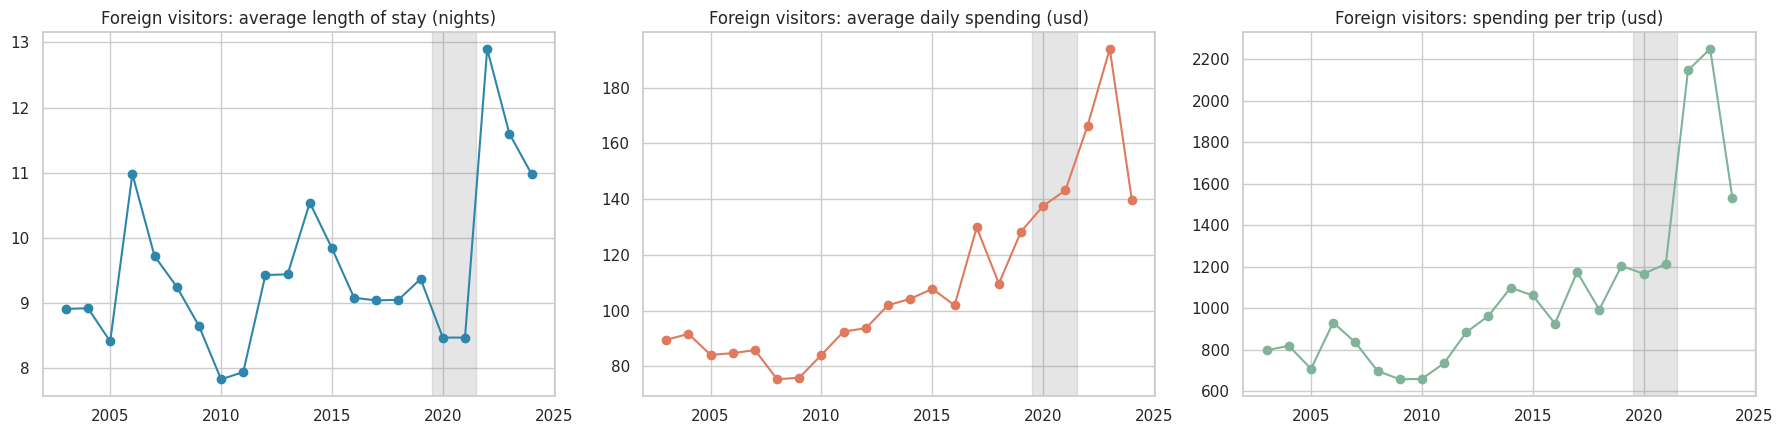

 year       period  fv_avg_stay_nights  fv_avg_daily_exp_usd  fv_spend_per_trip_usd
 2019 Pre-pandemic                9.37                128.35                1202.64
 2020     Pandemic                8.47                137.56                1165.13
 2021     Pandemic                8.47                143.14                1212.40
 2022     Recovery               12.90                166.35                2145.92
 2023     Recovery               11.60                193.92                2249.47
 2024     Recovery               10.98                139.49                1531.60


In [85]:
y = dot85_yearly.toPandas()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title, color in [
        (axes[0], "fv_avg_stay_nights", "Average length of stay (nights)", "#2E86AB"),
        (axes[1], "fv_avg_daily_exp_usd", "Average daily spending (USD)", "#E07A5F"),
        (axes[2], "fv_spend_per_trip_usd", "Spending per trip (USD)", "#81B29A")]:
    ax.plot(y["year"], y[col], marker="o", color=color)
    ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.2)
    ax.set_title(f"Foreign visitors: {title.lower()}")
plt.tight_layout(); plt.show()
print(y[y["year"] >= 2019][["year", "period", "fv_avg_stay_nights", "fv_avg_daily_exp_usd", "fv_spend_per_trip_usd"]].round(2).to_string(index=False))

**What it shows:**
- Visitors stayed 9.37 nights in 2019 and 10.98 in 2024.
- Spending per trip peaked at $2,249 in 2023 and was $1,532 in 2024, still above 2019 ($1,203).

**Data flag:** 2020 and 2021 show the same stay (8.47 nights); the 2021 value was likely copied from 2020.

**Month by month in 2024**

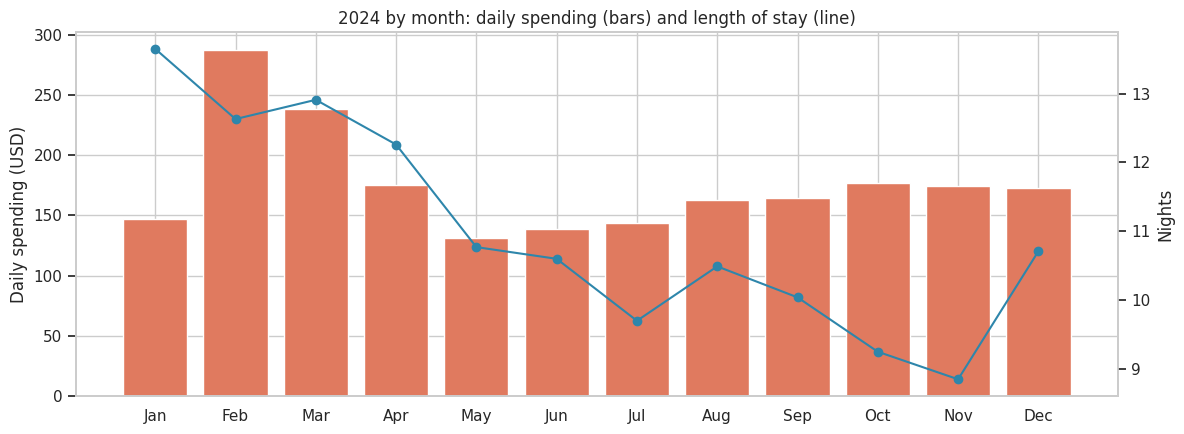

In [86]:
m = dot85_monthly.toPandas()
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(m["month"].str[:3], m["fv_avg_daily_exp_usd"], color="#E07A5F", label="Daily spending (USD)")
ax1.set_ylabel("Daily spending (USD)")
ax2 = ax1.twinx()
ax2.plot(m["month"].str[:3], m["fv_avg_stay_nights"], color="#2E86AB", marker="o", label="Length of stay (nights)")
ax2.set_ylabel("Nights"); ax2.grid(False)
plt.title("2024 by month: daily spending (bars) and length of stay (line)")
plt.tight_layout(); plt.show()

**What it shows:** January to April have the longest stays (12–14 nights). February daily spending ($287.95) is about double most months and should be checked against the DOT source.

**Domestic vs. Asian international travelers**

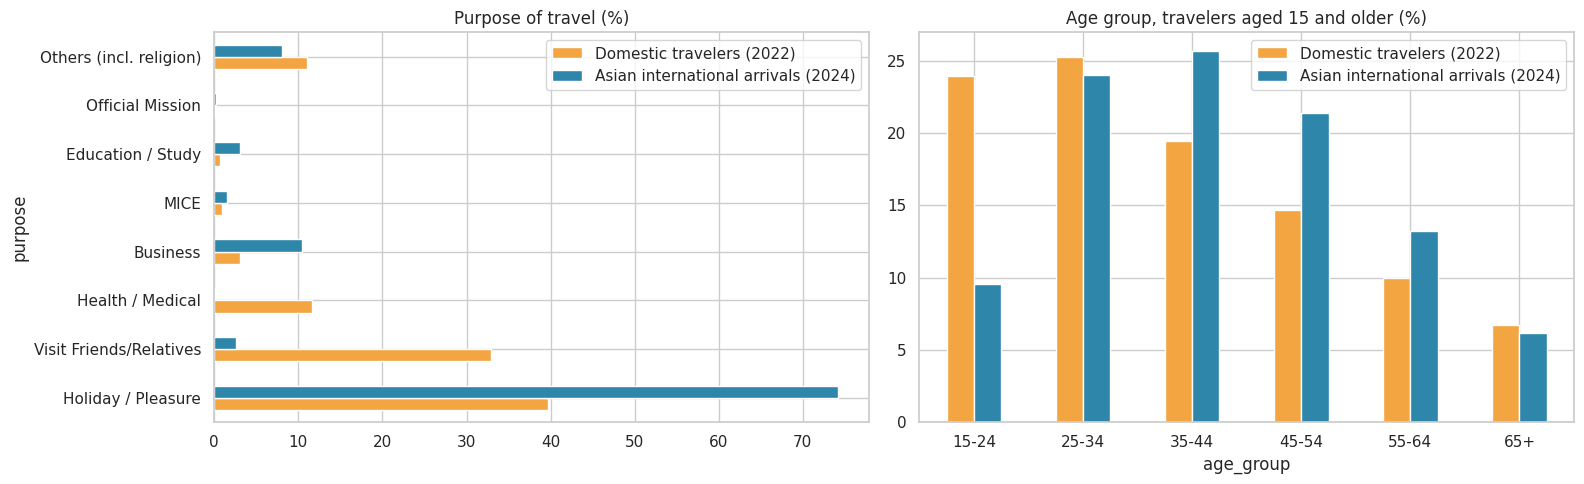

In [87]:
h_p = hsdv_purpose_cmp.toPandas().set_index("purpose")
h_a = hsdv_age_cmp.toPandas().set_index("age_group")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
h_p.plot.barh(ax=axes[0], color=["#F2A541", "#2E86AB"]); axes[0].set_title("Purpose of travel (%)")
h_a.plot.bar(ax=axes[1], color=["#F2A541", "#2E86AB"], rot=0); axes[1].set_title("Age group, travelers aged 15 and older (%)")
for ax in axes: ax.legend(["Domestic travelers (2022)", "Asian international arrivals (2024)"])
plt.tight_layout(); plt.show()

**What it shows:** holiday is 74.2% of Asian international arrivals but 39.7% of domestic trips; visiting friends and relatives is 32.9% of domestic trips but 2.6% of international arrivals (PSA, 2023, 2025). Domestic data is from 2022; international data is from 2024.

### Analysis
**Stay and spending by period (all foreign visitors)**

In [88]:
period_tbl = (dot85_yearly.groupBy("period")
    .agg(F.min("year").alias("from_year"), F.max("year").alias("to_year"),
         F.round(F.avg("fv_avg_stay_nights"), 2).alias("avg_stay_nights"),
         F.round(F.avg("fv_avg_daily_exp_usd"), 2).alias("avg_daily_spend_usd"),
         F.round(F.avg("fv_spend_per_trip_usd"), 0).alias("avg_spend_per_trip_usd"))
    .orderBy("from_year"))
period_tbl.show()

+------------+---------+-------+---------------+-------------------+----------------------+
|      period|from_year|to_year|avg_stay_nights|avg_daily_spend_usd|avg_spend_per_trip_usd|
+------------+---------+-------+---------------+-------------------+----------------------+
|     Earlier|     2003|   2018|           9.19|              94.51|                 870.0|
|Pre-pandemic|     2019|   2019|           9.37|             128.35|                1203.0|
|    Pandemic|     2020|   2021|           8.47|             140.35|                1189.0|
|    Recovery|     2022|   2024|          11.83|             166.59|                1976.0|
+------------+---------+-------+---------------+-------------------+----------------------+



**What it shows:** in 2022–2024, foreign visitors stayed longer (11.8 vs. 9.4 nights in 2019) and spent more per trip ($1,976 vs. $1,203).

**The biggest differences between domestic and Asian international travelers**
`gap_pts` = international share minus domestic share (percentage points).

In [89]:
gaps = (hsdv_purpose_cmp.select(F.lit("Purpose").alias("type"), F.col("purpose").alias("group"), "domestic_pct_2022", "international_asian_pct_2024")
        .unionByName(hsdv_age_cmp.select(F.lit("Age").alias("type"), F.col("age_group").alias("group"), "domestic_pct_2022", "international_asian_pct_2024"))
        .withColumn("gap_pts", F.round(F.col("international_asian_pct_2024") - F.col("domestic_pct_2022"), 1))
        .orderBy(F.desc(F.abs("gap_pts"))))
gaps.show(5, truncate=False)

+-------+-----------------------+-----------------+----------------------------+-------+
|type   |group                  |domestic_pct_2022|international_asian_pct_2024|gap_pts|
+-------+-----------------------+-----------------+----------------------------+-------+
|Purpose|Holiday / Pleasure     |39.71            |74.15                       |34.4   |
|Purpose|Visit Friends/Relatives|32.88            |2.57                        |-30.3  |
|Age    |15-24                  |23.95            |9.56                        |-14.4  |
|Purpose|Health / Medical       |11.6             |0.07                        |-11.5  |
|Purpose|Business               |3.07             |10.45                       |7.4    |
+-------+-----------------------+-----------------+----------------------------+-------+
only showing top 5 rows


**What it shows:** holiday (+34 points for international travelers), visiting friends and relatives (−30), and ages 15–24 (−14) differ most.

### Insights
- **Higher-value stays:** foreign visitors now stay longer and spend more per trip. The National Tourism Development Plan targets long-staying visitors (Department of Tourism [DOT], 2023).
- **Two different markets:** international Asian visitors mostly come for holidays, while domestic travelers more often visit family and are younger, so they need different products.
- **SDG 8 and SDG 12:** more income per visitor means growth does not depend only on more visitors.

## Visitor Experience: Satisfaction Scores | Popular Activities

**Why these five destinations?** They are among the most visited by foreign tourists. In 2024, about 1.9 million foreign visitors went to Cebu and 498,989 to Bohol (SunStar, 2025). Boracay had 341,606 foreign visitors from January to October 2024 (Philippine Daily Inquirer, 2024), and Palawan had 653,567 in 2023 (Reynoso, 2024). Manila is the country's main gateway: its airport handled a record 50.1 million passengers in 2024 (Rosales, 2025).

These figures count all foreign visitors, not only the 21 Asian markets.

**Where the reviews come from**

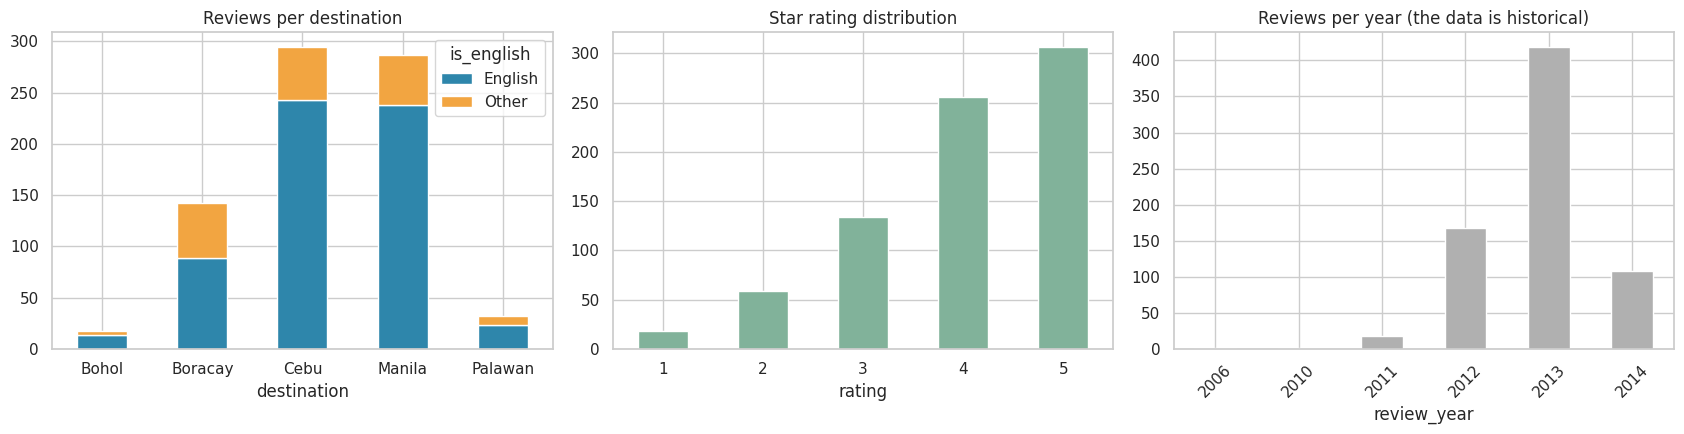

In [90]:
rv = reviews_df.toPandas()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pd.crosstab(rv["destination"], rv["is_english"].map({True: "English", False: "Other"})).plot.bar(
    stacked=True, ax=axes[0], color=["#2E86AB", "#F2A541"], rot=0)
axes[0].set_title("Reviews per destination")
rv["rating"].value_counts().sort_index().plot.bar(ax=axes[1], color="#81B29A", rot=0)
axes[1].set_title("Star rating distribution")
rv["review_year"].dropna().astype(int).value_counts().sort_index().plot.bar(ax=axes[2], color="#B0B0B0", rot=45)
axes[2].set_title("Reviews per year (the data is historical)")
plt.tight_layout(); plt.show()

**What it shows:**
- Cebu (294) and Manila (287) have most reviews; Palawan (32) and Bohol (18) have very few.
- 72.7% of reviews give 4 or 5 stars.
- Most reviews are from 2012–2014, so they show past experiences, not 2024 conditions.

**Ratings and review length by destination**

+-----------+-------+----------+-------------+------------+
|destination|reviews|avg_rating|pct_1_2_stars|median_words|
+-----------+-------+----------+-------------+------------+
|       Cebu|    294|      4.01|          9.2|        11.0|
|     Manila|    287|      3.99|         10.5|        11.0|
|    Boracay|    142|      3.96|         10.6|        10.0|
|    Palawan|     32|      4.25|          6.3|        12.5|
|      Bohol|     18|      3.83|         16.7|        12.5|
+-----------+-------+----------+-------------+------------+



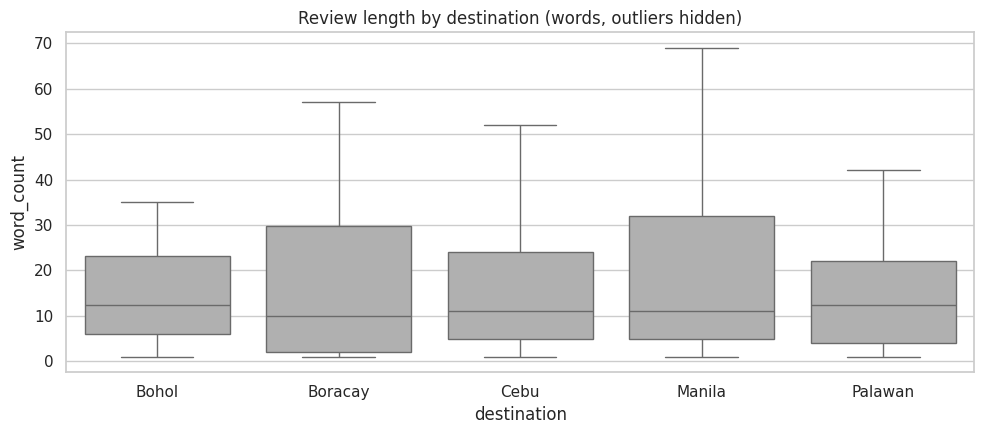

In [91]:
summary = (reviews_df.groupBy("destination")
           .agg(F.count("*").alias("reviews"),
                F.round(F.avg("rating"), 2).alias("avg_rating"),
                F.round(F.avg(F.col("rating").isin(1, 2).cast("int")) * 100, 1).alias("pct_1_2_stars"),
                F.expr("percentile(word_count, 0.5)").alias("median_words"))
           .orderBy(F.desc("reviews")))
summary.show()
rv = reviews_df.toPandas()
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=rv, x="destination", y="word_count", color="#B0B0B0", showfliers=False)
plt.title("Review length by destination (words, outliers hidden)"); plt.tight_layout(); plt.show()

**What it shows:** average ratings range from 3.83 (Bohol) to 4.25 (Palawan), less than half a star apart. The typical review has only 10–12 words, so only the 570 English reviews with 4+ words (`use_for_lda`) are used for the keyword analysis.

### Analysis
**Satisfaction by aspect (keyword-based)**
Each review is checked for keywords about six aspects (for example, "clean," "dirty," and "smell" for cleanliness), a simple form of aspect-based review mining (Hu & Liu, 2004). The average star rating of reviews that mention an aspect shows satisfaction with it.

In [93]:
ASPECTS = {
    "Cleanliness": r"\b(clean|dirty|smell|smelly|dust|dusty|cockroach|bugs?|stain|mold|mouldy|moldy)\b",
    "Staff and service": r"\b(staff|service|friendly|helpful|rude|reception|attentive|polite|accommodating)\b",
    "Price and value": r"\b(price|prices|expensive|cheap|value|worth|overpriced|affordable|budget)\b",
    "Food": r"\b(food|breakfast|restaurant|buffet|dinner|lunch|delicious|meal|meals)\b",
    "Room comfort": r"\b(room|rooms|bed|beds|aircon|shower|bathroom|comfortable|noisy|noise)\b",
    "Location": r"\b(location|located|near|walking|distance|convenient|access)\b",
}
good = reviews_df.filter("use_for_lda")
print("Reviews used:", good.count())

aspect_flags = F.array(*[F.when(F.col("text_clean").rlike(p), F.lit(a)) for a, p in ASPECTS.items()])
aspect_long = (good.withColumn("aspect", F.explode(aspect_flags)).filter(F.col("aspect").isNotNull()))

overall = good.groupBy("destination").agg(F.round(F.avg("rating"), 2).alias("All reviews"))
# Average rating per aspect; blank when fewer than 5 reviews mention it (too few to trust)
aspect_tbl = (aspect_long.groupBy("destination").pivot("aspect", list(ASPECTS))
              .agg(F.when(F.count("rating") >= 5, F.round(F.avg("rating"), 2)))
              .join(overall, "destination").orderBy("destination"))
aspect_tbl.show(truncate=False)
(aspect_long.groupBy("aspect").agg(F.count("*").alias("mentions"), F.round(F.avg("rating"), 2).alias("avg_rating"),
                                    F.round(F.avg(F.col("rating").isin(1, 2).cast("int")) * 100, 1).alias("pct_1_2_stars"))
    .orderBy("avg_rating").show(truncate=False))

Reviews used: 570
+-----------+-----------+-----------------+---------------+----+------------+--------+-----------+
|destination|Cleanliness|Staff and service|Price and value|Food|Room comfort|Location|All reviews|
+-----------+-----------+-----------------+---------------+----+------------+--------+-----------+
|Bohol      |NULL       |3.4              |NULL           |NULL|NULL        |NULL    |3.62       |
|Boracay    |3.78       |4.12             |3.62           |3.92|3.65        |4.18    |3.88       |
|Cebu       |3.75       |3.83             |3.8            |3.86|3.7         |3.79    |3.97       |
|Manila     |3.68       |3.84             |3.97           |4.0 |3.62        |3.7     |4.05       |
|Palawan    |NULL       |4.11             |3.0            |3.5 |3.6         |NULL    |4.0        |
+-----------+-----------+-----------------+---------------+----+------------+--------+-----------+

+-----------------+--------+----------+-------------+
|aspect           |mentions|avg_rati

**What it shows:**
- **Room comfort (3.64) and cleanliness (3.66)** score lowest; about 1 in 5 of those reviews give 1–2 stars.
- **Location (3.92), staff (3.89), and food (3.89)** score highest.
- This matches hotel research: dissatisfied guests mention physical features of the hotel, while satisfied guests mention staff and service (Berezina et al., 2016).

**Popular activities by destination**
Share of each destination's reviews (%) that mention an activity.

In [94]:
ACTIVITIES = {
    "Beach and swimming": r"\b(beach|beaches|swim|swimming|sand|pool|sunset)\b",
    "Diving and snorkeling": r"\b(dive|diving|snorkel|snorkeling|snorkelling)\b",
    "Island hopping and tours": r"\b(island|islands|hopping|tour|tours|boat)\b",
    "Shopping and malls": r"\b(mall|malls|shopping|shop|shops|market)\b",
    "Nightlife": r"\b(bar|bars|nightlife|party|club)\b",
    "Spa and massage": r"\b(spa|massage)\b",
}
activity_tbl = (good.groupBy("destination")
    .agg(F.count("*").alias("reviews"),
         *[F.round(F.avg(F.col("text_clean").rlike(p).cast("int")) * 100, 0).alias(a) for a, p in ACTIVITIES.items()])
    .orderBy(F.desc("reviews")))
activity_tbl.show(truncate=False)

+-----------+-------+------------------+---------------------+------------------------+------------------+---------+---------------+
|destination|reviews|Beach and swimming|Diving and snorkeling|Island hopping and tours|Shopping and malls|Nightlife|Spa and massage|
+-----------+-------+------------------+---------------------+------------------------+------------------+---------+---------------+
|Cebu       |231    |6.0               |0.0                  |0.0                     |7.0               |2.0      |2.0            |
|Manila     |219    |5.0               |5.0                  |1.0                     |5.0               |5.0      |2.0            |
|Boracay    |84     |26.0              |0.0                  |4.0                     |7.0               |12.0     |1.0            |
|Palawan    |23     |17.0              |4.0                  |17.0                    |0.0               |0.0      |0.0            |
|Bohol      |13     |8.0               |0.0                  |0.0    

**What it shows:** Boracay reviews mention the beach (26%) and nightlife (12%); Palawan mentions beaches and island hopping (17% each). Cebu and Manila reviews rarely mention activities.

### Insights
- **For hotels and LGUs:** focus on room upkeep and cleanliness, the weakest aspects. The National Tourism Development Plan calls for stronger accreditation of accommodations (Department of Tourism [DOT], 2023).
- **Promote each destination for what visitors mention:** Boracay for beach and nightlife, Palawan for island hopping.
- **Caution:** reviews are from 2012–2014 and the keyword method is simple, so these are hints to check with newer reviews.
- **SDG 12:** better upkeep improves satisfaction without building more.

## Policy Context: Entry Policy Comparison

**Visa status, recovery, and arrivals**

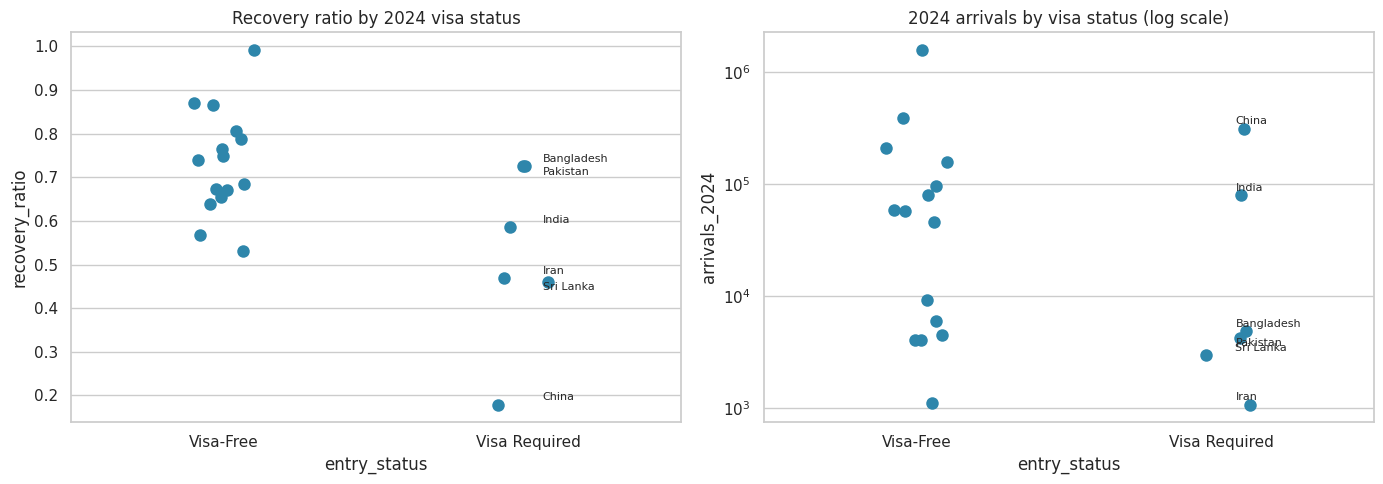

+----------+--------------+--------------------------+----------+------------+
|   country|recovery_ratio|search_interest_index_mean|search_bin|signal_level|
+----------+--------------+--------------------------+----------+------------+
|     China|        0.1791|                      14.2|       Low|      sparse|
| Sri Lanka|        0.4609|                       3.6|       Low|      sparse|
|      Iran|        0.4681|                       0.0|      Zero|        none|
|     India|        0.5853|                      73.8|      High|        full|
|  Pakistan|        0.7254|                       4.3|       Low|      sparse|
|Bangladesh|        0.7261|                      11.5|       Low|      sparse|
+----------+--------------+--------------------------+----------+------------+



In [95]:
e = entry_joined.toPandas()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [(axes[0], "recovery_ratio", "Recovery ratio by 2024 visa status"),
                       (axes[1], "arrivals_2024", "2024 arrivals by visa status (log scale)")]:
    sns.stripplot(data=e, x="entry_status", y=col, order=["Visa-Free", "Visa Required"], size=9, ax=ax, color="#2E86AB")
    req = e[e["entry_status"] != "Visa-Free"]
    label_points(ax, [1.0] * len(req), req[col].tolist(), req["country"].tolist(), dx=10,
                 log_y=(col == "arrivals_2024"))
    ax.set_title(title)
axes[1].set_yscale("log")
plt.tight_layout(); plt.show()
(entry_joined.filter(F.col("entry_status") != "Visa-Free")
    .select("country", "recovery_ratio", "search_interest_index_mean", "search_bin", "signal_level")
    .orderBy("recovery_ratio").show())

**What it shows:** visa-required countries recovered less (median 0.53) than visa-free countries (0.74) and send far fewer visitors. India has high search interest (73.8) but only 0.59 recovery.

### Analysis
**Visa-free vs. visa-required markets (2024 status)**
Medians are used because a few very large markets would distort averages.

In [96]:
policy_tbl = (entry_joined.groupBy("entry_status")
    .agg(F.count("*").alias("countries"),
         F.concat_ws(", ", F.sort_array(F.collect_list("country"))).alias("members"),
         F.expr("percentile(arrivals_2024, 0.5)").cast("int").alias("median_arrivals_2024"),
         F.round(F.expr("percentile(recovery_ratio, 0.5)"), 2).alias("median_recovery"),
         F.round(F.expr("percentile(search_interest_index_mean, 0.5)"), 1).alias("median_search_interest"),
         F.sum("arrivals_2024").alias("total_arrivals_2024"))
    .withColumn("share_of_arrivals_pct", F.round(F.col("total_arrivals_2024") / F.sum("total_arrivals_2024").over(Window.partitionBy()) * 100, 1))
    .drop("total_arrivals_2024"))
policy_tbl.show(truncate=False)

+-------------+---------+-----------------------------------------------------------------------------------------------------------------------------------------------------+--------------------+---------------+----------------------+---------------------+
|entry_status |countries|members                                                                                                                                              |median_arrivals_2024|median_recovery|median_search_interest|share_of_arrivals_pct|
+-------------+---------+-----------------------------------------------------------------------------------------------------------------------------------------------------+--------------------+---------------+----------------------+---------------------+
|Visa Required|6        |Bangladesh, China, India, Iran, Pakistan, Sri Lanka                                                                                                  |4508                |0.53           |7.9           

**What it shows:** the 6 visa-required countries have much lower median arrivals (4,508 vs. 57,085), recovery (0.53 vs. 0.74), and search interest (7.9 vs. 41.6). This matches research showing that visa rules are linked to much less travel between countries (Neumayer, 2010). With only 6 countries, this is a pattern, not proof.

### Insights
- **Easier entry goes with more visitors** (Neumayer, 2010). The Philippines has since allowed visa-free entry for Indian nationals from June 8, 2025 (Department of Foreign Affairs, 2025) and for Chinese nationals from January 16, 2026, through NAIA and Mactan-Cebu (SunStar, 2026). New arrival data can show whether this helps.
- **Low search interest is a second barrier:** visa-required markets also search less, so easier entry should come with promotion.
- **SDG 8:** opening more markets spreads tourism income and jobs.

# Synthesis

## Market Profiles
One row per market, combining its persona (RQ3), purpose segment (RQ2), search-interest level (RQ1/RQ4), recovery since 2019, share of 2024 arrivals, and visa status.

In [97]:
total_2024 = master_df.agg(F.sum("arrivals_2024")).first()[0]
profiles = (master_df.select("country", "region", "arrivals_2024", "recovery_ratio",
                             "search_interest_index_mean", "search_bin", "entry_status")
    .join(clustered.select("country", "persona"), "country")
    .join(rq2_df.select("country", "rq2_segment_label"), "country")
    .withColumn("share_pct", F.round(F.col("arrivals_2024") / total_2024 * 100, 1))
    .select("country", "region", "persona", F.col("rq2_segment_label").alias("purpose_segment"),
            F.col("search_bin").alias("search_level"), F.round("recovery_ratio", 2).alias("recovery"),
            "share_pct", F.col("entry_status").alias("visa_2024"))
    .orderBy("persona", F.desc("share_pct")))
profiles.show(21, truncate=False)

+-----------------+--------------+------------------------------+-------------------------+------------+--------+---------+-------------+
|country          |region        |persona                       |purpose_segment          |search_level|recovery|share_pct|visa_2024    |
+-----------------+--------------+------------------------------+-------------------------+------------+--------+---------+-------------+
|South Korea      |Northeast_Asia|Mature Leisure Markets        |Holiday-dominant         |High        |0.79    |50.7     |Visa-Free    |
|Japan            |Northeast_Asia|Mature Leisure Markets        |Holiday-dominant         |High        |0.57    |12.6     |Visa-Free    |
|Taiwan           |Northeast_Asia|Mature Leisure Markets        |Holiday-dominant         |High        |0.64    |6.7      |Visa-Free    |
|Hong Kong        |Northeast_Asia|Mature Leisure Markets        |Holiday-dominant         |High        |0.87    |2.6      |Visa-Free    |
|Brunei Darussalam|ASEAN         |

**What it shows:**
- **Mature Leisure markets are the core of Philippine tourism.** Six of seven are Holiday-dominant, four have high search interest (South Korea, Japan, Taiwan, Hong Kong), and together they bring most arrivals, led by South Korea (50.7%).
- **Mixed Leisure-Business markets are the most varied, and they hold the biggest gaps.** They span four purpose segments and include five of the six visa-required markets, including China, which has the lowest recovery (0.18). Some still show high search interest (Singapore, Malaysia, India, Thailand), so interest exists even where arrivals lag.
- **Official and MICE, and Young Education markets, are small but steady.** All four are visa-free ASEAN markets with low or zero search interest, yet they recovered well (0.65–0.87). Their travel is driven by events, government, and study, not online vacation searches.

**Takeaway:** each market's profile points to a different action: protect the Mature Leisure base, close the gaps in Mixed markets (recovery and visas), and grow the small personas through partners rather than online ads.

## Answering RQ0
**Answer:** Asian markets differ more by **who travels and why** than by region, and Philippine tourism depends heavily on one type of market. Together, the four methods support planning by **traveler profile**, with a wider spread of markets.

**What each method adds:**
- **RQ1 (Regression):** age and purpose mix predicts which markets show strong online interest (29% less error than the baseline, p ≤ 0.01). Markets with more business travelers and travelers aged 45–54 search more.
- **RQ2 (Classification):** age alone predicts a market's purpose segment better than chance (52.4% vs. 28.6%, p = 0.01). It reliably flags holiday markets (many children and seniors), but not business or family-visit markets.
- **RQ3 (Clustering):** four visitor personas emerge (Mature Leisure, Mixed Leisure-Business, Official and MICE, Young Education), and they **cut across DOT's regions** (purity 0.67).
- **RQ4 (Association Rules):** the same patterns appear as rules. Northeast Asia goes with family leisure travel, ASEAN with official and working-age travel, and high search interest with business-heavy markets.
- **Supplementary:** arrivals are **highly concentrated** (HHI 2,937; South Korea about half), Metro Manila hotels have spare rooms, rooms and cleanliness are the weakest points in reviews, and visa-required markets send fewer visitors.

**The methods agree:** holiday markets with many children and seniors (RQ2, RQ3, RQ4), business-heavy markets with high search interest (RQ1, RQ4), and regions that do not match how people actually travel (RQ3, RQ4).

**SDG links:**
- **SDG 8 (Target 8.9):** relying on one market and one persona puts tourism jobs at risk. Growing the business, MICE, and education personas spreads demand across more markets, in line with the National Tourism Development Plan's diversification goal (Department of Tourism [DOT], 2023; Jang & Chen, 2008).
- **SDG 12 (Target 12.b):** the project shows how open data and Spark can monitor tourism demand by market, as Target 12.b asks (United Nations, 2015). Matching promotion to traveler profiles uses budgets better than one campaign per region.

**Limits:** 21 countries and one year (2024), so the results describe patterns across markets, not forecasts for single countries. Multi-year country data or traveler-level records would make the models stronger.

# References

**Related Literature**
- Agrawal, R., Imieliński, T., & Swami, A. (1993). Mining association rules between sets of items in large databases. In *Proceedings of the 1993 ACM SIGMOD International Conference on Management of Data* (pp. 207–216). ACM. https://doi.org/10.1145/170035.170072
- Aitchison, J. (1982). The statistical analysis of compositional data. *Journal of the Royal Statistical Society: Series B (Methodological), 44*(2), 139–177.
- Arreeras, T., Arimura, M., Asada, T., & Arreeras, S. (2019). Association rule mining tourist-attractive destinations for the sustainable development of a large tourism area in Hokkaido using Wi-Fi tracking data. *Sustainability, 11*(14), 3967. https://doi.org/10.3390/su11143967
- Bahmani, B., Moseley, B., Vattani, A., Kumar, R., & Vassilvitskii, S. (2012). Scalable k-means++. *Proceedings of the VLDB Endowment, 5*(7), 622–633. https://doi.org/10.14778/2180912.2180915
- Berezina, K., Bilgihan, A., Cobanoglu, C., & Okumus, F. (2016). Understanding satisfied and dissatisfied hotel customers: Text mining of online hotel reviews. *Journal of Hospitality Marketing & Management, 25*(1), 1–24. https://doi.org/10.1080/19368623.2015.983631
- Bischoff, E. E., & Koenig-Lewis, N. (2007). VFR tourism: The importance of university students as hosts. *International Journal of Tourism Research, 9*(6), 465–484. https://doi.org/10.1002/jtr.618
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Brin, S., Motwani, R., Ullman, J. D., & Tsur, S. (1997). Dynamic itemset counting and implication rules for market basket data. *ACM SIGMOD Record, 26*(2), 255–264. https://doi.org/10.1145/253262.253325
- Dergiades, T., Mavragani, E., & Pan, B. (2018). Google Trends and tourists' arrivals: Emerging biases and proposed corrections. *Tourism Management, 66*, 108–120.
- Dolnicar, S. (2004). Beyond "commonsense segmentation": A systematics of segmentation approaches in tourism. *Journal of Travel Research, 42*(3), 244–250. https://doi.org/10.1177/0047287503258830
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Han, J., Pei, J., & Yin, Y. (2000). Mining frequent patterns without candidate generation. In *Proceedings of the 2000 ACM SIGMOD International Conference on Management of Data* (pp. 1–12). ACM. https://doi.org/10.1145/342009.335372
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Hu, M., & Liu, B. (2004). Mining and summarizing customer reviews. In *Proceedings of the Tenth ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 168–177). ACM. https://doi.org/10.1145/1014052.1014073
- Jang, S., & Chen, M.-H. (2008). Financial portfolio approach to optimal tourist market mixes. *Tourism Management, 29*(4), 761–770. https://doi.org/10.1016/j.tourman.2007.09.003
- Jauhari, A., Anamisa, D. R., & Mufarroha, F. A. (2022). Analysis of clusters number effect based on K-means method for tourist attractions segmentation. *Journal of Physics: Conference Series, 2406*(1), 012024. https://doi.org/10.1088/1742-6596/2406/1/012024
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801
- Kuncheva, L. I. (2004). *Combining pattern classifiers: Methods and algorithms*. Wiley. https://doi.org/10.1002/0471660264
- Lichy, J., & McLeay, F. (2018). Bleisure: Motivations and typologies. *Journal of Travel & Tourism Marketing, 35*(4), 517–530. https://doi.org/10.1080/10548408.2017.1364206
- Meng, X., Bradley, J., Yavuz, B., Sparks, E., Venkataraman, S., Liu, D., Freeman, J., Tsai, D. B., Amde, M., Owen, S., Xin, D., Xin, R., Franklin, M. J., Zadeh, R., Zaharia, M., & Talwalkar, A. (2016). MLlib: Machine learning in Apache Spark. *Journal of Machine Learning Research, 17*(34), 1–7.
- Neumayer, E. (2010). Visa restrictions and bilateral travel. *The Professional Geographer, 62*(2), 171–181. https://doi.org/10.1080/00330121003600835
- Ntaliakouras, N., Vonitsanos, G., Kanavos, A., & Dritsas, E. (2019). An Apache Spark methodology for forecasting tourism demand in Greece. In *2019 10th International Conference on Information, Intelligence, Systems and Applications (IISA)*. IEEE. https://doi.org/10.1109/IISA.2019.8900739
- Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research, 11*, 1833–1863.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Ramadhani, D. P., Alamsyah, A., Atmaja, M. N., & Panjaitan, J. N. C. G. (2021). Mapping complex tourist destination preferences: Network perspectives. In *2021 9th International Conference on Information and Communication Technology (ICoICT)* (pp. 215–220). IEEE. https://ieeexplore.ieee.org/document/9527445
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management, 45*(4), 427–437. https://doi.org/10.1016/j.ipm.2009.03.002
- Steinbach, M., Karypis, G., & Kumar, V. (2000). A comparison of document clustering techniques. In *KDD Workshop on Text Mining*.
- Thorndike, R. L. (1953). Who belongs in the family? *Psychometrika, 18*(4), 267–276. https://doi.org/10.1007/BF02289263
- Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91
- Wold, S., Sjöström, M., & Eriksson, L. (2001). PLS-regression: A basic tool of chemometrics. *Chemometrics and Intelligent Laboratory Systems, 58*(2), 109–130. https://doi.org/10.1016/S0169-7439(01)00155-1
- Yang, Y., Fan, Y., Jiang, L., & Liu, X. (2022). Search query and tourism forecasting during the pandemic: When and where can digital footprints be helpful as predictors? *Annals of Tourism Research, 93*, 103365. https://doi.org/10.1016/j.annals.2022.103365
- Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B (Statistical Methodology), 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x

**Data Sources and Other References**
- Department of Foreign Affairs. (2025, June 7). *Visa-free privileges for Indian nationals entering the Philippines*. https://dfa.gov.ph/dfa-news/statements-and-advisoriesupdate/36660-visa-free-privileges-for-indian-nationals-entering-the-philippines
- Department of Foreign Affairs. (n.d.). *Philippine e-Visa: Free to enter the Philippines without visa*. Retrieved September 18, 2026, from https://evisa.gov.ph
- Department of Tourism. (2023). *National Tourism Development Plan 2023–2028*. Department of Tourism, Republic of the Philippines.
- Google. (n.d.). *FAQ about Google Trends data*. Retrieved October 14, 2026, from https://support.google.com/trends/answer/4365533
- Google. (n.d.). *Google Trends*. Retrieved September 30, 2026, from https://trends.google.com
- He, R., Kang, W.-C., & McAuley, J. (2017). Translation-based recommendation. In *Proceedings of the 11th ACM Conference on Recommender Systems (RecSys '17)*. ACM.
- Pasricha, R., & McAuley, J. (2018). Translation-based factorization machines for sequential recommendation. In *Proceedings of the 12th ACM Conference on Recommender Systems (RecSys '18)*. ACM.
- Philippine Daily Inquirer. (2024). *Boracay tourism dips from 1.79M to 1.72M*. https://plus.inquirer.net/?p=189044
- Philippine Statistics Authority. (2023). *2022 Household Survey on Domestic Visitors: Statistical tables and technical notes*. https://psa.gov.ph
- Philippine Statistics Authority. (2025). *2025 Philippine Statistical Yearbook: Chapter 8, Tourism*. https://psa.gov.ph/philippine-statistical-yearbook
- Reynoso, I. (2024, January 18). Palawan posts almost 90% rise in tourist arrivals in 2023. *Philippine News Agency*. https://alpha.pna.gov.ph/articles/1217233
- Rosales, E. F. (2025, January 3). NAIA passengers breach 50 million mark, highest on record. *The Philippine Star*. https://www.philstar.com/business/2025/01/03/2411412/naia-passengers-breach-50-million-mark-highest-record
- SunStar. (2026, January 16). *PH grants 14-day visa-free travel to Chinese tourists*. https://www.sunstar.com.ph/cebu/ph-grants-14-day-visa-free-travel-to-chinese-tourists
- SunStar. (2025, March 4). *Central Visayas logs 7.5M tourists in 2024*. https://www.sunstar.com.ph/cebu/central-visayas-logs-75m-tourists-in-2024
- Technological Institute of the Philippines. (2025). *Data Science and Analytics Department research agenda, S.Y. 2024–2029* (TIP-ARU-026).
- United Nations. (2015). *Transforming our world: The 2030 Agenda for Sustainable Development* (A/RES/70/1).
- U.S. Department of Justice & Federal Trade Commission. (2010). *Horizontal merger guidelines*.